# Is ESC better than a fixed fuel ratio $r = 0.5$?

**Question.** Does the extremum seeking controller (ESC) give more fusion energy than simply keeping the fuel ratio
at $r = 0.5$? Two separate questions:
1. Does ESC **win more often** than it loses?
2. Do its **wins outweigh its losses**, or could a few large losses cancel many small wins?

**Data.** The crossed data set in `data/OTO-crossed/` (made by `generators/OTO_ESC_crossed.py`): every one of 2,005 ESC
parameter sets $(k, a, f)$ was run on every one of 600 plants. This notebook uses the 13 blocks with a *steady start*
(the plasma is already running at $r = 0.5$ and the ESC starts at $\hat r = 0.5$): `static`, `exp1`, `exp2`, `timescale`,
`linear`, `step`, `sine`, `random1` ... `random6`. Together that is 600 plants $\times$ 2,005 sets = 1,203,000 runs of
100 s with time step 0.01 s. All numbers below use all of these runs; only the points drawn in scatter plots are a random
subset. The blocks `from0.3`, `from0.7` and `dt0.002` are not used here.

* **ESC sets.** Sets 0-4 are the five sets chosen in `OTO-ESC_fix.ipynb` (the reference set $k = 1$, $a = 0.2$, $f = 6$ Hz,
  and four fast or energy-optimal ones). Sets 5-2004 are quasi-random (Halton): $k$ log-uniform in $10^{-3}$...5,
  $a$ in 0.005...0.6, $f$ in 0.5...10 Hz.
* **Plants.** Seven families: static (41), exponential drift (72), other time scale (30), linear drift (30), step (36),
  sine (27) and random exponential drift as in all earlier sweeps (364). `offset_rms` is the root mean square of
  $r_\mathrm{ideal}(t) - 0.5$ over the run: how far the plant is from what the fixed ratio assumes.

**Definitions.** Energy $E = \int n_D n_T\,dt$ over the run (its typical size is printed in Section 0).
* **margin** $= E_\mathrm{ideal} - E_{r=0.5}$: what there is to gain over the fixed ratio. It depends on the plant only
  ($E_\mathrm{ideal}$: the ratio follows $r_\mathrm{ideal}(t)$ exactly).
* **shortfall** $= E_\mathrm{ideal} - E_\mathrm{ESC}$: what the ESC loses compared with perfect tracking (the dither, the
  time to converge, the lag behind a moving optimum).
* **gain** $= E_\mathrm{ESC} - E_{r=0.5} = $ margin $-$ shortfall. ESC **wins** a run when gain $> 0$. A difference of
  one unit is a tiny fraction of the energy (printed in Section 0) and means nothing in practice, so we also count a **tie band** $|\mathrm{gain}| \le 1$
  unit separately: *clear win* gain $> 1$, *tie*, *clear loss* gain $< -1$.
* **energy score** $\eta = $ gain / margin (1 = as good as perfect tracking, 0 = as good as $r = 0.5$). Only for plants with a
  margin above a floor of 1 unit, because plants with $r_\mathrm{ideal} = 0.5$ have margin 0.
* **Averaged-ESC quantities** (report, Sec. 3.2): the convergence rate $\lambda_\mathrm{avg}$ [1/s] and the predicted energy
  lost to the dither $L_\mathrm{dith}$, both computed with each plant's own mean loss rate $\bar\alpha$ (the time-scale
  family has other loss rates). A run is **well tuned** when $0.1 < \lambda_\mathrm{avg} < 3$ 1/s and $L_\mathrm{dith} < 1$
  (`esc.well_tuned`); a set is well tuned when this holds on all 600 plants.
* **Break-even distance** $\delta^* = \sqrt{L_\mathrm{dith}/13{,}225}$. The fixed ratio loses about
  $T n_\mathrm{ref}^2 \langle (r_\mathrm{ideal} - 0.5)^2\rangle = 13{,}225 \times$ offset_rms$^2$, a well-tuned ESC loses about
  $L_\mathrm{dith}$, so ESC should win once the plant is farther than $\delta^*$ from 0.5.

**Important.** The 600 plants are a *design* (chosen families and grids), not a sample from a probability distribution of
real plasmas. Every average "over all plants" depends on this design. That is why results are also given per family, and
why Section 3 integrates over explicitly stated plant distributions.

Bootstrap confidence intervals (95 %) resample the plants with replacement *within each family* (so every replicate has
the same family sizes as the design), 2,000 times.

In [1]:
import sys, pathlib
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / 'Tools' / 'esc_tools.py').exists())
sys.path.insert(0, str(ROOT / 'Tools'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import esc_tools as esc
esc.apply_style()

## 0. Load the data

All 13 steady-start blocks are read and arranged as matrices with one row per ESC set and one column per plant
(the design is balanced: every set ran once on every plant). The margin of each plant comes from the references table
of its own block.

In [2]:
from matplotlib.colors import TwoSlopeNorm
BLOCKS = ['static', 'exp1', 'exp2', 'timescale', 'linear', 'step', 'sine'] + [f'random{i}' for i in range(1, 7)]
sets = esc.read_data('OTO-crossed-sets.csv')
plants = esc.read_data('OTO-crossed-plants.csv').set_index('plant', drop=False)
refs = esc.read_data('OTO-crossed-references.csv')
runs = pd.concat([esc.read_data(f'OTO-crossed-{b}.csv') for b in BLOCKS], ignore_index=True)
runs = runs.sort_values(['set', 'plant']).reset_index(drop=True)
ref = refs[refs['block'].isin(BLOCKS)].set_index('plant').loc[plants.index]     # every plant is in one steady block
n_sets, n_plants = len(sets), len(plants)
assert len(runs) == n_sets * n_plants
assert (runs['plant'].values.reshape(n_sets, n_plants) == np.arange(n_plants)).all()


def matrix(col):
    """A column of the runs table as a (set, plant) matrix."""
    return runs[col].values.reshape(n_sets, n_plants)


gain = matrix('energy_gain')                                    # E_ESC - E_{r=0.5}
margin = (ref['energy_ideal'] - ref['energy_const']).values     # one value per plant
shortfall = margin[None, :] - gain                              # E_ideal - E_ESC
settled = ~np.isnan(matrix('settling_time_0.01'))               # settled within 0.01 of r_ideal
family = plants['family'].values
offset = plants['offset_rms'].values
tau_scale = plants['tau_scale'].values
k, a, f = (sets[c].values for c in esc.ESC_PARAMS)
alpha_bar = esc.ALPHA_BAR / tau_scale                           # each plant's own mean loss rate
lam = esc.lam_avg(k[:, None], f[:, None], alpha_bar[None, :])   # (set, plant)
L_dith = esc.dither_loss(a[:, None], f[:, None], alpha_bar[None, :])
well_tuned_run = esc.well_tuned({'lam_avg': lam, 'L_dith': L_dith})
lam_nom, L_nom = esc.lam_avg(k, f), esc.dither_loss(a, f)       # nominal time scale (570 of the 600 plants)
CHOSEN = sets['chosen'].values[:5].tolist()
TIE = 1.0                                                       # tie band |gain| <= 1 energy unit

print(f'{len(runs):,} runs = {n_sets:,} ESC sets x {n_plants} plants, {len(BLOCKS)} blocks')
print('plants per family:', plants['family'].value_counts().to_dict())
print(f'margin per plant: {margin.min():.3f} to {margin.max():.1f} units; '
      f'{(margin == 0).sum()} plants have r_ideal = 0.5 throughout (margin 0), {(margin <= TIE).sum()} have margin <= {TIE:g}')
print(f'mean energy with r = 0.5 over the plants: {ref["energy_const"].mean():,.0f} units; the tie band of {TIE:g} unit is '
      f'{TIE / ref["energy_const"].mean():.3%} of it')
print(f'gain over all runs: {(gain > 0).mean():.3f} of the runs have gain > 0, {(np.abs(gain) <= TIE).mean():.3f} are ties, '
      f'{(gain < -TIE).mean():.3f} clear losses')

1,203,000 runs = 2,005 ESC sets x 600 plants, 13 blocks
plants per family: {'random': 364, 'exp': 72, 'static': 41, 'step': 36, 'timescale': 30, 'linear': 30, 'sine': 27}
margin per plant: 0.000 to 138.8 units; 4 plants have r_ideal = 0.5 throughout (margin 0), 31 have margin <= 1
mean energy with r = 0.5 over the plants: 3,279 units; the tie band of 1 unit is 0.030% of it
gain over all runs: 0.871 of the runs have gain > 0, 0.110 are ties, 0.088 clear losses


## 1. Claim and metrics

**What and why.** "ESC is better" can mean two different things. ESC can win on most plants and still be worse on
average if its few losses are large, or win rarely but by a lot. So for every ESC set we compute, over the 600 plants:

* **win rate**: fraction of plants with gain $> 0$; and the split into clear win (gain $> 1$), tie ($|$gain$| \le 1$) and
  clear loss (gain $< -1$);
* **mean win size** (mean gain over the plants it wins) and **mean loss size** (mean $-$gain over the plants it loses);
* **total wins / total losses**: sum of all positive gains divided by the sum of all losses (above 1: wins outweigh losses);
* **expected net gain**: mean gain over the plants (wins and losses together);
* **worst loss**: the most negative gain on any plant (no confidence interval: a bootstrap of a minimum is not meaningful).

The sums are computed once per bootstrap replicate with a matrix of plant weights, so the confidence intervals use all
1.2 million runs.

In [3]:
import warnings
warnings.filterwarnings('ignore', message='All-NaN slice')   # sets that never win have no mean win
rng = np.random.default_rng(2026)
N_BOOT = 2000
boot_w = np.zeros((N_BOOT, n_plants))          # how often each plant is drawn in each bootstrap replicate
for fam_name in np.unique(family):             # resample within each family: the design's family sizes are kept
    idx = np.flatnonzero(family == fam_name)
    draws = idx[rng.integers(0, idx.size, size=(N_BOOT, idx.size))]
    for b in range(N_BOOT):
        boot_w[b] += np.bincount(draws[b], minlength=n_plants)

PARTS = {'win': gain > 0, 'loss': gain < 0, 'clear_win': gain > TIE, 'clear_loss': gain < -TIE,
         'win_sum': np.clip(gain, 0, None), 'loss_sum': np.clip(-gain, 0, None), 'gain_sum': gain}
METRICS = ['win rate', 'clear win', 'tie', 'clear loss', 'mean win', 'mean loss', 'wins / losses', 'net gain']


def metrics(s, n):
    """The metrics from the sums s (dict with the keys of PARTS) over n runs; works on arrays of any shape."""
    with np.errstate(invalid='ignore', divide='ignore'):
        return {'win rate': s['win'] / n, 'clear win': s['clear_win'] / n,
                'tie': 1 - (s['clear_win'] + s['clear_loss']) / n, 'clear loss': s['clear_loss'] / n,
                'mean win': s['win_sum'] / s['win'], 'mean loss': s['loss_sum'] / s['loss'],
                'wins / losses': s['win_sum'] / s['loss_sum'], 'net gain': s['gain_sum'] / n}


# per ESC set: point values (sum over the plants) and bootstrap replicates (weighted sums)
point = metrics({key: v.sum(1) for key, v in PARTS.items()}, n_plants)
boot = metrics({key: v.astype(float) @ boot_w.T for key, v in PARTS.items()}, n_plants)     # (set, replicate)
per_set = pd.DataFrame(point)
with np.errstate(invalid='ignore'):
    for key in METRICS:
        lo, hi = np.nanpercentile(np.where(np.isfinite(boot[key]), boot[key], np.nan), [2.5, 97.5], axis=1)
        per_set[key + ' lo'], per_set[key + ' hi'] = lo, hi
per_set['worst loss'] = gain.min(1)
per_set['largest loss'] = np.clip(-gain.min(1), 0, None)

q = per_set[METRICS].quantile([0.25, 0.5, 0.75])
print('Distribution over the 2,005 sets (25 %, median, 75 %):')
for key in METRICS:
    print(f'  {key:14s} {q.loc[0.25, key]:10.4g} {q.loc[0.5, key]:10.4g} {q.loc[0.75, key]:10.4g}')
print(f'{per_set["mean loss"].isna().sum()} sets never lose (no mean loss, wins/losses infinite); '
      f'{per_set["mean win"].isna().sum()} sets never win')
print(f'sets with total wins > total losses: {(per_set["wins / losses"] > 1).sum()} of {n_sets}; '
      f'with expected net gain > 0: {(per_set["net gain"] > 0).sum()}')

Distribution over the 2,005 sets (25 %, median, 75 %):
  win rate             0.88      0.965       0.98
  clear win            0.74     0.8933      0.935
  tie                 0.055    0.07167       0.13
  clear loss       0.001667   0.003333       0.01
  mean win            19.56      26.51      27.03
  mean loss          0.2034     0.5137      1.541
  wins / losses       176.9       1145       3027
  net gain            13.33      23.88      26.19
0 sets never lose (no mean loss, wins/losses infinite); 11 sets never win
sets with total wins > total losses: 1875 of 2005; with expected net gain > 0: 1875


**Set groups.** Besides single sets, we look at three groups:
* *all sets*: the 2,005 sets as sampled (a wide search box that on purpose contains many badly tuned sets);
* *well-tuned*: well tuned on every plant, each with its own $\bar\alpha$ (definition above);
* *robust A*: $\eta \ge 0.9$ on every plant with a margin above the floor of 1 unit.

The two tuned groups are different, not nested: reaching $\eta \ge 0.9$ on every plant needs a fast loop, and a fast loop
leaves the $\lambda_\mathrm{avg}$ window on the fast time-scale plants (printed below).

In [4]:
MARGIN_FLOOR = 1.0
has_margin = margin > MARGIN_FLOOR
eta = gain[:, has_margin] / margin[has_margin]
worst_eta = eta.min(1)
well_tuned_set = well_tuned_run.all(1)
robust_A = worst_eta >= 0.9
GROUPS = {'all sets': np.ones(n_sets, bool), 'well-tuned': well_tuned_set, 'robust A': robust_A}
print(f'{(~has_margin).sum()} plants have margin <= {MARGIN_FLOOR:g} unit and are left out of eta '
      f'({(margin == 0).sum()} of them have margin 0); eta uses the other {has_margin.sum()} plants')
print(f'well-tuned sets (on all 600 plants with their own alpha_bar): {well_tuned_set.sum()}; '
      f'well tuned on the {(tau_scale == 1).sum()} plants with nominal time scale only: {well_tuned_run[:, tau_scale == 1].all(1).sum()}')
print(f'robust A sets (eta >= 0.9 on all {has_margin.sum()} plants): {robust_A.sum()}; '
      f'robust A sets that are also well tuned on every plant: {(robust_A & well_tuned_set).sum()} of {robust_A.sum()}')
fast_plants = tau_scale == 0.5
print(f'robust A sets on the fast time-scale plants (tau_scale 0.5): lambda_avg >= {lam[robust_A][:, fast_plants].min():.2f} 1/s; '
      f'well tuned on all other plants: {well_tuned_run[robust_A][:, ~fast_plants].all(1).sum()} of {robust_A.sum()}')


def group_summary(masks, plant_mask=None):
    """Pooled metrics of groups of sets (all runs of the group's sets on the selected plants), with bootstrap CIs."""
    cols = np.ones(n_plants, bool) if plant_mask is None else plant_mask
    rows = {}
    for name, gm in masks.items():
        sums = {key: v[gm][:, cols].sum(0).astype(float) for key, v in PARTS.items()}      # per plant
        n = gm.sum() * cols.sum()
        pt = metrics({key: s.sum() for key, s in sums.items()}, n)
        bt = metrics({key: boot_w[:, cols] @ s for key, s in sums.items()}, n)
        row = {'sets': int(gm.sum()), 'plants': int(cols.sum())}
        for key in METRICS:
            row[key] = pt[key]
            finite = bt[key][np.isfinite(bt[key])]
            row[key + ' lo'], row[key + ' hi'] = np.percentile(finite, [2.5, 97.5]) if finite.size else (np.nan, np.nan)
        row['worst loss'] = gain[gm][:, cols].min()
        rows[name] = row
    return pd.DataFrame(rows).T


def with_ci(table, keys=('win rate', 'mean win', 'mean loss', 'wins / losses', 'net gain'), digits=3):
    """Readable table: 'value [low, high]' for the keys, other metrics rounded; NaN = never happens."""
    out = pd.DataFrame(index=table.index)
    for col in ['sets', 'plants']:
        if col in table:
            out[col] = table[col].astype(int)
    for key in ['win rate', 'clear win', 'tie', 'clear loss', 'mean win', 'mean loss', 'wins / losses', 'net gain', 'worst loss']:
        if key in keys:
            out[key] = [f'{v:.{digits}g} [{lo:.{digits}g}, {hi:.{digits}g}]' if np.isfinite(v) else 'none'
                        for v, lo, hi in zip(table[key], table[key + ' lo'], table[key + ' hi'])]
        else:
            out[key] = [f'{v:.{digits}g}' if np.isfinite(v) else 'none' for v in table[key]]
    return out


summary = group_summary({**GROUPS, **{name: np.arange(n_sets) == i for i, name in enumerate(CHOSEN)}})
print('Pooled over all 600 plants, 95 % bootstrap intervals in brackets ("none" = the set never loses):')
with_ci(summary)

31 plants have margin <= 1 unit and are left out of eta (4 of them have margin 0); eta uses the other 569 plants
well-tuned sets (on all 600 plants with their own alpha_bar): 204; well tuned on the 570 plants with nominal time scale only: 653
robust A sets (eta >= 0.9 on all 569 plants): 26; robust A sets that are also well tuned on every plant: 0 of 26
robust A sets on the fast time-scale plants (tau_scale 0.5): lambda_avg >= 3.92 1/s; well tuned on all other plants: 21 of 26
Pooled over all 600 plants, 95 % bootstrap intervals in brackets ("none" = the set never loses):


,sets,plants,win rate,clear win,tie,clear loss,mean win,mean loss,wins / losses,net gain,worst loss
all sets,2005,600,"0.871 [0.859, 0.882]",0.802,0.11,0.0881,"22.8 [20.9, 24.8]","54.9 [50.3, 60.1]","2.82 [2.51, 3.15]","12.8 [10.9, 14.8]",-2.24e+03
well-tuned,204,600,"0.985 [0.976, 0.993]",0.943,0.0544,0.00228,"27 [24.7, 29.3]","5.88 [2.91, 12.2]","295 [195, 539]","26.5 [24.2, 28.8]",-806
robust A,26,600,"0.992 [0.985, 0.998]",0.948,0.0517,0,"27 [24.8, 29.3]","0.0311 [0.005, 0.0783]","1.09e+05 [3.9e+04, 1.49e+06]","26.8 [24.5, 29.1]",-0.539
reference,1,600,"0.987 [0.977, 0.995]",0.948,0.0517,0,"27.1 [24.8, 29.4]","0.054 [0.0117, 0.127]","3.71e+04 [1.44e+04, 2.96e+05]","26.7 [24.4, 29]",-0.269
fastest,1,600,"0.988 [0.98, 0.997]",0.945,0.0517,0.00333,"26.8 [24.6, 29.2]","1.82 [0.00335, 4.97]","1.25e+03 [440, 1.29e+06]","26.5 [24.2, 28.8]",-9.94
fastest a>=0.15,1,600,"0.987 [0.977, 0.995]",0.945,0.0517,0.00333,"26.9 [24.6, 29.2]","1.62 [0.0305, 4.27]","1.23e+03 [436, 1.13e+05]","26.5 [24.2, 28.8]",-9.96
fastest f<=3,1,600,"0.988 [0.98, 0.997]",0.945,0.0517,0.00333,"26.7 [24.4, 29]","1.65 [0.0304, 4.43]","1.37e+03 [488, 1.42e+05]","26.4 [24.1, 28.6]",-8.85
best energy a>=0.1,1,600,"0.993 [0.987, 0.998]",0.948,0.0517,0,"27 [24.8, 29.3]","0.0102 [0.000875, 0.0304]","3.95e+05 [1.39e+05, 9.19e+06]","26.8 [24.6, 29.1]",-0.0304


**Per plant family.** The same pooled metrics within each family, for the three groups and the reference set. Because the
families are designed, compare them with each other rather than adding them up.

In [5]:
fam_tables = []
for fam_name in plants['family'].value_counts().index:
    t = group_summary({**GROUPS, 'reference': np.arange(n_sets) == 0}, family == fam_name)
    t.index = pd.MultiIndex.from_product([[fam_name], t.index], names=['family', 'group'])
    fam_tables.append(t)
by_family = pd.concat(fam_tables)
with_ci(by_family, keys=('win rate', 'net gain'))[['plants', 'win rate', 'tie', 'clear loss', 'mean win', 'mean loss',
                                                   'net gain', 'worst loss']]

plants              win rate     tie clear loss  \
family    group                                                         
random    all sets       364  0.875 [0.861, 0.887]   0.118     0.0887   
          well-tuned     364  0.992 [0.985, 0.997]  0.0642   6.73e-05   
          robust A       364      0.998 [0.995, 1]  0.0604          0   
          reference      364  0.989 [0.978, 0.997]  0.0604          0   
exp       all sets        72   0.89 [0.874, 0.905]  0.0839     0.0853   
          well-tuned      72          1 [0.999, 1]       0    0.00034   
          robust A        72              1 [1, 1]       0          0   
          reference       72              1 [1, 1]       0          0   
static    all sets        41  0.888 [0.828, 0.932]  0.0926     0.0736   
          well-tuned      41      0.975 [0.927, 1]  0.0732    0.00012   
          robust A        41      0.976 [0.927, 1]  0.0732          0   
          reference       41      0.976 [0.927, 1]  0.0732          0   
step      all sets        36  0.903 [0.882, 0.922]  0.0701     0.0799   
          well-tuned      36      0.999 [0.999, 1]       0   0.000817   
          robust A        36              1 [1, 1]       0          0   
          reference       36              1 [1, 1]       0          0   
timescale all sets        30   0.789 [0.68, 0.881]   0.156      0.092   
          well-tuned      30  0.897 [0.796, 0.997]  0.0998    0.00294   
          robust A        30          0.9 [0.8, 1]     0.1          0   
          reference       30          0.9 [0.8, 1]     0.1          0   
linear    all sets        30  0.909 [0.884, 0.931]  0.0618     0.0757   
          well-tuned      30              1 [1, 1]       0          0   
          robust A        30              1 [1, 1]       0          0   
          reference       30              1 [1, 1]       0          0   
sine      all sets        27   0.758 [0.644, 0.86]   0.155      0.131   
          well-tuned      27  0.923 [0.837, 0.999]   0.121     0.0443   
          robust A        27              1 [1, 1]   0.111          0   
          reference       27              1 [1, 1]   0.111          0   

                     mean win mean loss             net gain worst loss  
family    group                                                          
random    all sets       22.6      54.8    12.9 [10.3, 15.4]       -561  
          well-tuned     26.2     0.213          26 [23, 29]      -20.6  
          robust A       26.2    0.0145    26.1 [23.1, 29.1]    -0.0445  
          reference      26.4    0.0177        26.1 [23, 29]    -0.0402  
exp       all sets       16.6      64.7    7.67 [4.78, 10.8]       -561  
          well-tuned     21.3      18.8    21.3 [17.8, 24.9]      -22.8  
          robust A       21.4      none      21.4 [18, 25.1]       1.56  
          reference      21.4      none      21.4 [17.9, 25]       1.57  
static    all sets       39.5      56.3      28.9 [18.4, 39]       -558  
          well-tuned     46.3     0.114    45.2 [32.7, 57.3]         -6  
          robust A       46.5    0.0209    45.4 [32.8, 57.5]    -0.0725  
          reference      46.5    0.0677    45.3 [32.8, 57.5]    -0.0677  
step      all sets       22.4      69.8    13.4 [6.47, 21.2]       -561  
          well-tuned     27.5      15.4    27.5 [19.2, 36.6]      -22.7  
          robust A       27.8      none    27.8 [19.4, 36.9]       1.93  
          reference      27.7      none    27.7 [19.3, 36.8]       1.92  
timescale all sets       14.7      52.5  0.591 [-6.04, 6.98]  -2.24e+03  
          well-tuned     18.6      14.2      15.2 [10.6, 20]       -806  
          robust A       18.8    0.0387    16.9 [12.1, 21.7]     -0.539  
          reference      18.7    0.0979    16.8 [12.1, 21.6]     -0.269  
linear    all sets       30.4      71.7    21.1 [10.4, 32.9]       -560  
          well-tuned       36      none      36 [23.5, 49.7]        1.4  
          robust A       36.1      none    36.1 [23.7, 

**Figure 1: how the metrics are distributed over the 2,005 sets.** Grey: all sets; blue: well-tuned; green: robust A.
Histograms with a logarithmic count axis are drawn as outlines.

largest loss of a robust A set on any plant: 0.539 units; of a well-tuned set: 806.4


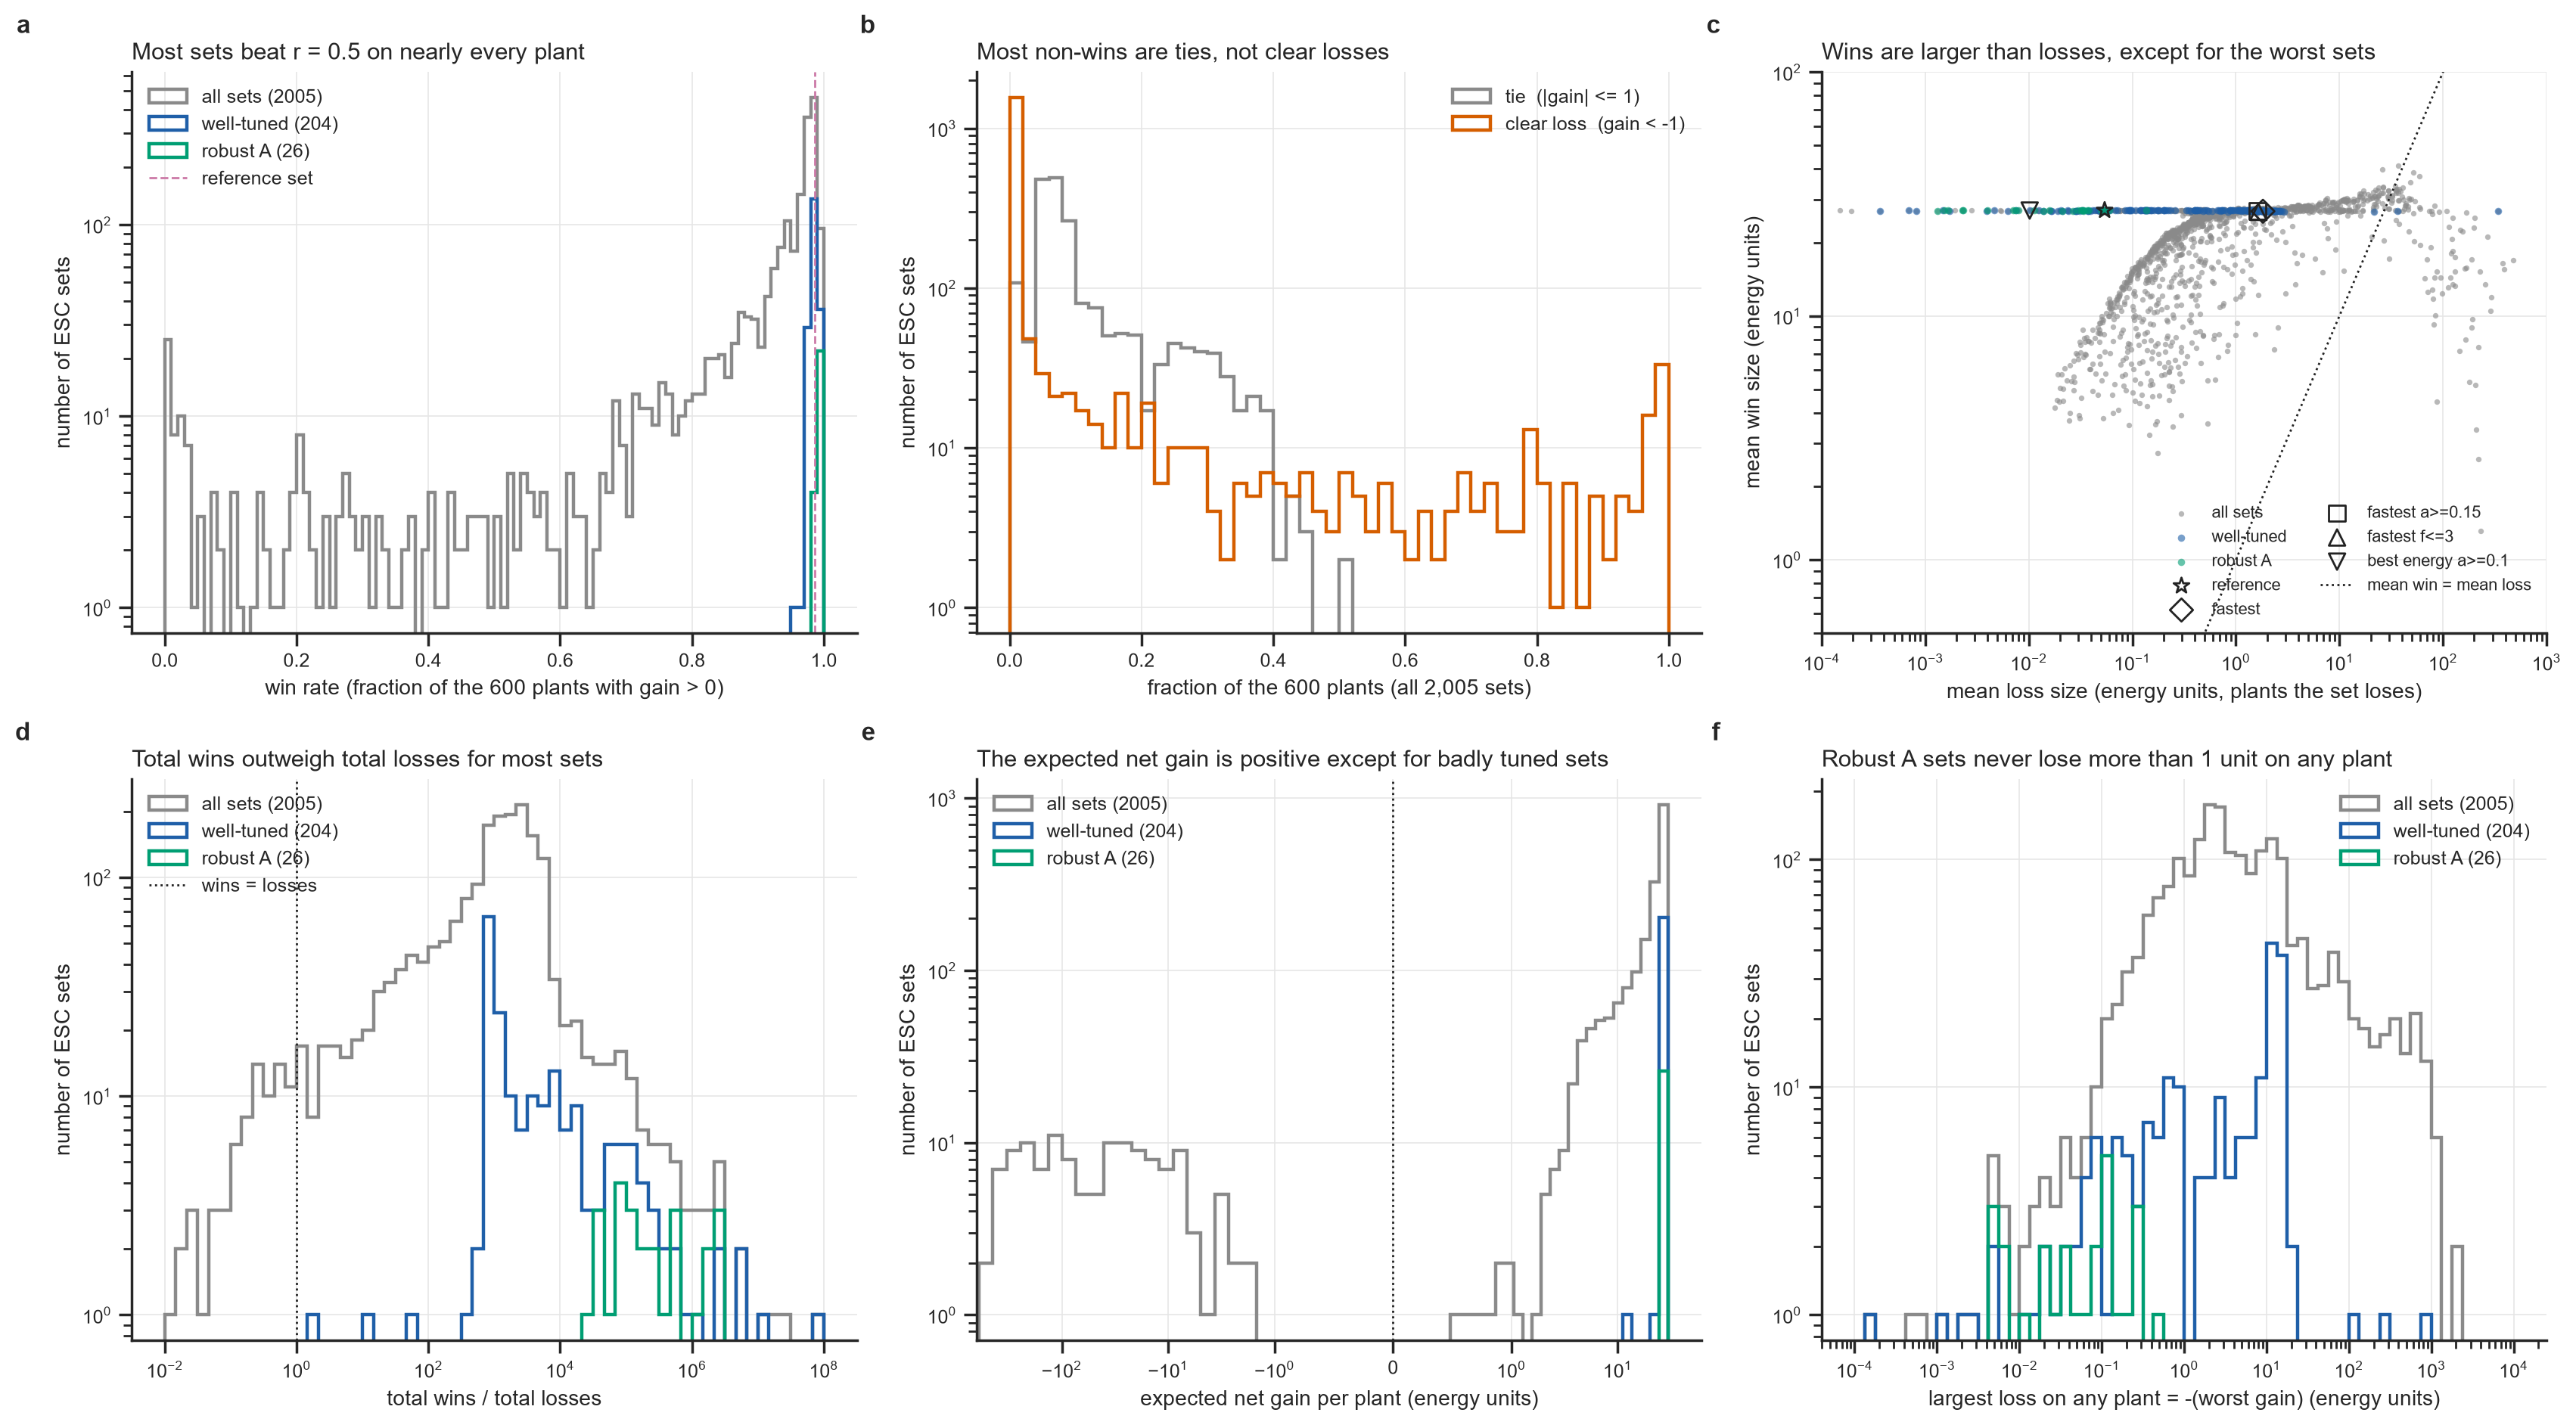

In [6]:
G_COL = {'all sets': esc.COLORS['grey'], 'well-tuned': esc.COLORS['esc'], 'robust A': '#009e73', 'reference': '#cc79a7'}
MARKERS = ['*', 'D', 's', '^', 'v']


def hist_groups(ax, values, bins, log_count=True):
    """Outline histograms of a per-set value for the three groups."""
    for name, gm in GROUPS.items():
        v = values[gm & np.isfinite(values)]
        ax.hist(v, bins=bins, histtype='step', lw=1.6, color=G_COL[name], label=f'{name} ({gm.sum()})')
    if log_count:
        ax.set_yscale('log')
    ax.set_ylabel('number of ESC sets')


def p1_win_rate(ax):
    hist_groups(ax, per_set['win rate'].values, np.linspace(0, 1, 101))
    ax.axvline(per_set.loc[0, 'win rate'], color=G_COL['reference'], ls='--', lw=1, label='reference set')
    ax.set_xlabel('win rate (fraction of the 600 plants with gain > 0)')
    ax.set_title('Most sets beat r = 0.5 on nearly every plant')
    ax.legend(loc='upper left')


def p1_ties(ax):
    bins = np.linspace(0, 1, 51)
    ax.hist(per_set['tie'], bins=bins, histtype='step', lw=1.6, color=esc.COLORS['grey'], label='tie  (|gain| <= 1)')
    ax.hist(per_set['clear loss'], bins=bins, histtype='step', lw=1.6, color=esc.COLORS['bad'], label='clear loss  (gain < -1)')
    ax.set_yscale('log'); ax.set_ylabel('number of ESC sets')
    ax.set_xlabel('fraction of the 600 plants (all 2,005 sets)')
    ax.set_title('Most non-wins are ties, not clear losses')
    ax.legend(loc='upper right')


def p1_win_vs_loss(ax):
    for name, gm in GROUPS.items():
        ax.scatter(per_set.loc[gm, 'mean loss'], per_set.loc[gm, 'mean win'], s=7 if name == 'all sets' else 12,
                   color=G_COL[name], alpha=0.6, linewidths=0, label=name, rasterized=True)
    for i, name in enumerate(CHOSEN):
        if np.isfinite(per_set.loc[i, 'mean loss']):
            ax.scatter(per_set.loc[i, 'mean loss'], per_set.loc[i, 'mean win'], marker=MARKERS[i], s=60,
                       facecolor='none', edgecolor=esc.COLORS['ideal'], lw=1, label=name)
    lim = [1e-4, 1e3]
    ax.plot(lim, lim, color=esc.COLORS['ideal'], ls=':', lw=1, label='mean win = mean loss')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(*lim); ax.set_ylim(0.5, 100)
    ax.set_xlabel('mean loss size (energy units, plants the set loses)')
    ax.set_ylabel('mean win size (energy units)')
    ax.set_title('Wins are larger than losses, except for the worst sets')
    ax.legend(loc='lower right', fontsize=8, ncol=2)


def p1_ratio(ax):
    r = per_set['wins / losses'].values
    hist_groups(ax, np.where(np.isfinite(r) & (r > 0), r, np.nan), np.logspace(-2, 8, 61))
    ax.axvline(1, color=esc.COLORS['ideal'], ls=':', lw=1, label='wins = losses')
    ax.set_xscale('log'); ax.set_xlabel('total wins / total losses')
    ax.set_title('Total wins outweigh total losses for most sets')
    ax.legend(loc='upper left')


def p1_net(ax):
    bins = np.concatenate([-np.logspace(np.log10(600), -1, 30), np.logspace(-1, np.log10(30), 30)])
    hist_groups(ax, per_set['net gain'].values, bins)
    ax.axvline(0, color=esc.COLORS['ideal'], ls=':', lw=1)
    ax.set_xscale('symlog', linthresh=1); ax.set_xlabel('expected net gain per plant (energy units)')
    ax.set_title('The expected net gain is positive except for badly tuned sets')
    ax.legend(loc='upper left')


def p1_worst(ax):
    v = per_set['largest loss'].values
    hist_groups(ax, np.where(v > 0, v, np.nan), np.logspace(-4, 4, 65))
    ax.set_xscale('log'); ax.set_xlabel('largest loss on any plant = -(worst gain) (energy units)')
    ax.set_title('Robust A sets never lose more than 1 unit on any plant')
    ax.legend(loc='upper right')


P1 = [p1_win_rate, p1_ties, p1_win_vs_loss, p1_ratio, p1_net, p1_worst]
fig, axs = plt.subplots(2, 3, figsize=(17, 9.5))
fig.dpi = 200
for ax, panel, letter in zip(axs.flat, P1, 'abcdef'):
    panel(ax); esc.panel_letter(ax, letter)
fig.tight_layout()
plt.show()
print(f'largest loss of a robust A set on any plant: {per_set.loc[robust_A, "largest loss"].max():.3f} units; '
      f'of a well-tuned set: {per_set.loc[well_tuned_set, "largest loss"].max():.1f}')

The same six panels, one per figure:

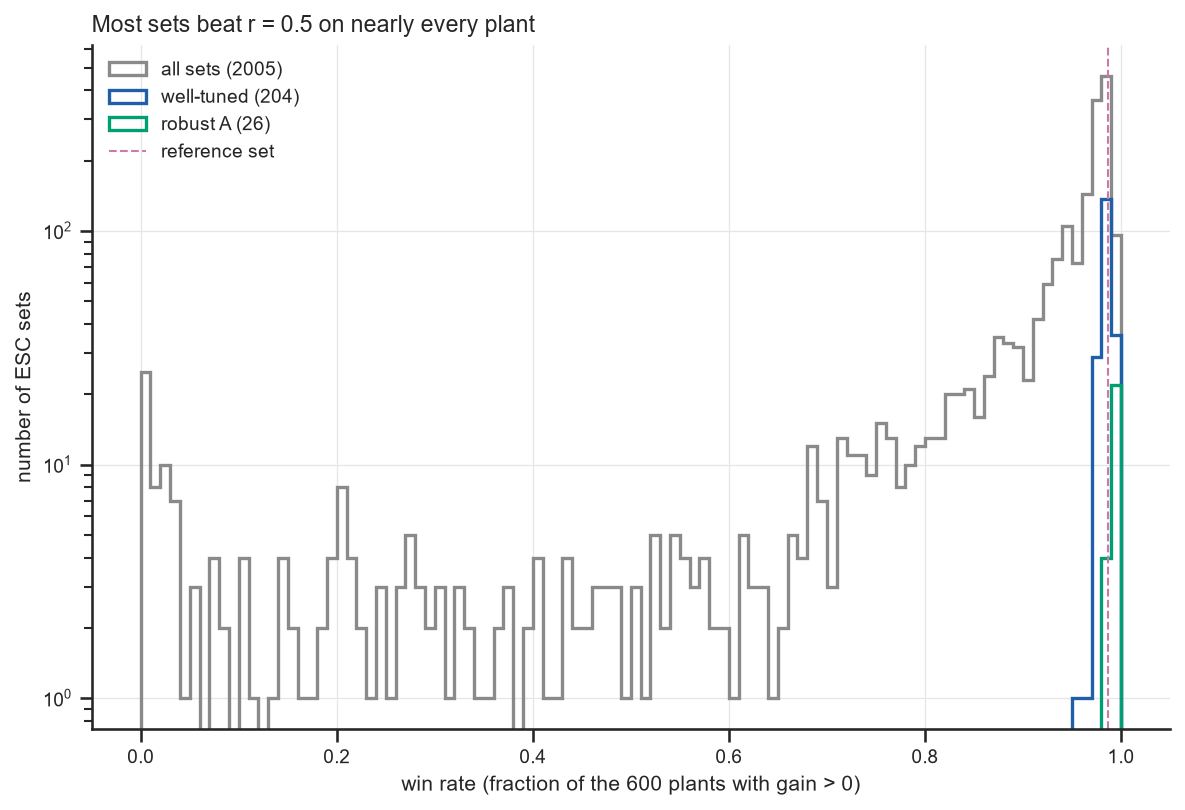

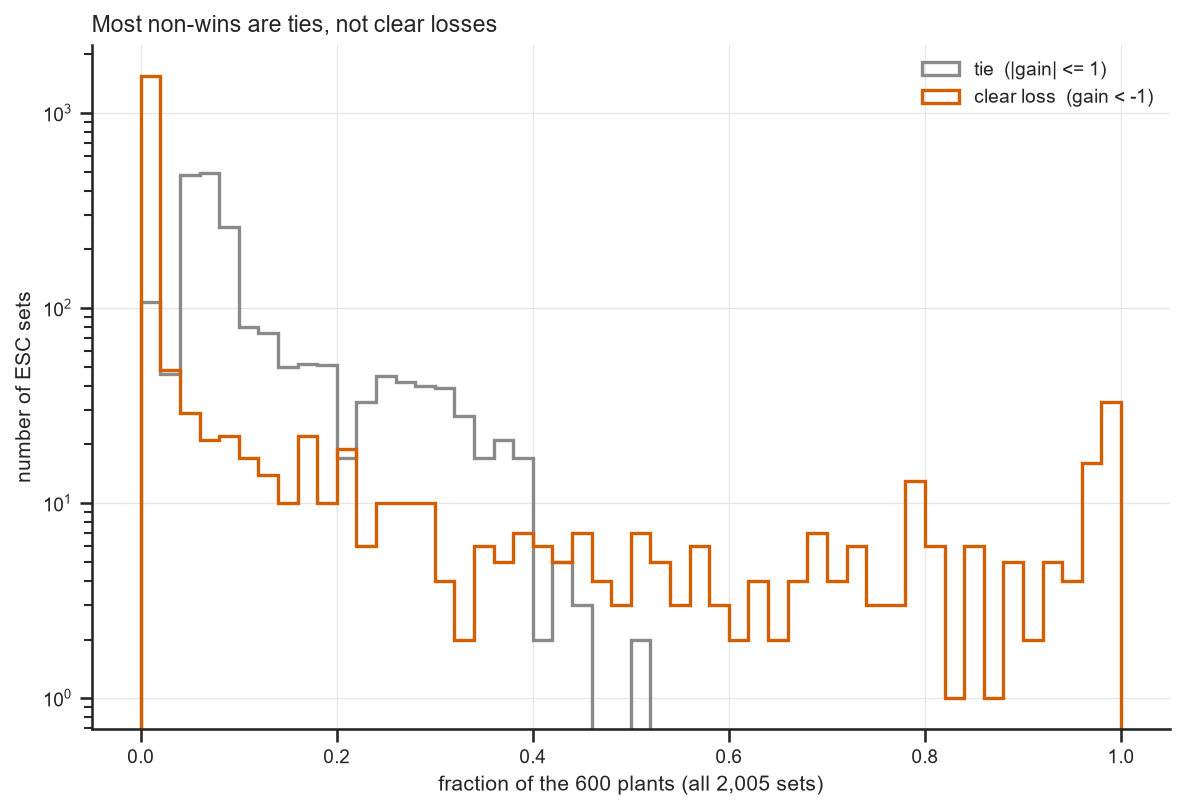

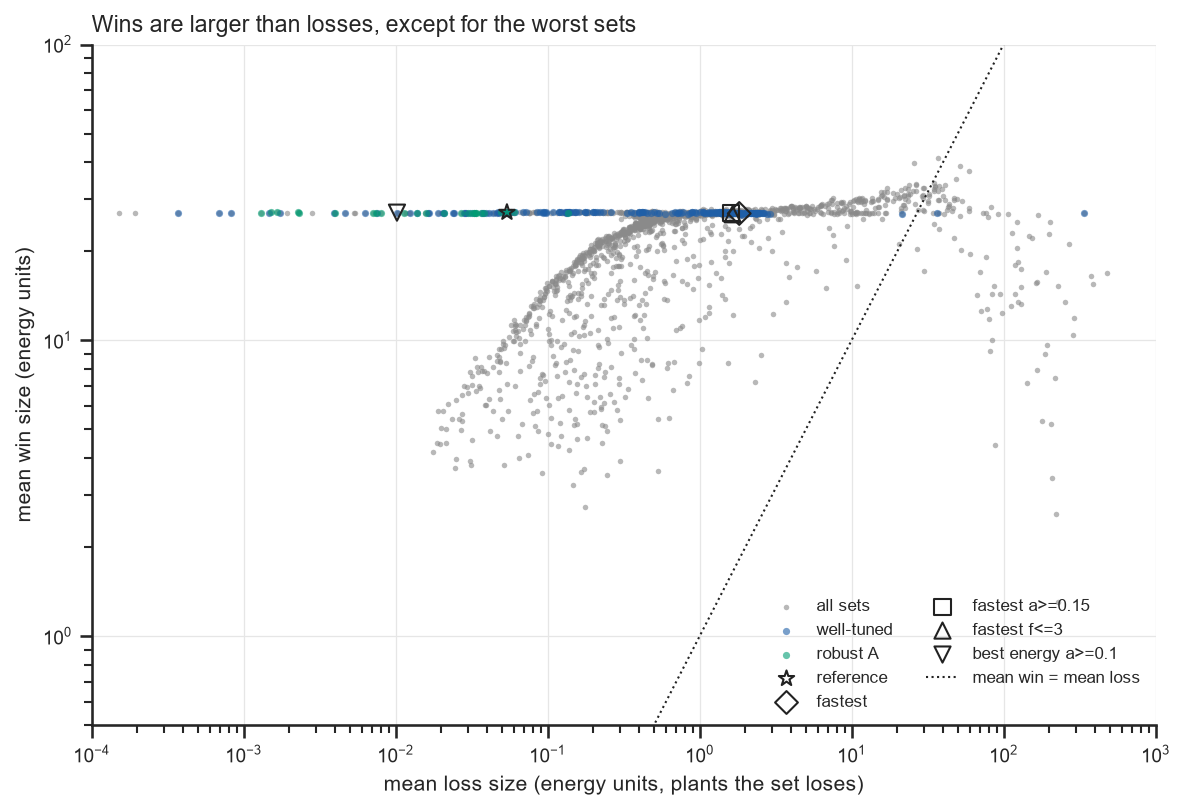

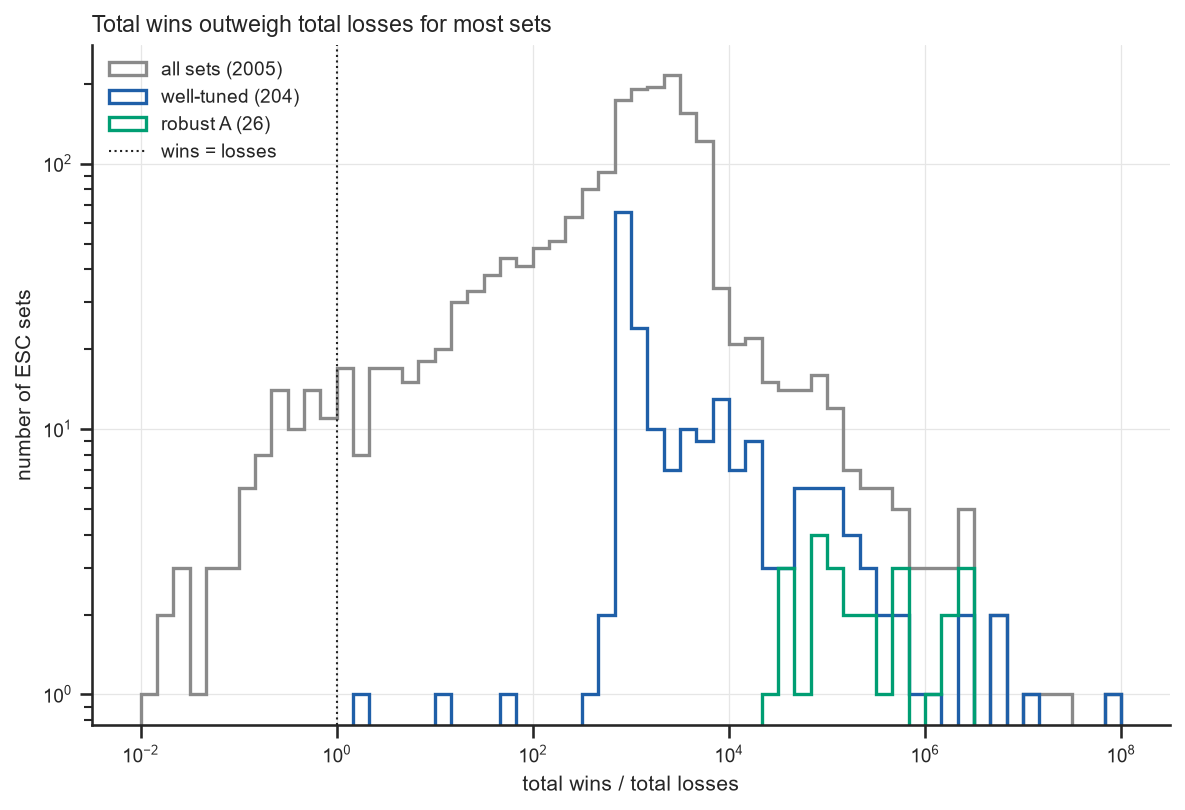

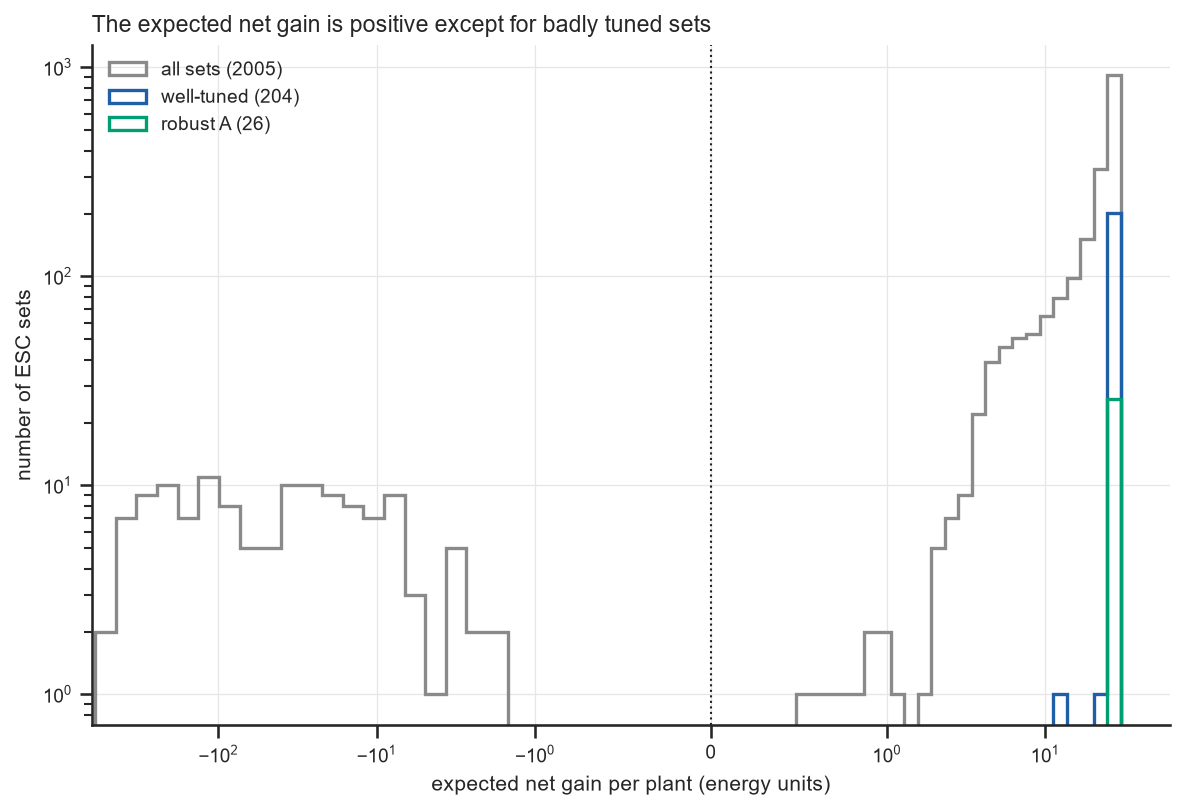

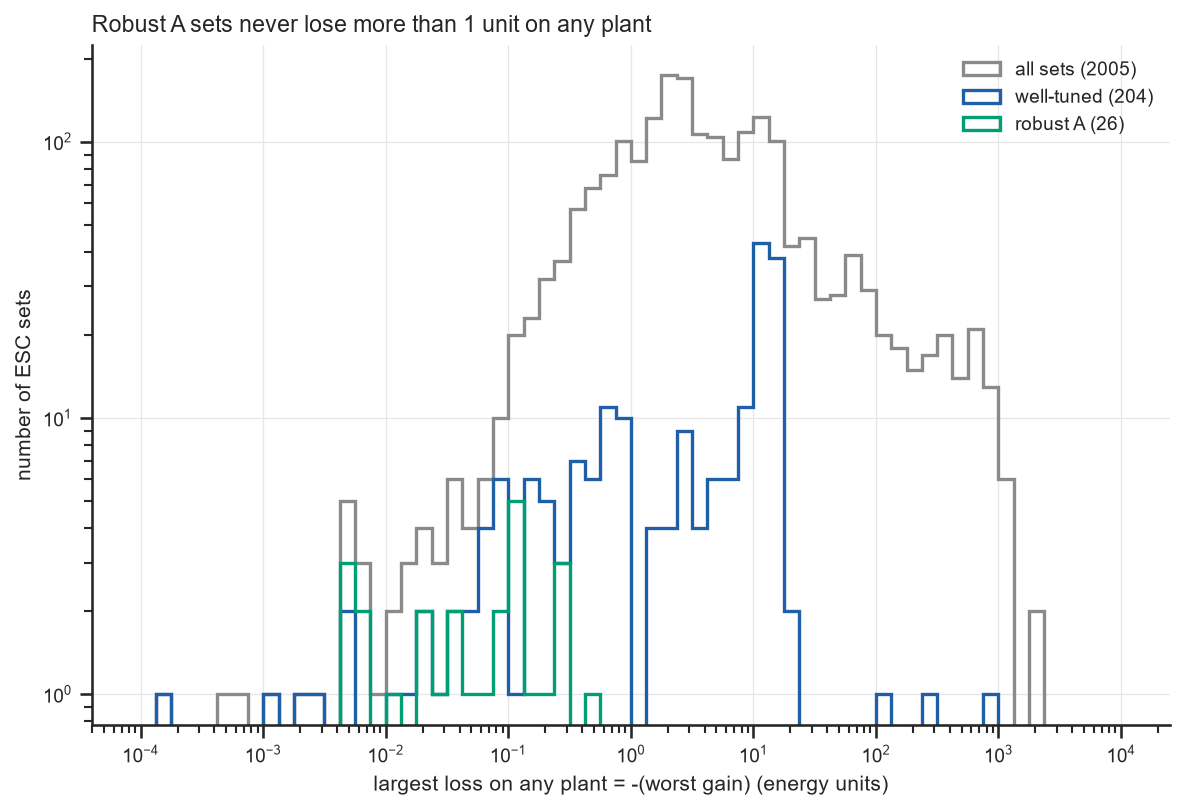

In [7]:
for panel in P1:
    fig, ax = plt.subplots(figsize=(8, 5.5)); fig.dpi = 150
    panel(ax); fig.tight_layout(); plt.show()

**What this shows.** Read the printed numbers above.
* *More often:* a typical ESC set beats $r = 0.5$ on most of the 600 plants. Most of the plants it does not beat are ties
  (gain within $\pm 1$ unit, plants that sit at or very near 0.5). Clear losses are rare except for badly tuned sets.
* *Wins against losses:* for most sets the mean win is far larger than the mean loss, and the total of all wins is many
  times the total of all losses. Only a minority of badly tuned sets has a negative expected net gain. Their losses can be
  hundreds of units (the ESC drives the ratio far from the optimum), which is why "all sets" has a large mean loss.
* *Groups:* the well-tuned and robust A groups win on almost every plant that has something to win. The robust A sets
  never lose more than about 1 unit on any plant. The well-tuned group still contains a few sets with large losses on some
  plants (Section 2 shows which).
* *Families:* wins and losses depend on the family. Families with plants far from 0.5 (static, linear) give larger wins.
  The time-scale and sine families are the hardest. The 600 plants are a design, so the pooled "all plants" numbers are
  not a probability of winning on a real machine.

## 2. Separate the plant effect from the ESC effect

**What and why.** gain = margin $-$ shortfall. If the margin depended only on the plant and the shortfall only on the ESC
set, the win condition would read simply **margin(plant) > shortfall(set)**: each plant has a fixed "prize", each set a
fixed "price". Because every set ran on every plant (a balanced crossed design with one run per cell), we can split the
variation of any quantity $Y_{sp}$ (set $s$, plant $p$) exactly into
$$Y_{sp} = \mu + \underbrace{(\bar Y_{s\cdot} - \mu)}_{\text{set main effect}} + \underbrace{(\bar Y_{\cdot p} - \mu)}_{\text{plant main effect}}
 + \underbrace{(Y_{sp} - \bar Y_{s\cdot} - \bar Y_{\cdot p} + \mu)}_{\text{interaction}},$$
and the sums of squares add up: SS$_\mathrm{total}$ = SS$_\mathrm{set}$ + SS$_\mathrm{plant}$ + SS$_\mathrm{interaction}$.
We give each part as a share of the total and as an RMS size in energy units ($\sqrt{\mathrm{SS}/N}$), for all sets, the
well-tuned sets and the robust A sets, over all plants and over the 'near' plants with margin $< 10$ units (where the
sign of the gain is decided).

In [8]:
def two_way(Y):
    """Shares of the total sum of squares of Y (sets x plants) and the RMS size of each part (energy units)."""
    mu = Y.mean()
    s_eff, p_eff = Y.mean(1) - mu, Y.mean(0) - mu
    resid = Y - mu - s_eff[:, None] - p_eff[None, :]
    ss = np.array([Y.shape[1] * (s_eff ** 2).sum(), Y.shape[0] * (p_eff ** 2).sum(), (resid ** 2).sum()])
    return ss / ss.sum(), np.sqrt(ss / Y.size), resid


near = margin < 10
rows = []
for gname, gm in GROUPS.items():
    for pname, pm in [('all 600 plants', np.ones(n_plants, bool)), (f'{near.sum()} near plants (margin < 10)', near)]:
        for qname, Y in [('margin', np.broadcast_to(margin, gain.shape)), ('gain', gain), ('shortfall', shortfall)]:
            share, rms, _ = two_way(Y[gm][:, pm])
            rows.append({'sets': gname, 'plants': pname, 'quantity': qname,
                         'share set': share[0], 'share plant': share[1], 'share interaction': share[2],
                         'RMS set': rms[0], 'RMS plant': rms[1], 'RMS interaction': rms[2]})
anova = pd.DataFrame(rows).set_index(['sets', 'plants', 'quantity'])
anova.round(3)

share set  share plant  \
sets       plants                        quantity                            
all sets   all 600 plants                margin         0.000        1.000   
                                         gain           0.670        0.223   
                                         shortfall      0.849        0.016   
           215 near plants (margin < 10) margin         0.000        1.000   
                                         gain           0.813        0.012   
                                         shortfall      0.814        0.011   
well-tuned all 600 plants                margin         0.000        1.000   
                                         gain           0.001        0.940   
                                         shortfall      0.018        0.032   
           215 near plants (margin < 10) margin         0.000        1.000   
                                         gain           0.026        0.091   
                                         shortfall      0.028        0.008   
robust A   all 600 plants                margin         0.000        1.000   
                                         gain           0.000        1.000   
                                         shortfall      0.064        0.520   
           215 near plants (margin < 10) margin         0.000        1.000   
                                         gain           0.000        1.000   
                                         shortfall      0.175        0.642   

                                                    share interaction  \
sets       plants                        quantity                       
all sets   all 600 plants                margin                 0.000   
                                         gain                   0.107   
                                         shortfall              0.135   
           215 near plants (margin < 10) margin                 0.000   
                                         gain                   0.175   
                                         shortfall              0.176   
well-tuned all 600 plants                margin                 0.000   
                                         gain                   0.059   
                                         shortfall              0.950   
           215 near plants (margin < 10) margin                 0.000   
                                         gain                   0.883   
                                         shortfall              0.964   
robust A   all 600 plants                margin                 0.000   
                                         gain                   0.000   
                                         shortfall              0.416   
           215 near plants (margin < 10) margin                 0.000   
                                         gain                   0.000   
                                         shortfall              0.183   

                                                    RMS set  RMS plant  \
sets       plants                        quantity                        
all sets   all 600 plants                margin       0.000     28.848   
                                         gain        42.704     24.635   
                                         shortfall   42.704      5.803   
           215 near plants (margin < 10) margin       0.000      2.909   
                                         gain        41.789      5.006   
                                         shortfall   41.789      4.757   
well-tuned all 600 plants                margin       0.000     28.848   
                                         gain         0.984     28.819   
                                         shortfall    0.984      1.330   
           215 near plants (margin < 10) margin       0.000      2.909   
                                         gain         1.555      2.897   
                                         shortfall    1.555      0.8

In [9]:
# where does the interaction of the well-tuned sets come from?
_, _, resid_wt = two_way(shortfall[well_tuned_set])
r2 = np.sort((resid_wt ** 2).ravel())[::-1]
top = int(0.001 * r2.size)
print(f'well-tuned sets: the largest 0.1 % of the runs ({top} of {r2.size:,}) carry {r2[:top].sum() / r2.sum():.1%} '
      f'of the interaction sum of squares of the shortfall')
big = gain[well_tuned_set] < -10
print(f'well-tuned runs that lose more than 10 units: {big.sum()} of {big.size:,}, in '
      f'{big.any(1).sum()} sets; by family: {pd.Series(family[np.where(big)[1]]).value_counts().to_dict()}')
s_w, p_w = np.unravel_index(np.argmin(np.where(well_tuned_set[:, None], gain, np.inf)), gain.shape)
print(f'largest loss of a well-tuned set: set {s_w} (k = {k[s_w]:.3g}, a = {a[s_w]:.3g}, f = {f[s_w]:.3g} Hz) on plant {p_w} '
      f'({family[p_w]}, tau_scale {tau_scale[p_w]:g}): gain {gain[s_w, p_w]:.1f}; there lambda_avg = {lam[s_w, p_w]:.2f} 1/s, '
      f'while the filter cut-off is w/pi = 2f = {2 * f[s_w]:.2f} rad/s')

well-tuned sets: the largest 0.1 % of the runs (122 of 122,400) carry 97.2% of the interaction sum of squares of the shortfall
well-tuned runs that lose more than 10 units: 114 of 122,400, in 86 sets; by family: {'sine': 83, 'timescale': 18, 'exp': 5, 'step': 4, 'random': 4}
largest loss of a well-tuned set: set 229 (k = 0.0893, a = 0.0466, f = 0.819 Hz) on plant 122 (timescale, tau_scale 0.5): gain -806.4; there lambda_avg = 2.58 1/s, while the filter cut-off is w/pi = 2f = 1.64 rad/s


**Does the separable rule predict the outcome?** Two versions of "win if margin(plant) > price(set)":
1. price = the set's median shortfall over the 600 plants (measured, one number per set);
2. price = the predicted dither loss $L_\mathrm{dith}$ (no simulation needed; uses the plant's $\bar\alpha$).

We count how often the rule gives the right outcome (win = gain $> 0$), for all runs and for the runs outside the tie band.

In [10]:
win = gain > 0
outside_tie = np.abs(gain) > TIE
rules = {'margin > median shortfall of the set': margin[None, :] > np.median(shortfall, 1)[:, None],
         'margin > L_dith': margin[None, :] > L_dith}
rule_rows = []
for rname, pred in rules.items():
    for gname, gm in GROUPS.items():
        ok = pred[gm] == win[gm]
        rule_rows.append({'rule': rname, 'sets': gname, 'correct (all runs)': ok.mean(),
                          'correct (outside tie band)': ok[outside_tie[gm]].mean()})
rule_table = pd.DataFrame(rule_rows).set_index(['rule', 'sets'])
print(rule_table.round(4).to_string())

# the price measured directly: shortfall on the static plant with r_ideal = 0.5 (margin 0, gain = -shortfall)
p_half = int(np.flatnonzero((family == 'static') & np.isclose(plants['r_ideal_0'].values, 0.5))[0])
ratio_half = shortfall[:, p_half] / L_nom
for gname, gm in GROUPS.items():
    qq = np.percentile(ratio_half[gm], [25, 50, 75])
    print(f'{gname:10s}: shortfall on the r = 0.5 plant / predicted L_dith: median {qq[1]:.3f} (IQR {qq[0]:.3f} to {qq[2]:.3f})')
qq = np.percentile((np.median(shortfall, 1) / L_nom)[well_tuned_set], [25, 50, 75])
print(f'well-tuned: median shortfall over all plants / L_dith: median {qq[1]:.2f} (IQR {qq[0]:.2f} to {qq[2]:.2f})')

                                                 correct (all runs)  correct (outside tie band)
rule                                 sets                                                      
margin > median shortfall of the set all sets                0.9038                      0.9508
                                     well-tuned              0.9911                      0.9976
                                     robust A                0.9951                      1.0000
margin > L_dith                      all sets                0.9246                      0.9427
                                     well-tuned              0.9960                      0.9976
                                     robust A                0.9998                      1.0000
all sets  : shortfall on the r = 0.5 plant / predicted L_dith: median 1.030 (IQR 1.020 to 1.043)
well-tuned: shortfall on the r = 0.5 plant / predicted L_dith: median 1.034 (IQR 1.027 to 1.042)
robust A  : shortfall on the r = 0.5 p

**Figure 2: margin is a plant property, the price is a set property.**
(a) The margin of each plant against its distance from 0.5. (b) Shares of the sums of squares. (c) The shortfall of
each set on the static plant $r_\mathrm{ideal} = 0.5$ (where the margin is 0) against the predicted $L_\mathrm{dith}$.
(d) Runs of the well-tuned sets (random subset of 40,000): plant margin against the set's $L_\mathrm{dith}$ on that plant,
coloured by the measured outcome.

least-squares fit margin = c x offset^2 over all 600 plants: c = 12,721 (median ratio margin / (13,225 offset^2) over plants with offset > 0.005: 0.963)


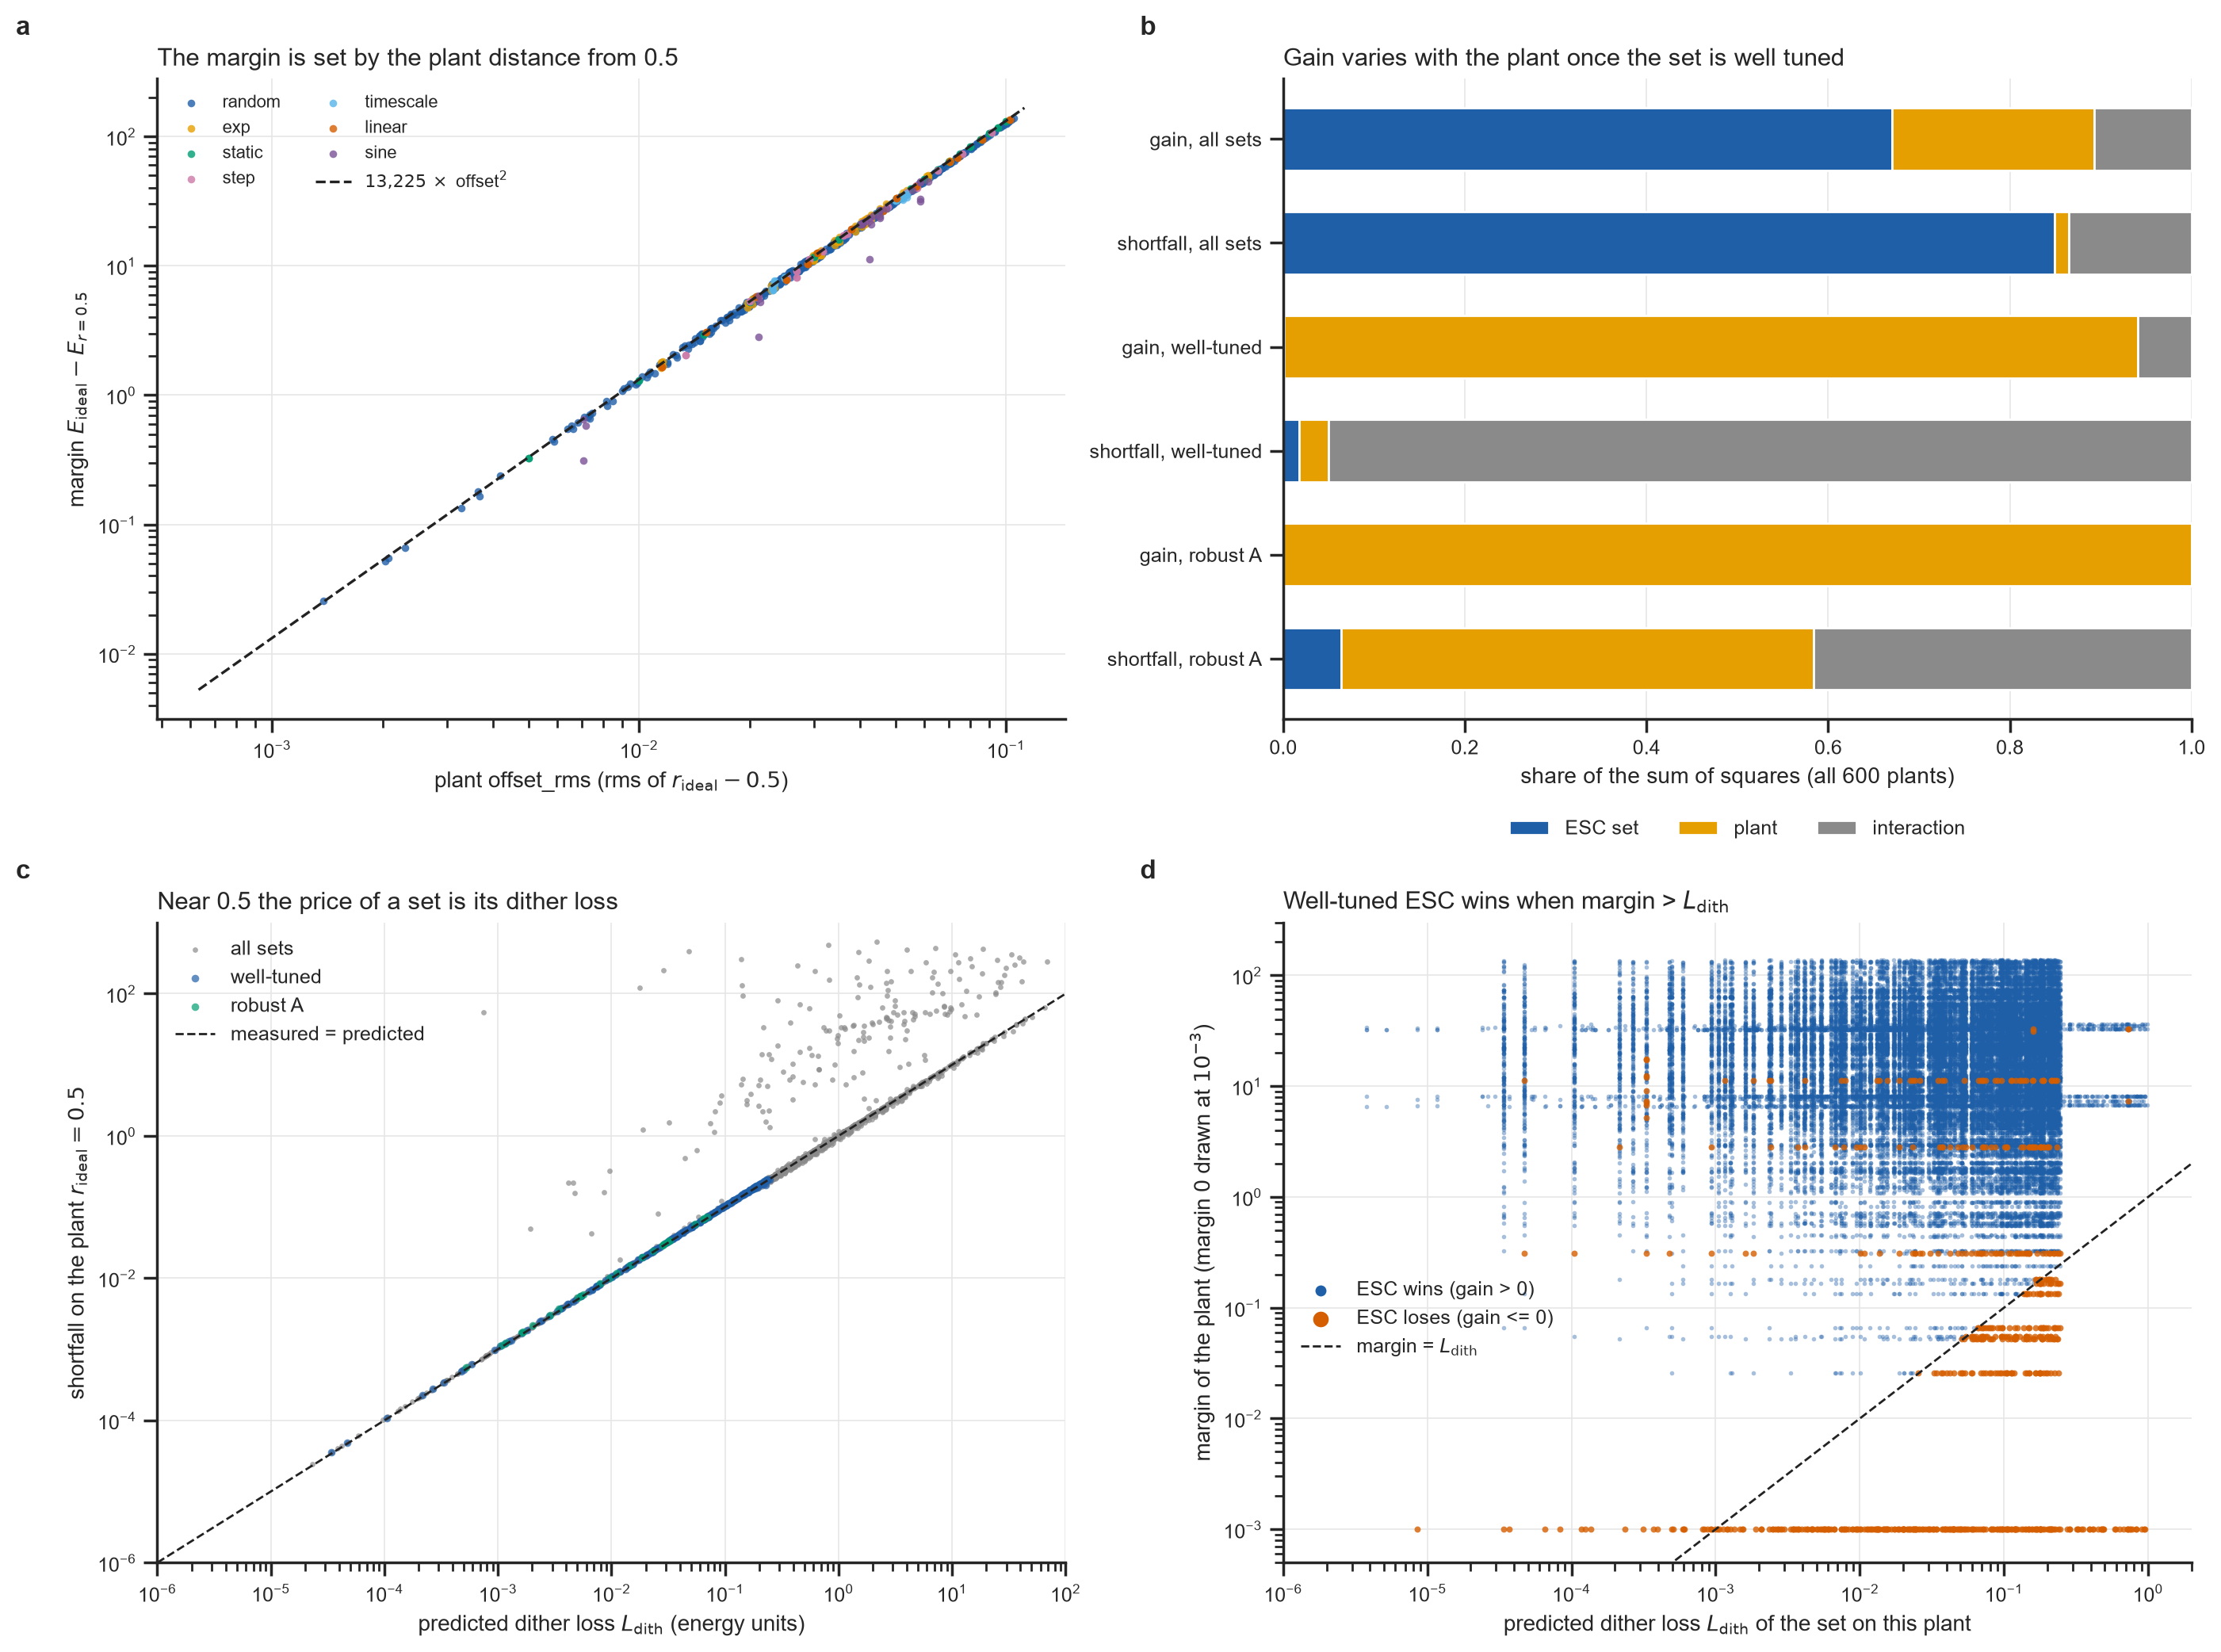

In [11]:
FAM_COL = dict(zip(plants['family'].value_counts().index, esc.CYCLE))


def p2_margin(ax):
    xx = np.logspace(-3.2, -0.95, 100)
    for fam_name, col in FAM_COL.items():
        sel = (family == fam_name) & (offset > 0)
        ax.scatter(offset[sel], margin[sel], s=12, color=col, alpha=0.8, linewidths=0, label=fam_name)
    ax.plot(xx, 13225 * xx ** 2, color=esc.COLORS['ideal'], ls='--', lw=1.2, label=r'$13{,}225\,\times$ offset$^2$')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel('plant offset_rms (rms of $r_\\mathrm{ideal} - 0.5$)'); ax.set_ylabel('margin $E_\\mathrm{ideal} - E_{r=0.5}$')
    ax.set_title('The margin is set by the plant distance from 0.5')
    ax.legend(loc='upper left', fontsize=8, ncol=2)


def p2_shares(ax):
    labels, shares = [], []
    for gname in GROUPS:
        for qname in ['gain', 'shortfall']:
            labels.append(f'{qname}, {gname}')
            shares.append(anova.loc[(gname, 'all 600 plants', qname), ['share set', 'share plant', 'share interaction']].values)
    shares = np.array(shares, dtype=float)
    y = np.arange(len(labels))[::-1]
    left = np.zeros(len(labels))
    for j, (name, col) in enumerate(zip(['ESC set', 'plant', 'interaction'],
                                        [esc.COLORS['esc'], esc.COLORS['fixed'], esc.COLORS['grey']])):
        ax.barh(y, shares[:, j], left=left, color=col, height=0.6, label=name)
        left += shares[:, j]
    ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlim(0, 1)
    ax.set_xlabel('share of the sum of squares (all 600 plants)'); ax.grid(axis='y', visible=False)
    ax.set_title('Gain varies with the plant once the set is well tuned')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)


def p2_price(ax):
    for gname, gm in GROUPS.items():
        ax.scatter(L_nom[gm], shortfall[gm, p_half], s=6 if gname == 'all sets' else 12, color=G_COL[gname],
                   alpha=0.7, linewidths=0, label=gname, rasterized=True)
    lim = [1e-6, 1e2]
    ax.plot(lim, lim, color=esc.COLORS['ideal'], ls='--', lw=1, label='measured = predicted')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(*lim); ax.set_ylim(1e-6, 1e3)
    ax.set_xlabel('predicted dither loss $L_\\mathrm{dith}$ (energy units)')
    ax.set_ylabel('shortfall on the plant $r_\\mathrm{ideal} = 0.5$')
    ax.set_title('Near 0.5 the price of a set is its dither loss')
    ax.legend(loc='upper left')


def p2_rule(ax):
    rs = np.random.default_rng(0)
    s_idx, p_idx = np.nonzero(np.broadcast_to(well_tuned_set[:, None], gain.shape))
    pick = rs.choice(s_idx.size, 40000, replace=False)
    s_idx, p_idx = s_idx[pick], p_idx[pick]
    xv, yv, wv = L_dith[s_idx, p_idx], margin[p_idx], win[s_idx, p_idx]
    ax.scatter(xv[wv], np.maximum(yv[wv], 1e-3), s=4, color=esc.COLORS['esc'], alpha=0.4, linewidths=0,
               label='ESC wins (gain > 0)', rasterized=True)
    ax.scatter(xv[~wv], np.maximum(yv[~wv], 1e-3), s=8, color=esc.COLORS['bad'], alpha=0.8, linewidths=0,
               label='ESC loses (gain <= 0)', rasterized=True)
    lim = [1e-6, 1e3]
    ax.plot(lim, lim, color=esc.COLORS['ideal'], ls='--', lw=1, label='margin = $L_\\mathrm{dith}$')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(1e-6, 2); ax.set_ylim(5e-4, 300)
    ax.set_xlabel('predicted dither loss $L_\\mathrm{dith}$ of the set on this plant')
    ax.set_ylabel('margin of the plant (margin 0 drawn at $10^{-3}$)')
    ax.set_title('Well-tuned ESC wins when margin > $L_\\mathrm{dith}$')
    leg = ax.legend(loc='center left', bbox_to_anchor=(0.0, 0.38), markerscale=2.5)
    for h in leg.legend_handles:
        h.set_alpha(1)


P2 = [p2_margin, p2_shares, p2_price, p2_rule]
fig, axs = plt.subplots(2, 2, figsize=(14, 10.5))
fig.dpi = 200
for ax, panel, letter in zip(axs.flat, P2, 'abcd'):
    panel(ax); esc.panel_letter(ax, letter)
fig.tight_layout()
plt.show()
c_all = np.sum(margin * offset ** 2) / np.sum(offset ** 4)
print(f'least-squares fit margin = c x offset^2 over all 600 plants: c = {c_all:,.0f} '
      f'(median ratio margin / (13,225 offset^2) over plants with offset > 0.005: '
      f'{np.median(margin[offset > 0.005] / (13225 * offset[offset > 0.005] ** 2)):.3f})')

The same four panels, one per figure:

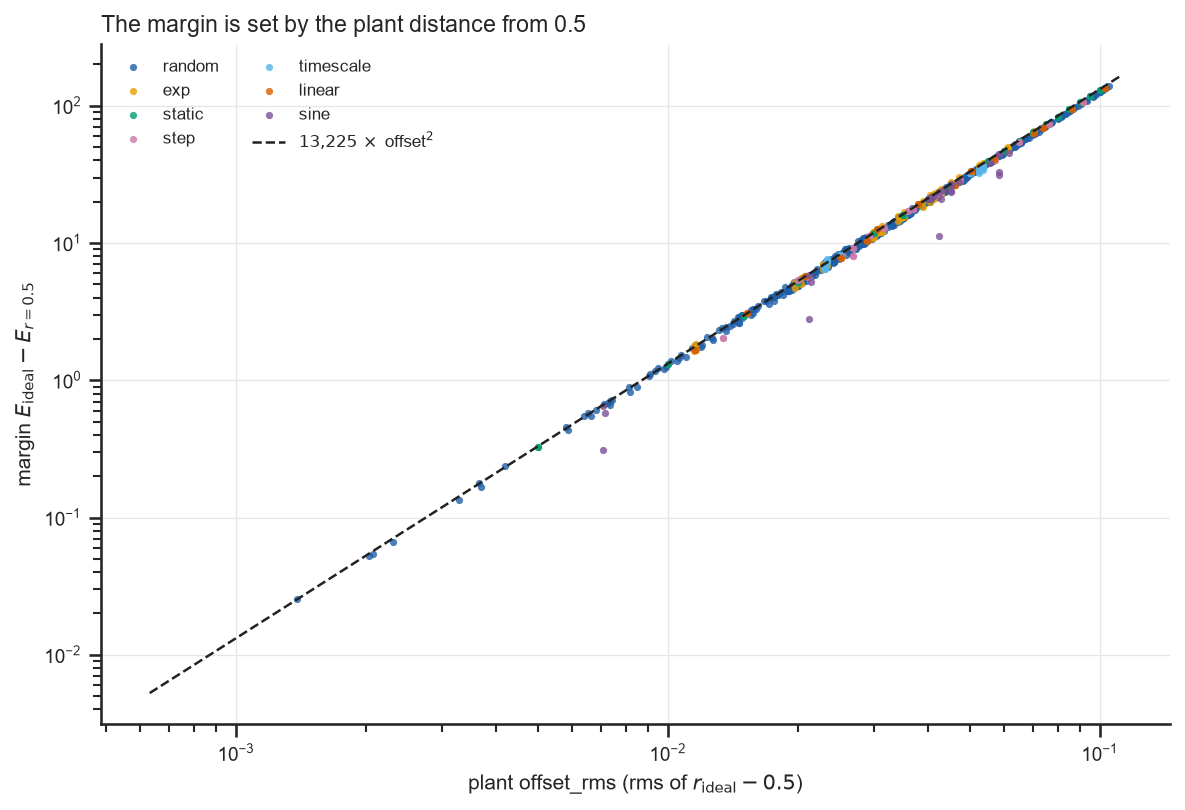

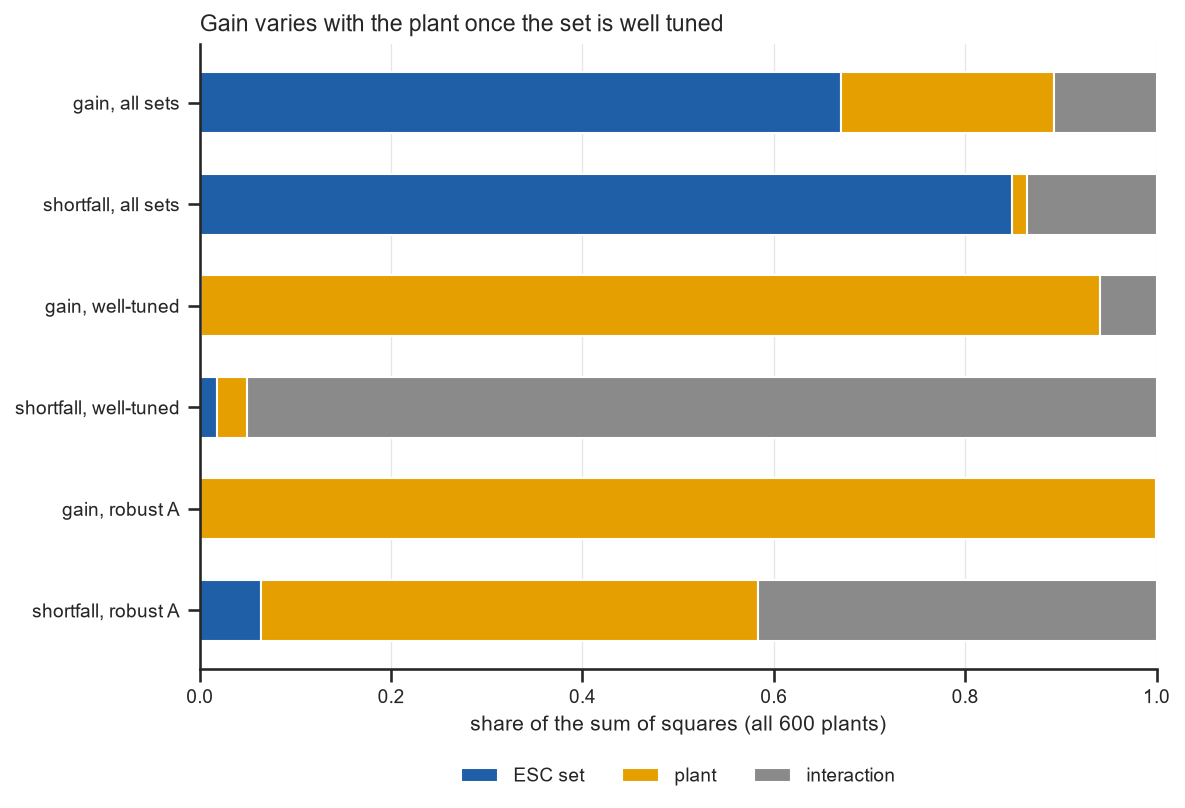

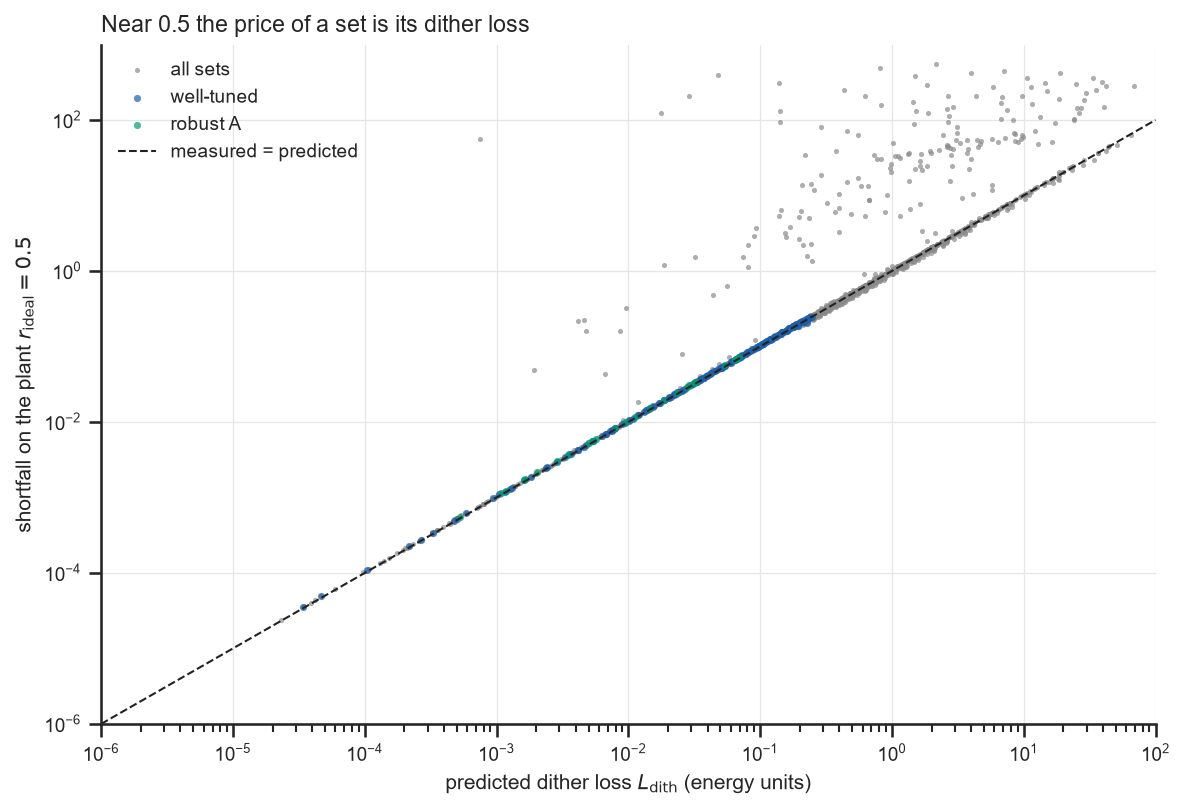

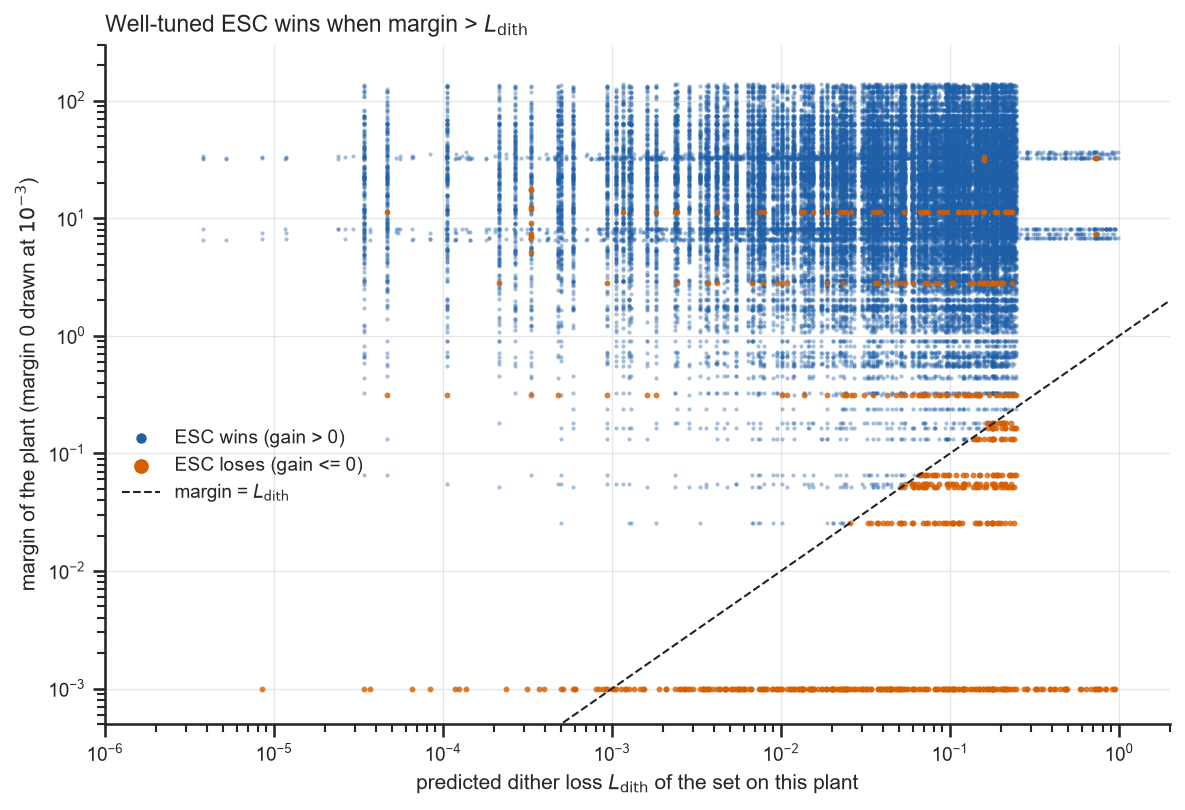

In [12]:
for panel in P2:
    fig, ax = plt.subplots(figsize=(8, 5.5)); fig.dpi = 150
    panel(ax); fig.tight_layout(); plt.show()

**What this shows.**
* The margin is a pure plant property (100 % plant share, by construction). It grows as offset_rms squared, close to the
  predicted $13{,}225 \times$ offset$^2$ (panel a and the printed fit).
* Over all 2,005 sets, the shortfall is mostly an ESC-set property: the set main effect carries most of its sum of
  squares. A badly tuned set pays a large price on every plant.
* Within the well-tuned and robust A sets, the *gain* is almost entirely a plant property: these sets all pay a small
  price, so what is left is the margin. Their shortfall is small in absolute terms (RMS columns). What variation it still
  has comes from the plant and from the set-plant interaction, not from the set alone: lag on drifting, stepping and
  oscillating plants depends on both. In the well-tuned group the interaction is dominated by a handful of runs
  (printed above). These are mainly fast sine plants that no set can follow, and fast time-scale plants where a set with
  a low dither frequency becomes unstable. There $\lambda_\mathrm{avg}$ exceeds the filter cut-off $\omega_c = 2f$ rad/s,
  where the averaged theory does not hold (Section 4).
* On the plant $r_\mathrm{ideal} = 0.5$ the measured shortfall agrees with the predicted dither loss $L_\mathrm{dith}$ to a
  few per cent (panel c; printed ratio). The simple rule "win if margin > $L_\mathrm{dith}$" predicts the outcome of nearly
  every well-tuned run (printed accuracies; panel d). So the win condition does read **margin(plant) > price(set)**, with
  the price $\approx L_\mathrm{dith}$ for a well-tuned set.

## 3. Win curve against the plant distance from 0.5

**What and why.** If the win condition is margin > price and margin $\approx 13{,}225 \times$ offset$^2$, ESC should lose (or tie)
on plants close to 0.5 and win on all plants beyond a break-even distance. We bin the plants by offset_rms and compute the
pooled win rate and the mean win and loss sizes per bin, for the three groups and the reference set. The bins near 0.5
hold only a few plants (printed), because the design has few plants there.

**Measured break-even distance per set.** For each set we fit gain $= c\,x^2 + b$ (with $x$ = offset_rms) to its 235 plants
with $x \le 0.03$ (least squares, all sets at once) and solve gain $= 0$: $x^* = \sqrt{-b/c}$. If ESC behaved exactly like
the simple rule, $c \approx 13{,}225$ and $-b \approx L_\mathrm{dith}$, so $x^* \approx \delta^* = \sqrt{L_\mathrm{dith}/13{,}225}$.

In [13]:
EDGES = np.array([0, 0.001, 0.0025, 0.004, 0.0055, 0.007, 0.0085, 0.01, 0.0125, 0.015, 0.02, 0.025, 0.03, 0.04,
                  0.05, 0.065, 0.11])
bin_of = np.digitize(offset, EDGES) - 1
n_bins = len(EDGES) - 1
bin_x = np.array([offset[bin_of == j].mean() for j in range(n_bins)])
bin_n = np.bincount(bin_of, minlength=n_bins)


def win_curve(gm):
    """Pooled win rate, mean win, mean loss and mean gain per offset bin for the sets in gm."""
    out = {key: np.full(n_bins, np.nan) for key in ['win rate', 'mean win', 'mean loss', 'mean gain']}
    for j in range(n_bins):
        g = gain[gm][:, bin_of == j]
        out['win rate'][j] = (g > 0).mean(); out['mean gain'][j] = g.mean()
        if (g > 0).any(): out['mean win'][j] = g[g > 0].mean()
        if (g < 0).any(): out['mean loss'][j] = -g[g < 0].mean()
    return pd.DataFrame(out, index=pd.Index(np.round(bin_x, 4), name='mean offset_rms of bin'))


CURVE_SETS = {**GROUPS, 'reference': np.arange(n_sets) == 0}
curves = {name: win_curve(gm) for name, gm in CURVE_SETS.items()}
print('plants per bin:', bin_n.tolist())
pd.concat({name: c['win rate'] for name, c in curves.items()}, axis=1).assign(plants=bin_n).round(3).T

plants per bin: [4, 4, 3, 3, 6, 11, 8, 19, 21, 41, 58, 57, 87, 91, 95, 92]


mean offset_rms of bin,0.0000,0.0020,0.0035,0.0047,0.0063,0.0075,0.0096,0.0114,0.0141,0.0180,0.0225,0.0272,0.0343,0.0439,0.0557,0.0801
all sets,0.0,0.204,0.358,0.514,0.586,0.541,0.704,0.723,0.801,0.822,0.819,0.888,0.911,0.915,0.950,0.969
well-tuned,0.0,0.430,0.778,0.998,1.000,0.932,1.000,1.000,1.000,1.000,0.988,0.999,1.000,0.993,0.999,1.000
robust A,0.0,0.808,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
reference,0.0,0.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000
plants,4.0,4.000,3.000,3.000,6.000,11.000,8.000,19.000,21.000,41.000,58.000,57.000,87.000,91.000,95.000,92.000


In [14]:
fit_plants = offset <= 0.03
X = np.c_[offset[fit_plants] ** 2, np.ones(fit_plants.sum())]
c_fit, b_fit = np.linalg.lstsq(X, gain[:, fit_plants].T, rcond=None)[0]       # one fit per set
crosses = (b_fit < 0) & (c_fit > 0)
x_star = np.where(crosses, np.sqrt(np.clip(-b_fit / np.where(c_fit > 0, c_fit, 1), 0, None)), np.nan)
delta_star = np.sqrt(L_nom / 13225)
print(f'fit on {fit_plants.sum()} plants with offset_rms <= 0.03; {crosses.sum()} of {n_sets} sets cross zero '
      f'(the others have b >= 0 or c <= 0: they never break even, or win everywhere)')
for gname, gm in GROUPS.items():
    r = (x_star / delta_star)[gm & crosses]
    qq = np.percentile(r, [25, 50, 75])
    print(f'{gname:10s}: measured / predicted break-even distance x*/delta*: median {qq[1]:.2f} (IQR {qq[0]:.2f} to {qq[2]:.2f}); '
          f'median c/13,225 = {np.median(c_fit[gm]) / 13225:.3f}; median -b/L_dith = {np.median(-b_fit[gm] / L_nom[gm]):.2f}')
chosen_be = pd.DataFrame({'set': CHOSEN, 'L_dith': L_nom[:5], 'predicted delta*': delta_star[:5], 'measured x*': x_star[:5],
                          'x*/delta*': x_star[:5] / delta_star[:5], 'c/13225': c_fit[:5] / 13225, '-b': -b_fit[:5]}).set_index('set')
chosen_be.round(5)

fit on 235 plants with offset_rms <= 0.03; 1963 of 2005 sets cross zero (the others have b >= 0 or c <= 0: they never break even, or win everywhere)
all sets  : measured / predicted break-even distance x*/delta*: median 1.67 (IQR 1.17 to 3.03); median c/13,225 = 0.841; median -b/L_dith = 1.62
well-tuned: measured / predicted break-even distance x*/delta*: median 1.20 (IQR 1.12 to 1.51); median c/13,225 = 0.952; median -b/L_dith = 1.36
robust A  : measured / predicted break-even distance x*/delta*: median 1.28 (IQR 1.10 to 1.66); median c/13,225 = 0.957; median -b/L_dith = 1.54


,L_dith,predicted delta*,measured x*,x*/delta*,c/13225,-b
set,,,,,,
reference,0.06556,0.00223,0.00243,1.09239,0.95546,0.07475
fastest,0.00223,0.00041,0.00189,4.59134,0.94083,0.04423
fastest a>=0.15,0.02633,0.00141,0.00236,1.67146,0.94069,0.06919
fastest f<=3,0.02066,0.00125,0.00241,1.92976,0.93110,0.07165
best energy a>=0.1,0.00727,0.00074,0.00092,1.24215,0.95856,0.01075


**Figure 3: ESC loses only on plants within a small distance of 0.5.** (a) Pooled win rate per offset bin. (b) Mean
win size (solid) and mean loss size (dashed) per bin. (c) The reference set: gain on every plant, the quadratic fit and
the measured and predicted break-even distances. (d) Measured against predicted break-even distance for every set
whose fit crosses zero. The $x$ axes in (a)-(c) are linear below 0.001 and logarithmic above, so the plants at exactly
0.5 can be shown.

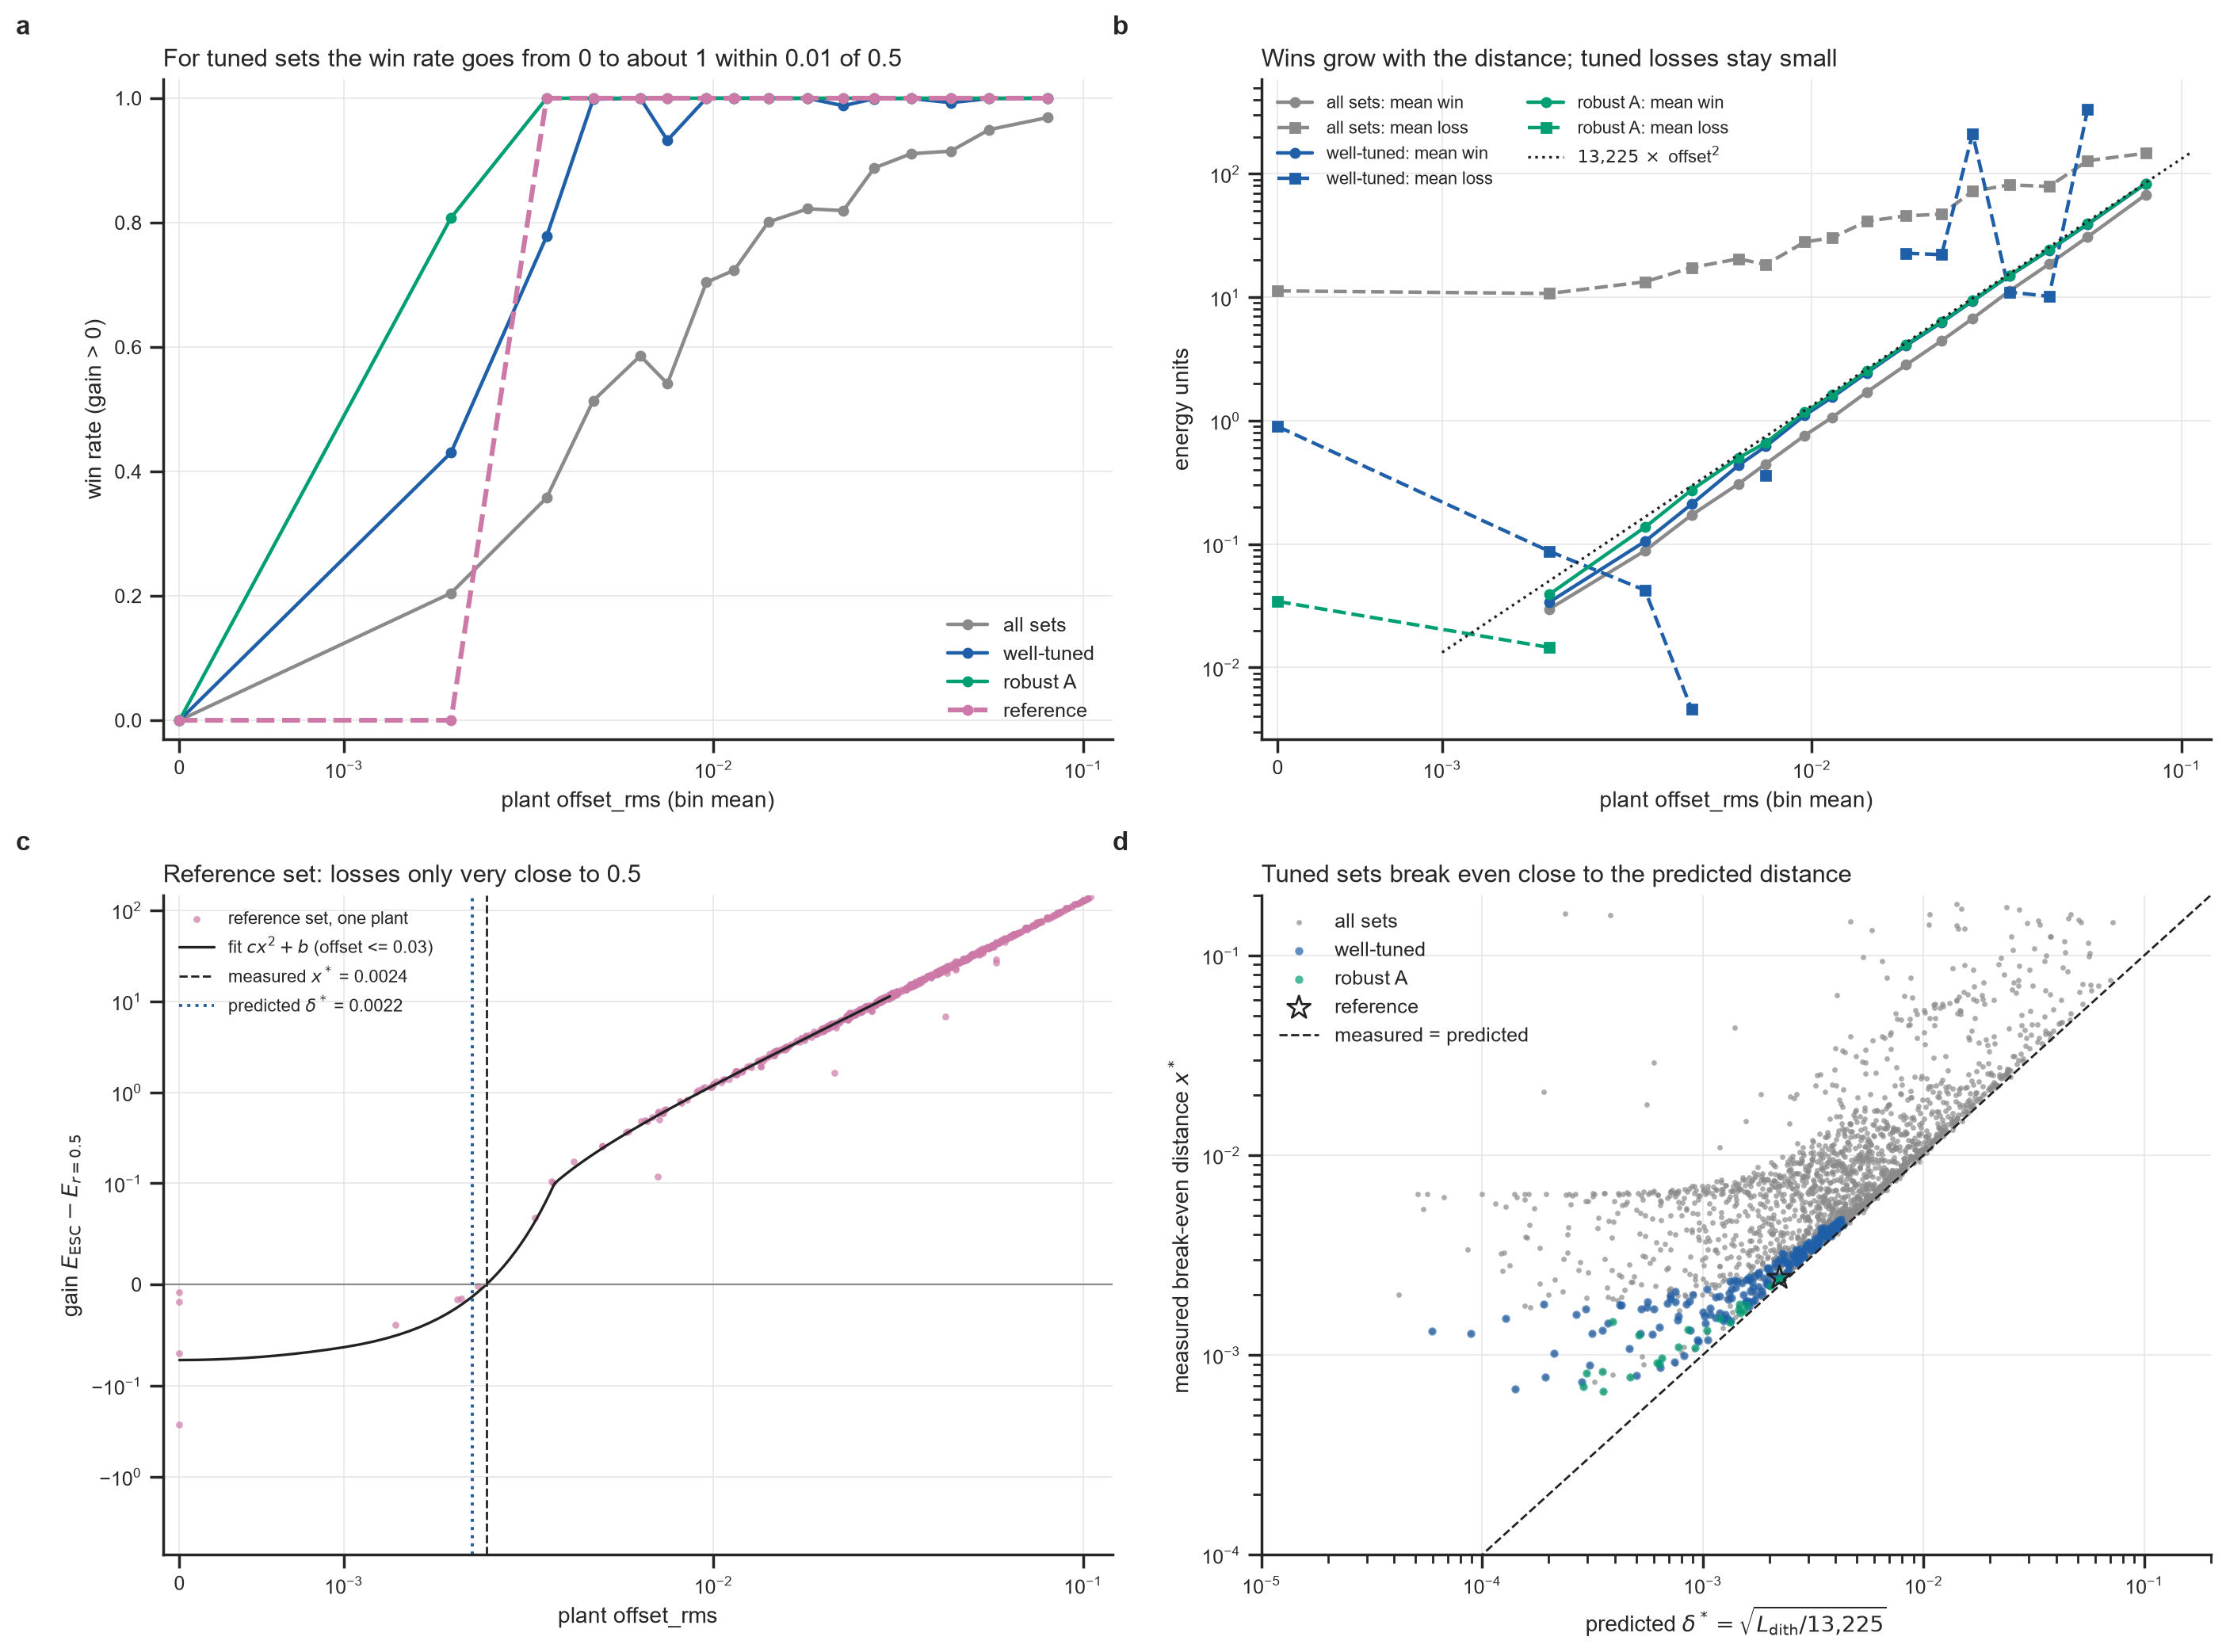

In [15]:
CURVE_COL = {**G_COL}


def p3_win(ax):
    for name, c in curves.items():
        ax.plot(bin_x, c['win rate'], marker='o', color=CURVE_COL[name], ms=4, label=name,
                lw=2.2 if name == 'reference' else 1.6, ls='--' if name == 'reference' else '-')
    ax.set_xscale('symlog', linthresh=1e-3, linscale=0.4); ax.set_xlim(-1e-4, 0.12); ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel('plant offset_rms (bin mean)'); ax.set_ylabel('win rate (gain > 0)')
    ax.set_title('For tuned sets the win rate goes from 0 to about 1 within 0.01 of 0.5')
    ax.legend(loc='lower right')


def p3_sizes(ax):
    for name, c in curves.items():
        if name == 'reference':
            continue
        ax.plot(bin_x, c['mean win'], 'o-', color=CURVE_COL[name], ms=4, label=f'{name}: mean win')
        ax.plot(bin_x, c['mean loss'], 's--', color=CURVE_COL[name], ms=4, label=f'{name}: mean loss')
    xx = np.logspace(-3, -0.97, 50)
    ax.plot(xx, 13225 * xx ** 2, color=esc.COLORS['ideal'], ls=':', lw=1.2, label=r'$13{,}225\,\times$ offset$^2$')
    ax.set_xscale('symlog', linthresh=1e-3, linscale=0.4); ax.set_xlim(-1e-4, 0.12); ax.set_yscale('log')
    ax.set_xlabel('plant offset_rms (bin mean)'); ax.set_ylabel('energy units')
    ax.set_title('Wins grow with the distance; tuned losses stay small')
    ax.legend(loc='upper left', fontsize=8, ncol=2)


def p3_reference(ax):
    s = 0
    ax.scatter(offset, gain[s], s=10, color=G_COL['reference'], alpha=0.7, linewidths=0, label='reference set, one plant')
    xx = np.linspace(0, 0.03, 300)
    ax.plot(xx, c_fit[s] * xx ** 2 + b_fit[s], color=esc.COLORS['ideal'], lw=1.2, label='fit $c x^2 + b$ (offset <= 0.03)')
    ax.axhline(0, color=esc.COLORS['grey'], lw=0.8)
    ax.axvline(x_star[s], color=esc.COLORS['ideal'], ls='--', lw=1, label=f'measured $x^*$ = {x_star[s]:.4f}')
    ax.axvline(delta_star[s], color=esc.COLORS['esc'], ls=':', lw=1.4, label=f'predicted $\\delta^*$ = {delta_star[s]:.4f}')
    ax.set_xscale('symlog', linthresh=1e-3, linscale=0.4); ax.set_yscale('symlog', linthresh=0.1)
    ax.set_xlim(-1e-4, 0.12)
    ax.set_xlabel('plant offset_rms'); ax.set_ylabel('gain $E_\\mathrm{ESC} - E_{r=0.5}$')
    ax.set_title('Reference set: losses only very close to 0.5')
    ax.legend(loc='upper left', fontsize=8)


def p3_breakeven(ax):
    for gname, gm in GROUPS.items():
        sel = gm & crosses
        ax.scatter(delta_star[sel], x_star[sel], s=6 if gname == 'all sets' else 14, color=G_COL[gname], alpha=0.7,
                   linewidths=0, label=gname, rasterized=True)
    ax.scatter(delta_star[0], x_star[0], marker='*', s=120, facecolor='none', edgecolor=esc.COLORS['ideal'], label='reference')
    lim = [1e-5, 0.2]
    ax.plot(lim, lim, color=esc.COLORS['ideal'], ls='--', lw=1, label='measured = predicted')
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(*lim); ax.set_ylim(1e-4, 0.2)
    ax.set_xlabel(r'predicted $\delta^* = \sqrt{L_\mathrm{dith}/13{,}225}$')
    ax.set_ylabel('measured break-even distance $x^*$')
    ax.set_title('Tuned sets break even close to the predicted distance')
    ax.legend(loc='upper left')


P3 = [p3_win, p3_sizes, p3_reference, p3_breakeven]
fig, axs = plt.subplots(2, 2, figsize=(14, 10.5))
fig.dpi = 200
for ax, panel, letter in zip(axs.flat, P3, 'abcd'):
    panel(ax); esc.panel_letter(ax, letter)
fig.tight_layout()
plt.show()

The same four panels, one per figure:

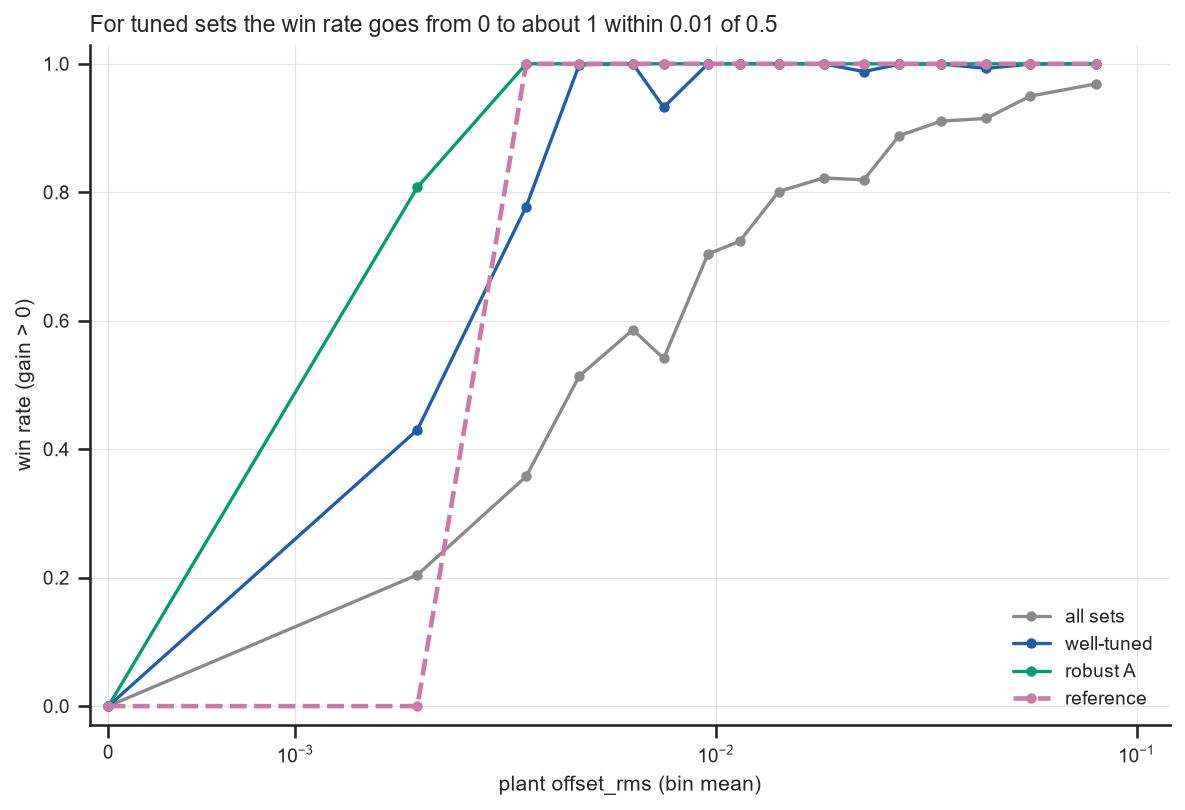

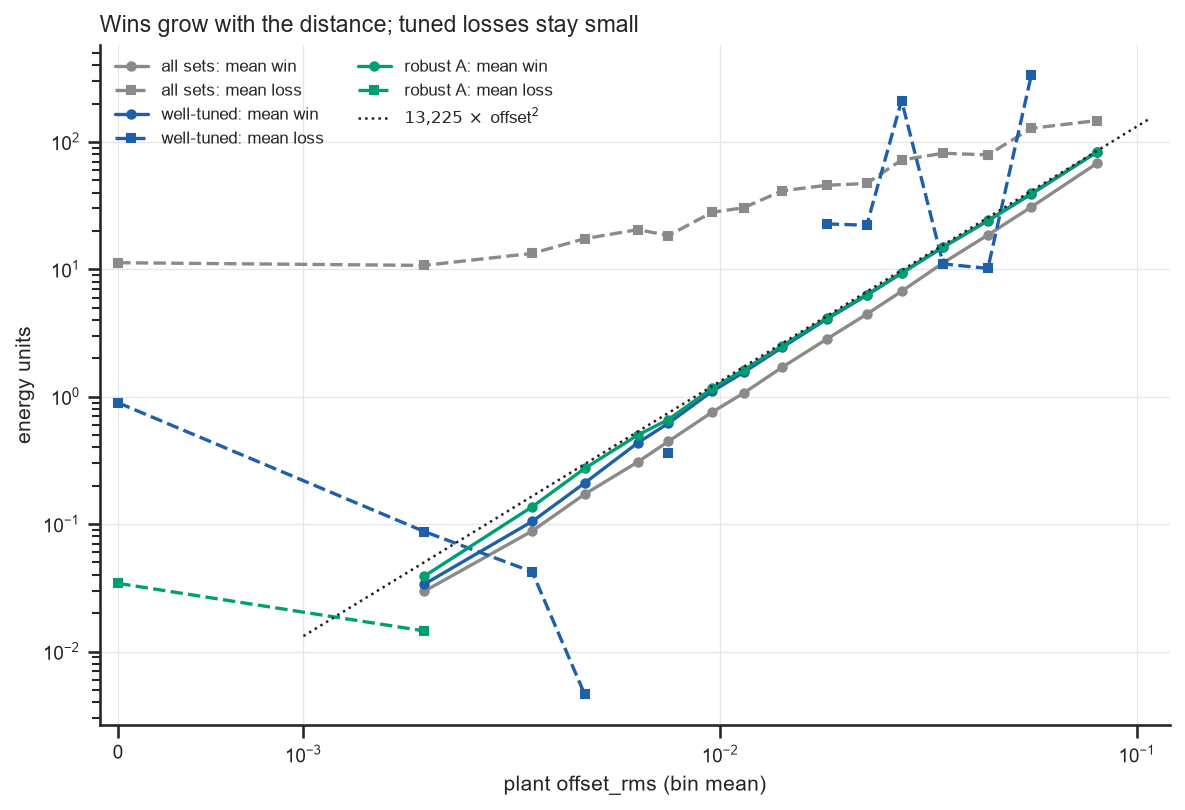

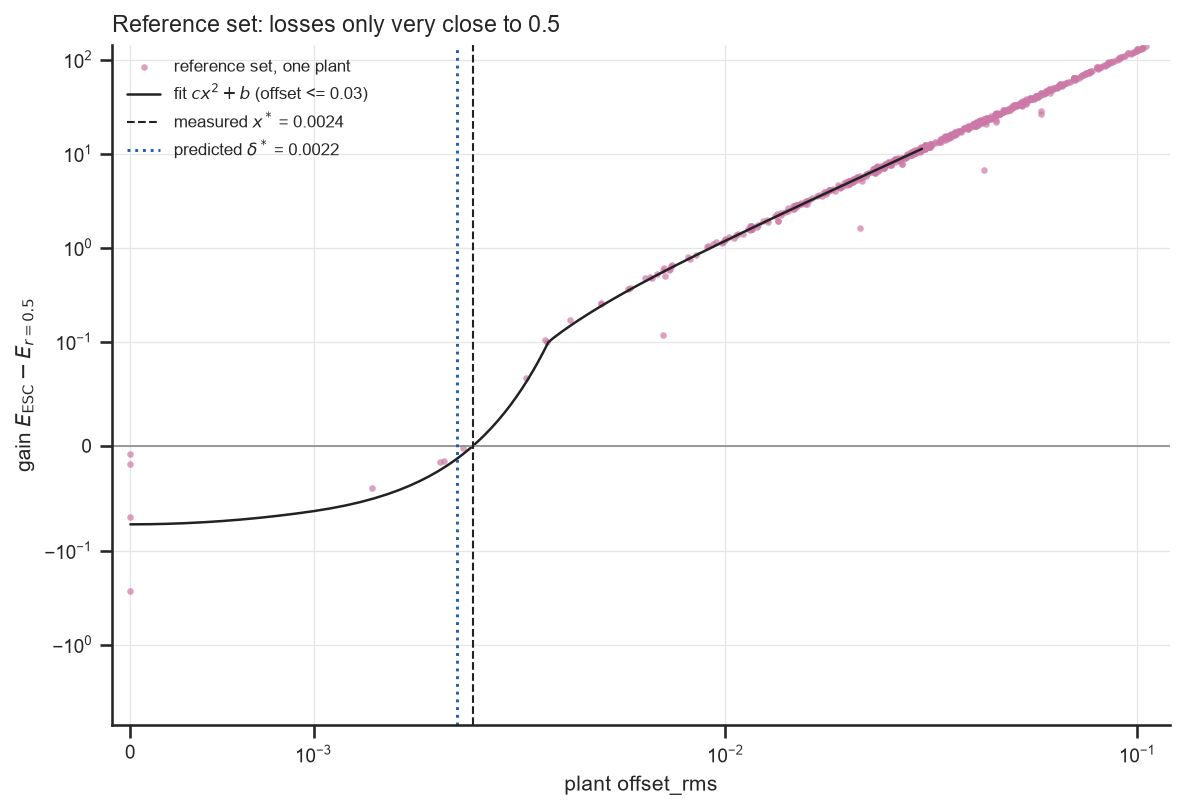

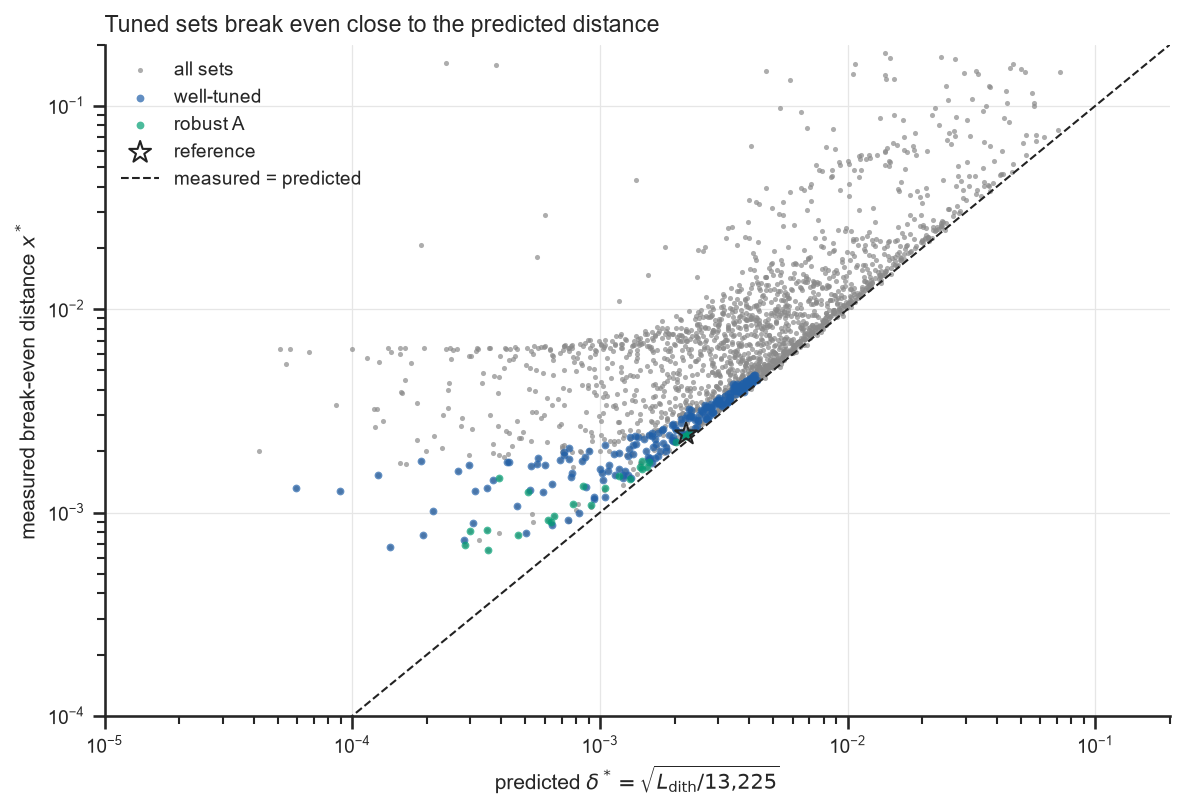

In [16]:
for panel in P3:
    fig, ax = plt.subplots(figsize=(8, 5.5)); fig.dpi = 150
    panel(ax); fig.tight_layout(); plt.show()

**Integrating over plant distributions.** The win curve can be averaged over any assumed distribution of plants. Four
examples:
* **(A) random family**: $r_{\mathrm{ideal},0}$ uniform in 0.45-0.55, drift $\lambda$ uniform in $\pm 0.002$ 1/s, as in all
  earlier sweeps. The 364 random plants are a sample of this distribution, so the expectation is their mean
  (bootstrap interval over these plants).
* **(B) static plants, $r_\mathrm{ideal}$ uniform in 0.45-0.55.** The static plants are on a grid of 0.005. Between grid points
  the shortfall of each set is interpolated linearly and the margin is $c_\mathrm{static}(r - 0.5)^2$ (fitted to the static
  plants, printed), on a fine grid of 4,001 values of $r$.
* **(C) static plants within $\pm 0.01$ of 0.5**, the same way (grid points 0.49, 0.495, 0.5, 0.505, 0.51).
* **(D) the nominal plant** ($\tau_D = 1.71$ s, $\tau_T = 1.66$ s, $r_\mathrm{ideal} \approx 0.507$): the measured gain on the
  closest static plant, and the gain interpolated to the nominal $r_\mathrm{ideal}$ in the same way as (B).

For (B)-(D) the "win rate" is the fraction of the distribution where gain $> 0$.

In [17]:

st_idx = np.flatnonzero(family == 'static')
r_st = plants['r_ideal_0'].values[st_idx]
off_st = r_st != 0.5
c_static = np.sum(margin[st_idx] * (r_st - 0.5) ** 2) / np.sum((r_st - 0.5) ** 4)
print(f'static plants: margin = c_static (r - 0.5)^2 with c_static = {c_static:,.1f}; largest relative residual '
      f'{np.max(np.abs(margin[st_idx][off_st] / (c_static * (r_st[off_st] - 0.5) ** 2) - 1)):.1e}')


def static_gain(grid):
    """Gain of every set at the ideal ratios `grid` (static plants): fitted margin minus interpolated shortfall."""
    weights = np.stack([np.interp(grid, r_st, np.eye(len(r_st))[j]) for j in range(len(r_st))], axis=1)
    return c_static * (grid - 0.5) ** 2 - shortfall[:, st_idx] @ weights.T            # (set, grid point)


def static_distribution(lo, hi, n_grid=4001):
    """Win rate and net gain of every set for r_ideal uniform in [lo, hi]."""
    g = static_gain(np.linspace(lo, hi, n_grid))
    return (g > 0).mean(1), g.mean(1)


r_nom = esc.ALPHA_T / (esc.ALPHA_T + esc.ALPHA_D)
p_nom = st_idx[np.argmin(np.abs(r_st - r_nom))]
g_nom = static_gain(np.array([r_nom]))[:, 0]
print(f'nominal r_ideal = {r_nom:.4f}; closest static plant: r_ideal = {plants["r_ideal_0"][p_nom]:.3f} '
      f'(margin {margin[p_nom]:.3f}); margin at the nominal r_ideal (fit): {c_static * (r_nom - 0.5) ** 2:.3f}')

rnd = family == 'random'
dist = {'B static 0.45-0.55': static_distribution(0.45, 0.55),
        'C static 0.49-0.51': static_distribution(0.49, 0.51),
        'D nominal, plant 0.505': ((gain[:, p_nom] > 0).astype(float), gain[:, p_nom]),
        'D nominal, interpolated': ((g_nom > 0).astype(float), g_nom)}
DIST_SETS = {**GROUPS, **{name: np.arange(n_sets) == i for i, name in enumerate(CHOSEN)}}
rows, dist_values = {}, {}
for sname, gm in DIST_SETS.items():
    t = group_summary({sname: gm}, rnd).iloc[0]
    row = {'sets': int(gm.sum()),
           'A random: win rate': f"{t['win rate']:.3f} [{t['win rate lo']:.3f}, {t['win rate hi']:.3f}]",
           'A random: net gain': f"{t['net gain']:.2f} [{t['net gain lo']:.2f}, {t['net gain hi']:.2f}]"}
    dist_values[sname] = {'A random family': (t['win rate'], t['net gain'])}
    for dname, (wr, ng) in dist.items():
        row[f'{dname}: win rate'] = round(float(wr[gm].mean()), 3)
        row[f'{dname}: net gain'] = round(float(ng[gm].mean()), 3)
        dist_values[sname][dname] = (wr[gm].mean(), ng[gm].mean())
    rows[sname] = row
dist_table = pd.DataFrame(rows).T
dist_table


static plants: margin = c_static (r - 0.5)^2 with c_static = 13,048.0; largest relative residual 2.8e-04
nominal r_ideal = 0.5074; closest static plant: r_ideal = 0.505 (margin 0.326); margin at the nominal r_ideal (fit): 0.718


,sets,A random: win rate,A random: net gain,B static 0.45-0.55: win rate,B static 0.45-0.55: net gain,C static 0.49-0.51: win rate,C static 0.49-0.51: net gain,"D nominal, plant 0.505: win rate","D nominal, plant 0.505: net gain","D nominal, interpolated: win rate","D nominal, interpolated: net gain"
all sets,2005,"0.875 [0.861, 0.887]","12.86 [10.26, 15.36]",0.808,0.116,0.455,-8.294,0.547,-8.248,0.678,-7.924
well-tuned,204,"0.992 [0.985, 0.997]","26.03 [22.96, 28.98]",0.955,10.699,0.775,0.346,1.0,0.243,1.0,0.632
robust A,26,"0.998 [0.995, 1.000]","26.13 [23.06, 29.07]",0.978,10.795,0.89,0.411,1.0,0.305,1.0,0.695
reference,1,"0.989 [0.978, 0.997]","26.08 [23.00, 29.02]",0.954,10.746,0.771,0.365,1.0,0.261,1.0,0.652
fastest,1,"1.000 [1.000, 1.000]","26.08 [23.01, 29.03]",0.991,10.741,0.955,0.427,1.0,0.321,1.0,0.707
fastest a>=0.15,1,"0.997 [0.992, 1.000]","26.05 [22.98, 29.00]",0.97,10.717,0.852,0.402,1.0,0.297,1.0,0.684
fastest f<=3,1,"1.000 [1.000, 1.000]","25.99 [22.92, 28.93]",0.974,10.654,0.868,0.405,1.0,0.301,1.0,0.685
best energy a>=0.1,1,"1.000 [1.000, 1.000]","26.16 [23.09, 29.11]",0.985,10.826,0.922,0.425,1.0,0.319,1.0,0.709


**Figure 4: expected win rate and net gain under the four plant distributions**, for the three groups and the reference set.

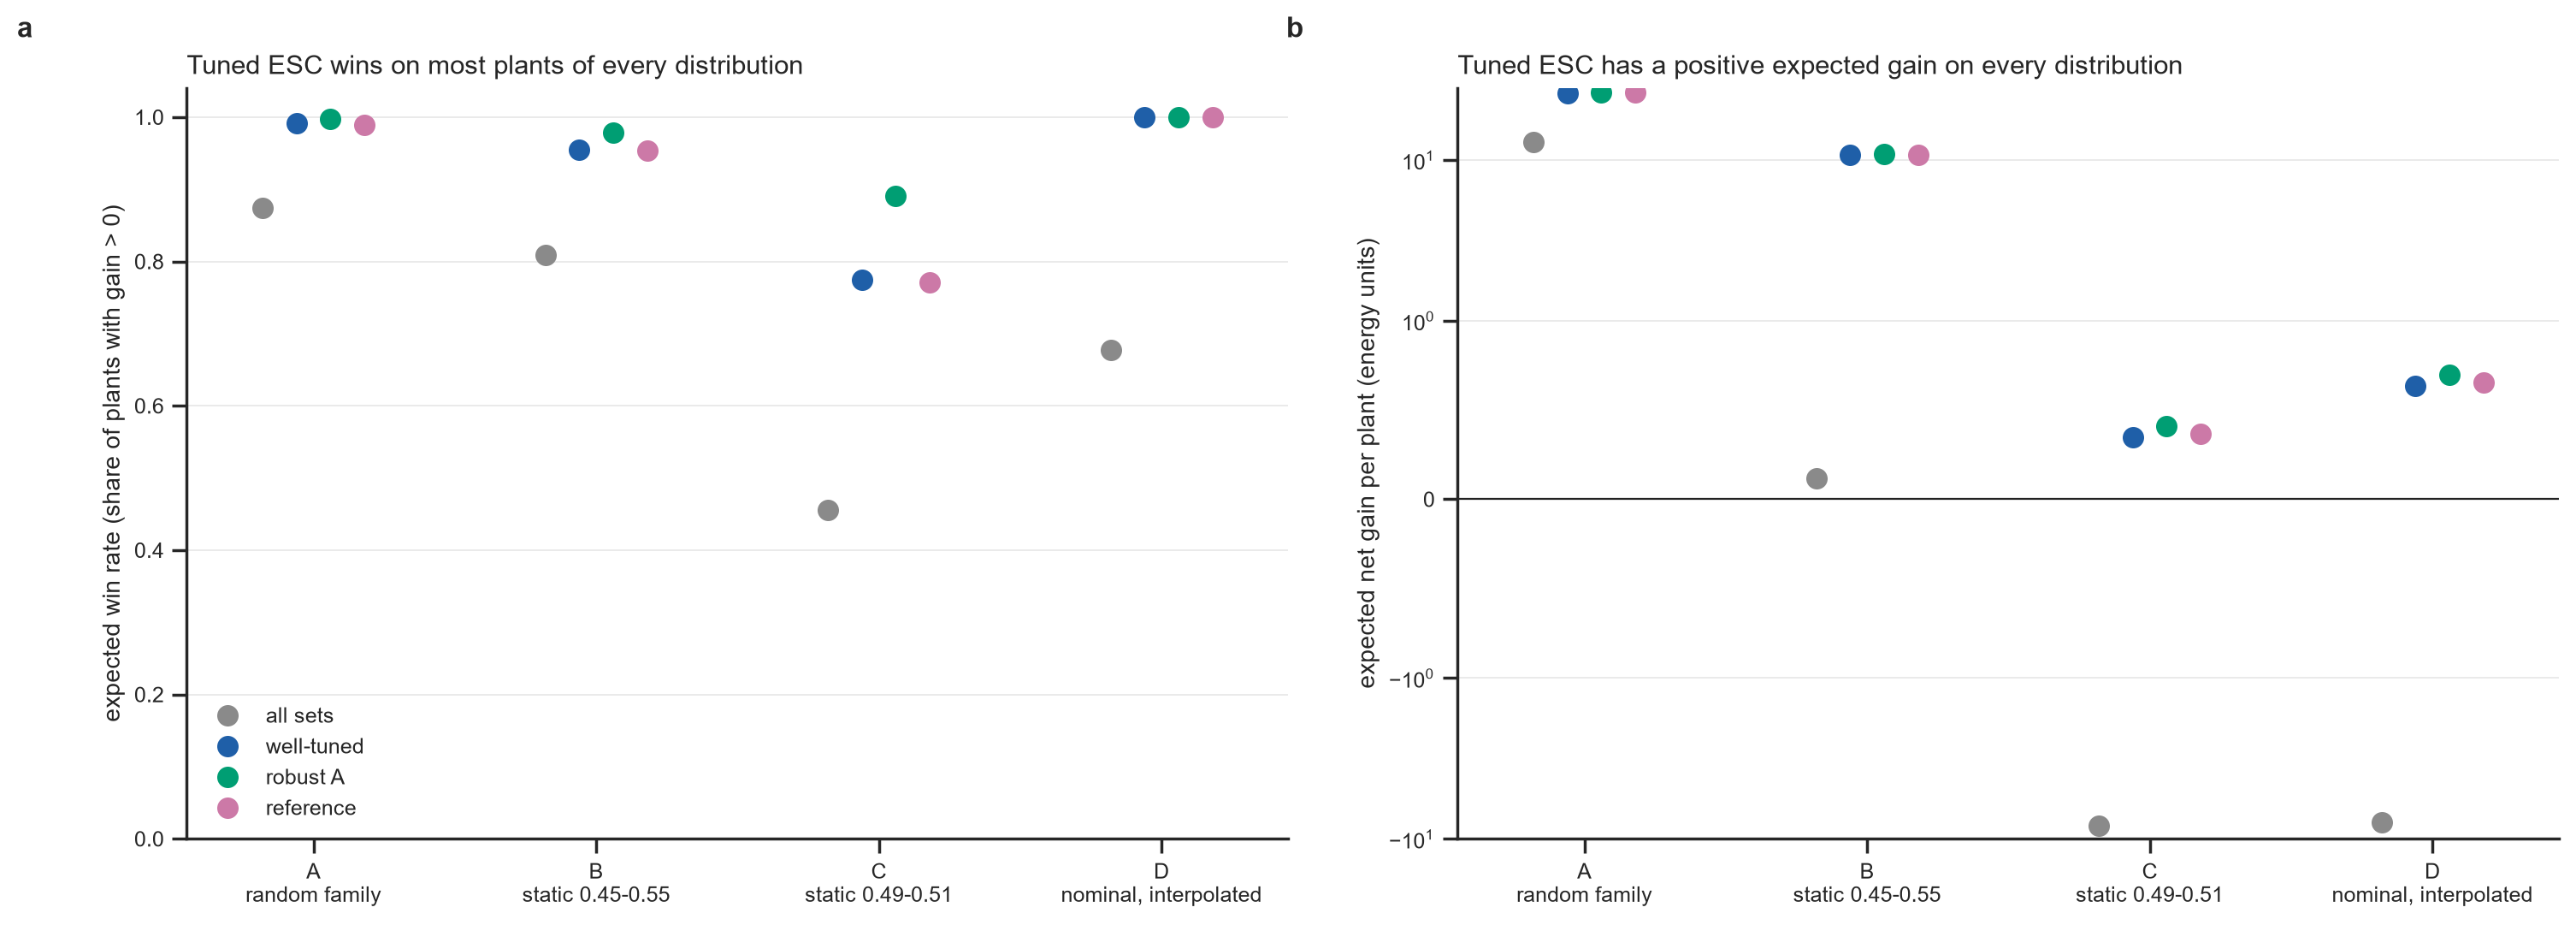

In [18]:
DIST_NAMES = ['A random family', 'B static 0.45-0.55', 'C static 0.49-0.51', 'D nominal, interpolated']
DIST_GROUPS = ['all sets', 'well-tuned', 'robust A', 'reference']


def p4(ax, which):
    xpos = np.arange(len(DIST_NAMES))
    for j, name in enumerate(DIST_GROUPS):
        vals = [dist_values[name][d][which] for d in DIST_NAMES]
        ax.plot(xpos + (j - 1.5) * 0.12, vals, 'o', ms=8, color=G_COL[name], label=name)
    ax.set_xticks(xpos); ax.set_xticklabels([d.replace(' ', '\n', 1) for d in DIST_NAMES])
    ax.grid(axis='x', visible=False); ax.margins(x=0.08)
    if which == 0:
        ax.set_ylim(0, 1.04); ax.set_ylabel('expected win rate (share of plants with gain > 0)')
        ax.set_title('Tuned ESC wins on most plants of every distribution')
        ax.legend(loc='lower left')
    else:
        ax.axhline(0, color=esc.COLORS['ideal'], lw=0.8)
        ax.set_yscale('symlog', linthresh=1); ax.set_ylabel('expected net gain per plant (energy units)')
        ax.set_title('Tuned ESC has a positive expected gain on every distribution')


P4 = [lambda ax: p4(ax, 0), lambda ax: p4(ax, 1)]
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
fig.dpi = 200
for ax, panel, letter in zip(axs.flat, P4, 'ab'):
    panel(ax); esc.panel_letter(ax, letter)
fig.tight_layout()
plt.show()

The same two panels, one per figure:

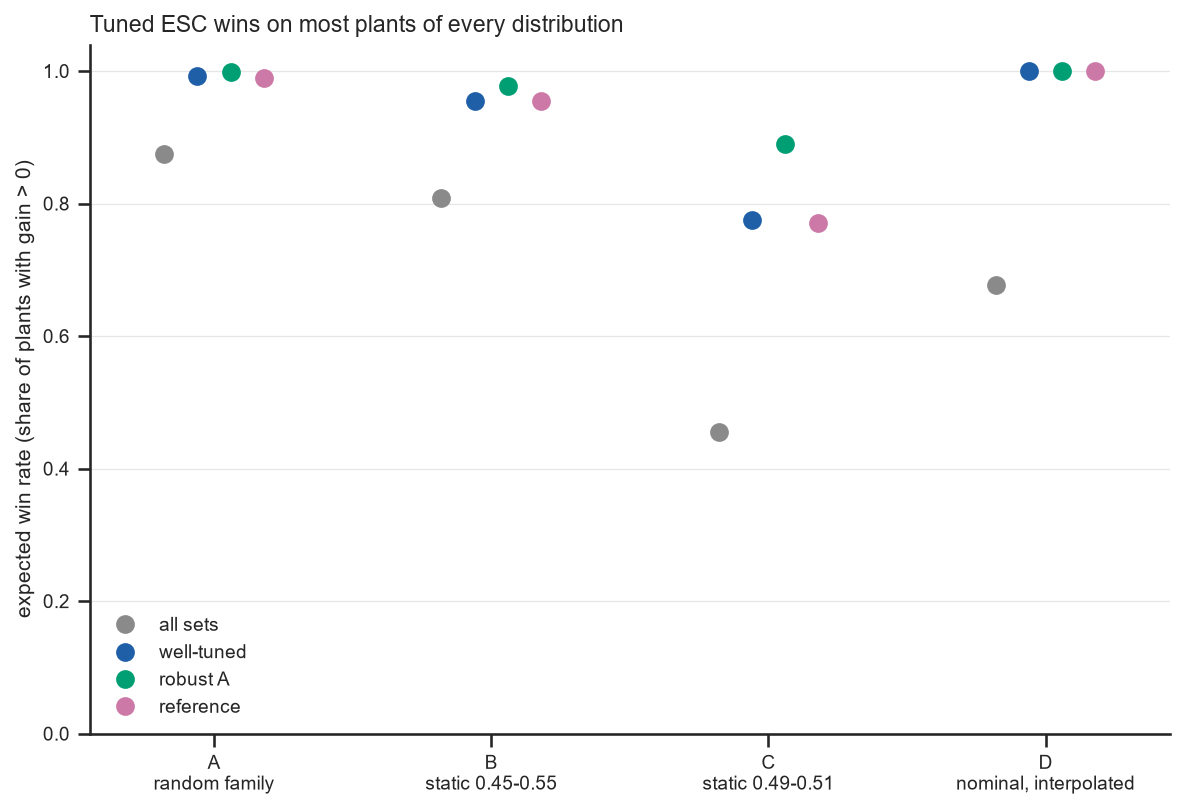

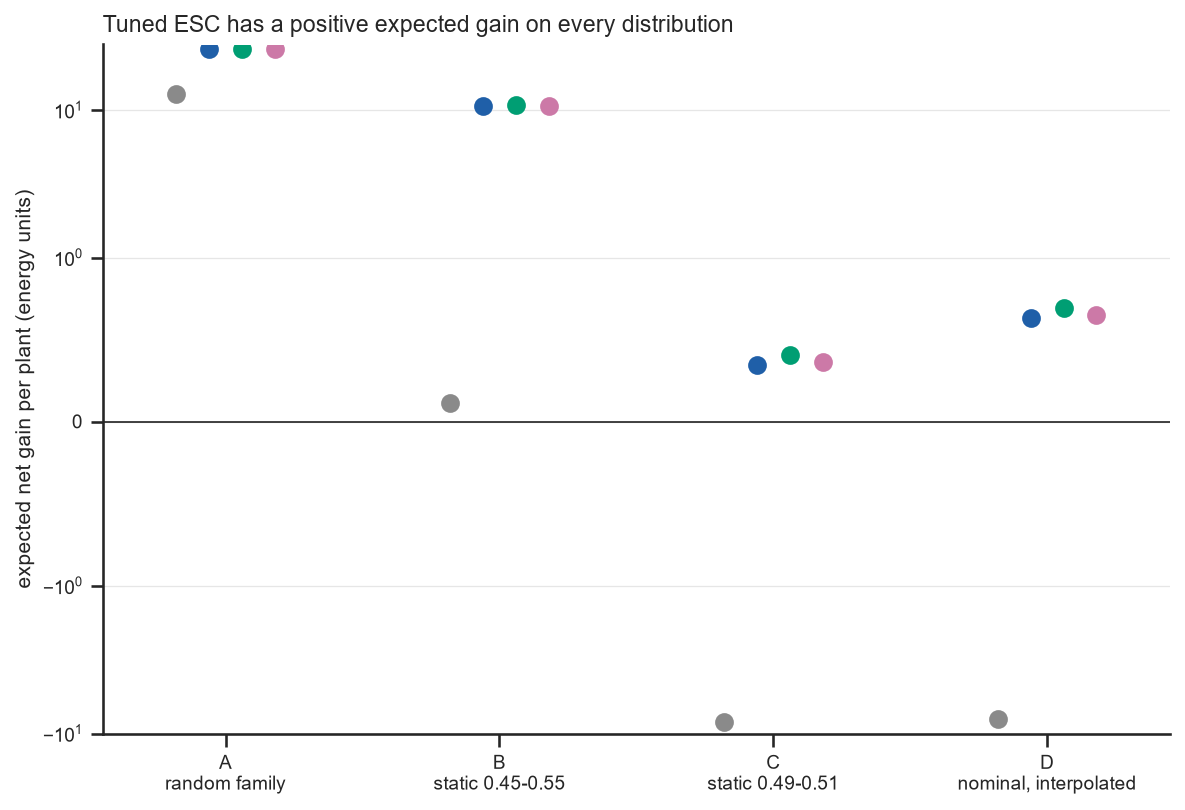

In [19]:
for panel in P4:
    fig, ax = plt.subplots(figsize=(8, 5.5)); fig.dpi = 150
    panel(ax); fig.tight_layout(); plt.show()

**What this shows.**
* For the tuned groups the win rate against distance is close to a step: 0 for plants exactly at 0.5 (only ties or
  small losses are possible there) and close to 1 beyond a few thousandths (panel a). The dip of the well-tuned group
  near 0.0075 comes from the sine plants centred on 0.5, whose optimum oscillates too fast to follow. "All sets" never
  reaches 1, because the badly tuned sets also lose on plants far from 0.5. Wins grow as offset$^2$ (they follow the
  margin), while the losses of the tuned groups stay small at every distance (panel b).
* The measured break-even distance of the well-tuned sets is close to the predicted $\delta^*$ but somewhat larger
  (printed ratio $x^*/\delta^*$). The fit includes drifting plants, where the ESC also loses to lag, so $-b$ is a bit
  larger than $L_\mathrm{dith}$. For sets with a very small $L_\mathrm{dith}$ these other losses set the break-even, not
  the dither (points above the line in panel d, e.g. the "fastest" set).
* The answer depends on the plant distribution, not only on the controller (table and Figure 4). For the random family
  and for static plants spread over 0.45-0.55, tuned ESC wins on nearly all of the distribution and gains on average
  between about 10 and 26 units per run. If the plant is known to stay within $\pm 0.01$ of 0.5, a smaller share of the
  distribution is won. The expected gain is then a fraction of one unit: positive for the tuned groups, negative for
  "all sets". For the nominal plant ($r_\mathrm{ideal} \approx 0.507$) every tuned set wins, but by less than one unit.

## 4. Tuned against untuned sets

**What and why.** The answer to "is ESC better?" depends on how the ESC is tuned. We define a **robust** set by
1. worst-plant energy score $\eta \ge 0.9$ on every plant with margin above the floor of 1 unit (= robust A), and
2. settled within 0.01 of $r_\mathrm{ideal}$ (settling time at tolerance 0.01 exists) on every plant.

We first check how the count depends on the floor, and which plants make the settling condition hard. Then we compare
the robust sets with all sets, and map the win rate and the expected net gain over the ESC parameters to see where
superiority fails.

In [20]:
not_sine = family != 'sine'
count_rows = []
for floor in [0.5, 1, 2, 5, 10]:
    hm = margin > floor
    ra = (gain[:, hm] / margin[hm]).min(1) >= 0.9
    count_rows.append({'margin floor': floor, 'plants in eta': int(hm.sum()), 'robust A': int(ra.sum()),
                       'robust A + settled on every plant': int((ra & settled.all(1)).sum()),
                       'robust A + settled on every non-sine plant': int((ra & settled[:, not_sine].all(1)).sum())})
print(pd.DataFrame(count_rows).set_index('margin floor').to_string())
print(f'\nsets that settle on every plant (no eta condition): {settled.all(1).sum()}; on every non-sine plant: '
      f'{settled[:, not_sine].all(1).sum()}')
hard = pd.DataFrame({'family': family, 'r_ideal_0': plants['r_ideal_0'].values, 'size': plants['drift_size'].values,
                     'period or time [s]': plants['drift_time'].values, 'share of sets settled': settled.mean(0),
                     'share of robust A settled': settled[robust_A].mean(0)})
print('\nplants where the fewest sets settle within 0.01:')
print(hard.sort_values('share of sets settled').head(8).round(3).to_string())

              plants in eta  robust A  robust A + settled on every plant  robust A + settled on every non-sine plant
margin floor                                                                                                        
0.5                     583        21                                  2                                          19
1.0                     569        26                                  2                                          24
2.0                     542        27                                  2                                          25
5.0                     484        27                                  2                                          25
10.0                    385        62                                  3                                          53

sets that settle on every plant (no eta condition): 3; on every non-sine plant: 511

plants where the fewest sets settle within 0.01:
    family  r_ideal_0  size  period or time [s

The literal criterion leaves very few sets, because almost no set settles within 0.01 on the fast sine plants (period
10 s), whose optimum moves faster than any well-behaved ESC can follow. Below, **robust** therefore means robust A *and*
settled on every non-sine plant, with the margin floor of 1 unit. The strict version (settled on every plant, sine
included) is shown alongside.

In [21]:
robust = robust_A & settled[:, not_sine].all(1)
robust_strict = robust_A & settled.all(1)
GROUPS4 = {'all sets': GROUPS['all sets'], 'not well-tuned': ~well_tuned_set, 'well-tuned': well_tuned_set,
           'robust A': robust_A, 'robust': robust, 'robust (strict)': robust_strict}
print({name: int(gm.sum()) for name, gm in GROUPS4.items()})
print(f'mean margin over the 600 plants (the most any controller can gain per plant on average): {margin.mean():.2f} units')
with_ci(group_summary(GROUPS4))

{'all sets': 2005, 'not well-tuned': 1801, 'well-tuned': 204, 'robust A': 26, 'robust': 24, 'robust (strict)': 2}
mean margin over the 600 plants (the most any controller can gain per plant on average): 26.94 units


,sets,plants,win rate,clear win,tie,clear loss,mean win,mean loss,wins / losses,net gain,worst loss
all sets,2005,600,"0.871 [0.859, 0.882]",0.802,0.11,0.0881,"22.8 [20.9, 24.8]","54.9 [50.3, 60.1]","2.82 [2.51, 3.15]","12.8 [10.9, 14.8]",-2.24e+03
not well-tuned,1801,600,"0.858 [0.846, 0.87]",0.785,0.117,0.0979,"22.3 [20.4, 24.2]","55.5 [51.1, 60.5]","2.44 [2.17, 2.73]","11.3 [9.39, 13.2]",-2.24e+03
well-tuned,204,600,"0.985 [0.976, 0.993]",0.943,0.0544,0.00228,"27 [24.7, 29.3]","5.88 [2.91, 12.2]","295 [195, 539]","26.5 [24.2, 28.8]",-806
robust A,26,600,"0.992 [0.985, 0.998]",0.948,0.0517,0,"27 [24.8, 29.3]","0.0311 [0.005, 0.0783]","1.09e+05 [3.9e+04, 1.49e+06]","26.8 [24.5, 29.1]",-0.539
robust,24,600,"0.992 [0.985, 0.998]",0.948,0.0517,0,"27 [24.8, 29.3]","0.0275 [0.0053, 0.0647]","1.21e+05 [4.51e+04, 1.37e+06]","26.8 [24.5, 29.1]",-0.289
robust (strict),2,600,"0.993 [0.987, 0.998]",0.948,0.0517,0,"27 [24.7, 29.3]","0.0162 [0.00136, 0.0484]","2.49e+05 [8.71e+04, 5.92e+06]","26.8 [24.5, 29.1]",-0.0627


In [22]:
robust_list = sets.loc[robust, ['set', 'optimizer_gain', 'dither_amplitude', 'dither_frequency', 'chosen']].assign(
    lam_avg=lam_nom[robust], L_dith=L_nom[robust], worst_eta=worst_eta[robust],
    win_rate=per_set.loc[robust, 'win rate'].values, net_gain=per_set.loc[robust, 'net gain'].values,
    largest_loss=per_set.loc[robust, 'largest loss'].values, strict=robust_strict[robust])
print(f'robust sets: k {k[robust].min():.3g} to {k[robust].max():.3g}, a {a[robust].min():.3g} to {a[robust].max():.3g}, '
      f'f {f[robust].min():.3g} to {f[robust].max():.3g} Hz, lambda_avg {lam_nom[robust].min():.2f} to '
      f'{lam_nom[robust].max():.2f} 1/s, L_dith {L_nom[robust].min():.2g} to {L_nom[robust].max():.2g}')
robust_list.sort_values('worst_eta', ascending=False).round(4)

robust sets: k 1.76 to 4.43, a 0.02 to 0.32, f 5.14 to 9.93 Hz, lambda_avg 1.90 to 3.40 1/s, L_dith 0.00053 to 0.069


,set,optimizer_gain,dither_amplitude,dither_frequency,chosen,lam_avg,L_dith,worst_eta,win_rate,net_gain,largest_loss,strict
1843,1843,3.4532,0.0896,9.1549,NaN,2.8123,0.0057,0.9607,0.9933,26.8412,0.0239,False
1363,1363,3.2042,0.0461,8.7901,NaN,2.7213,0.0016,0.9576,0.9933,26.8789,0.0068,False
1123,1123,4.1123,0.1114,9.5926,NaN,3.1916,0.0080,0.9506,0.9933,26.8234,0.0341,True
1147,1147,2.7586,0.0330,7.4038,NaN,2.7984,0.0012,0.9504,0.9933,26.8810,0.0050,False
763,763,2.8638,0.0787,8.4982,NaN,2.5186,0.0051,0.9465,0.9933,26.8467,0.0212,False
403,403,3.0864,0.1331,9.6656,NaN,2.3768,0.0112,0.9458,0.9933,26.8352,0.0471,False
2003,2003,3.3402,0.2202,9.9331,NaN,2.5010,0.0290,0.9455,0.9917,26.8091,0.1222,False
1723,1723,2.6906,0.0504,9.5197,NaN,2.1048,0.0017,0.9329,0.9933,26.8714,0.0069,False
787,787,3.0104,0.0200,6.6742,NaN,3.4018,0.0005,0.9299,0.9933,26.7778,0.0045,False
1627,1627,2.4351,0.0766,8.0605,NaN,2.2619,0.0053,0.9282,0.9933,26.8456,0.0222,False


**Figure 5: where superiority fails.** Win rate (top row) and expected net gain per plant (bottom row) of the 2,005 sets,
as smoothed binned maps (`esc.binned_map`, every set counts once; mean over the sets in a bin). Left: over gain $k$ and
amplitude $a$ (averaged over all frequencies, so low-$f$ failures colour the large-$k$ bins even where high-$f$ sets work); middle: over $k$ and frequency $f$, with the lines
$\lambda_\mathrm{avg} = 0.1$ and 3 1/s and $\lambda_\mathrm{avg} = \omega_c = 2f$ (the filter cut-off), all for the nominal plant; right: over the two averaged quantities $\lambda_\mathrm{avg}$ and
$L_\mathrm{dith}$ (nominal plant) with the well-tuned window. Open circles: the robust sets. The win rate colour scale
starts at 0.5 (lower values have the darkest colour). The net-gain colour scale is centred at 0 and saturates below
$-20$.

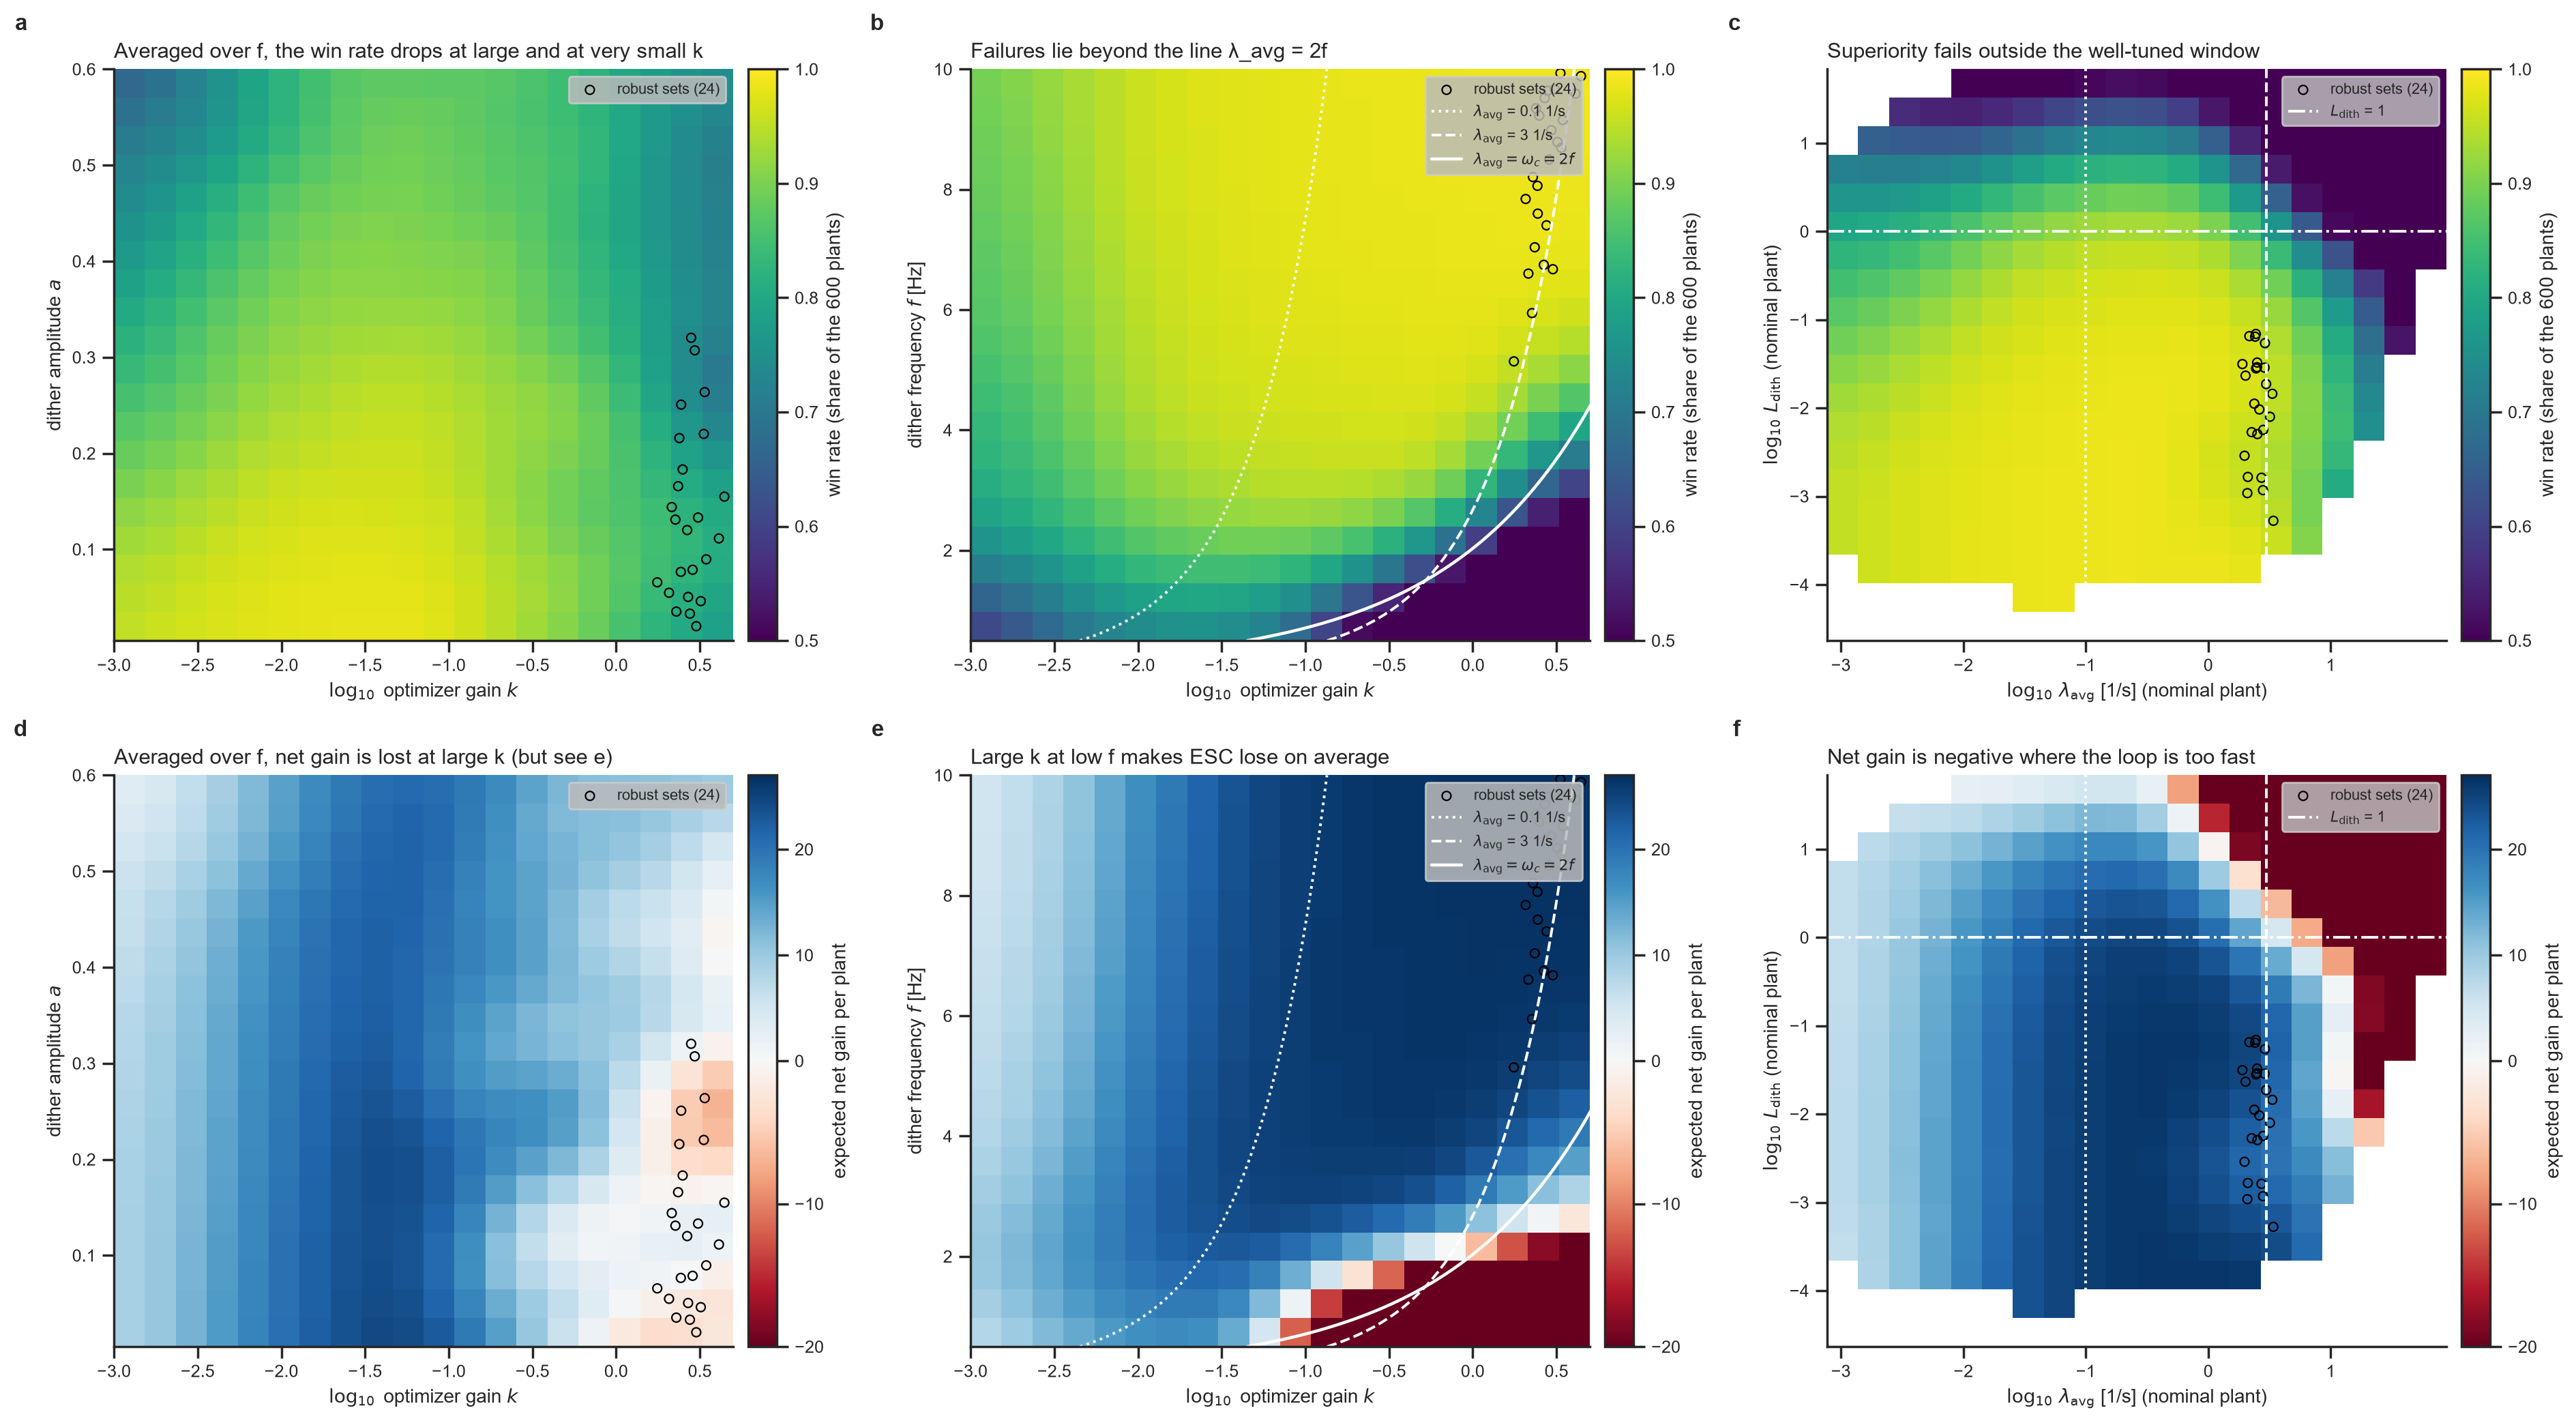

In [23]:
NB = esc.bins_for(n_sets)
log_k, log_lam, log_L = np.log10(k), np.log10(lam_nom), np.log10(L_nom)
PLANES = {'ka': (log_k, a, np.linspace(-3, np.log10(5), NB + 1), np.linspace(0.005, 0.6, NB + 1),
                 r'$\log_{10}$ optimizer gain $k$', esc.label('dither_amplitude')),
          'kf': (log_k, f, np.linspace(-3, np.log10(5), NB + 1), np.linspace(0.5, 10, NB + 1),
                 r'$\log_{10}$ optimizer gain $k$', esc.label('dither_frequency')),
          'lamL': (log_lam, log_L, np.linspace(log_lam.min(), log_lam.max(), NB + 1),
                   np.linspace(log_L.min(), log_L.max(), NB + 1),
                   r'$\log_{10}\,\lambda_\mathrm{avg}$ [1/s] (nominal plant)', r'$\log_{10}\,L_\mathrm{dith}$ (nominal plant)')}
VALUES = {'win rate': (per_set['win rate'].values, dict(cmap='viridis', vmin=0.5, vmax=1)),
          'net gain': (per_set['net gain'].values, dict(cmap='RdBu', norm=TwoSlopeNorm(vmin=-20, vcenter=0, vmax=27)))}
TITLES = {('win rate', 'ka'): 'Averaged over f, the win rate drops at large and at very small k',
          ('win rate', 'kf'): 'Failures lie beyond the line λ_avg = 2f',
          ('win rate', 'lamL'): 'Superiority fails outside the well-tuned window',
          ('net gain', 'ka'): 'Averaged over f, net gain is lost at large k (but see e)',
          ('net gain', 'kf'): 'Large k at low f makes ESC lose on average',
          ('net gain', 'lamL'): 'Net gain is negative where the loop is too fast'}


def p5(ax, value, plane):
    xv, yv, xe, ye, xl, yl = PLANES[plane]
    vals, style = VALUES[value]
    grid = esc.binned_map(xv, yv, vals, xe, ye)
    mesh = ax.pcolormesh(xe, ye, grid.T, shading='flat', **style)
    cb = ax.figure.colorbar(mesh, ax=ax, pad=0.02)
    cb.set_label('win rate (share of the 600 plants)' if value == 'win rate' else 'expected net gain per plant')
    ax.scatter(xv[robust], yv[robust], s=22, facecolor='none', edgecolor='black', lw=0.8, label=f'robust sets ({robust.sum()})')
    if plane == 'kf':
        ff = np.linspace(0.5, 10, 200)
        for lv, ls in [(esc.LAM_WINDOW[0], ':'), (esc.LAM_WINDOW[1], '--')]:
            ax.plot(np.log10(lv / (2 * esc.N_REF ** 2 * esc.c_factor(ff))), ff, color='white', ls=ls, lw=1.4,
                    label=f'$\\lambda_\\mathrm{{avg}}$ = {lv:g} 1/s')
        ax.plot(np.log10(2 * ff / (2 * esc.N_REF ** 2 * esc.c_factor(ff))), ff, color='white', ls='-', lw=1.6,
                label='$\\lambda_\\mathrm{avg} = \\omega_c = 2f$')
        ax.set_xlim(xe[0], xe[-1])
    if plane == 'lamL':
        ax.axvline(np.log10(esc.LAM_WINDOW[0]), color='white', ls=':', lw=1.4)
        ax.axvline(np.log10(esc.LAM_WINDOW[1]), color='white', ls='--', lw=1.4)
        ax.axhline(np.log10(esc.L_DITH_MAX), color='white', ls='-.', lw=1.4, label='$L_\\mathrm{dith}$ = 1')
    ax.set_xlabel(xl); ax.set_ylabel(yl); ax.grid(False)
    ax.set_title(TITLES[(value, plane)])
    leg = ax.legend(loc='upper right', fontsize=8, facecolor='#bbbbbb', framealpha=0.85, frameon=True)


P5 = [(lambda ax, v=v, p=p: p5(ax, v, p)) for v in VALUES for p in PLANES]
fig, axs = plt.subplots(2, 3, figsize=(19, 10.5))
fig.dpi = 200
for ax, panel, letter in zip(axs.flat, P5, 'abcdef'):
    panel(ax); esc.panel_letter(ax, letter)
fig.tight_layout()
plt.show()

The same six panels, one per figure:

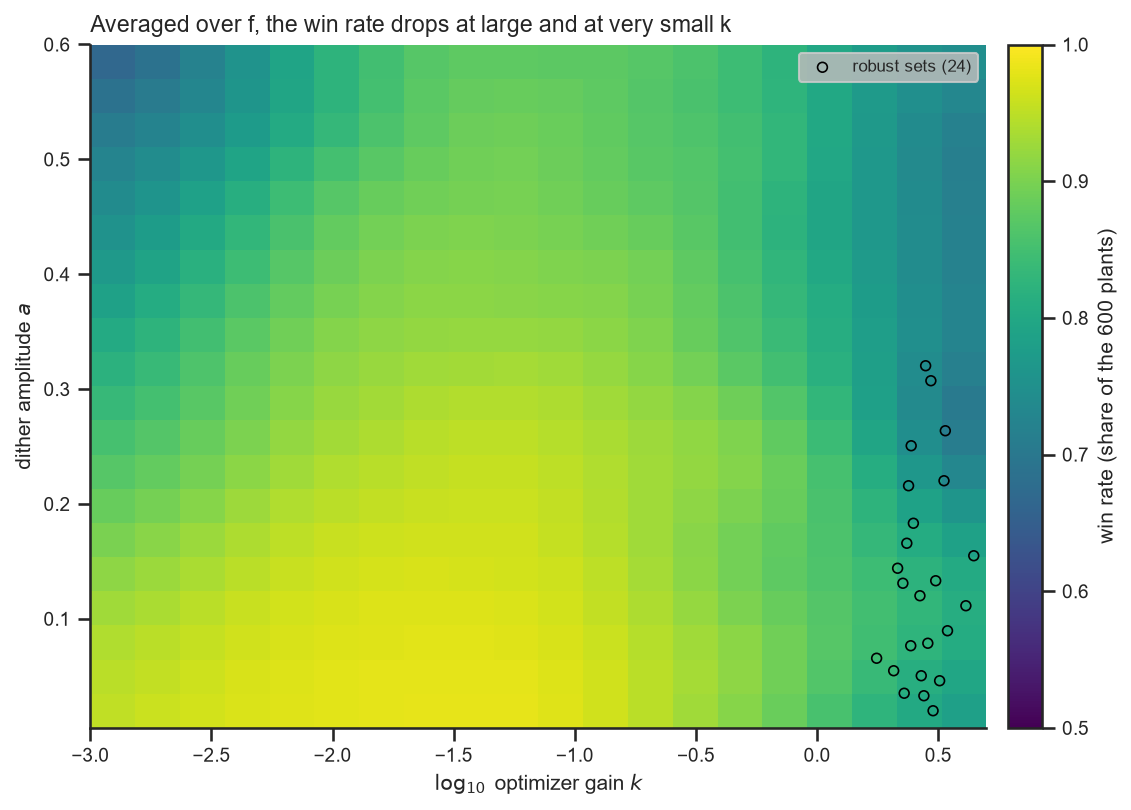

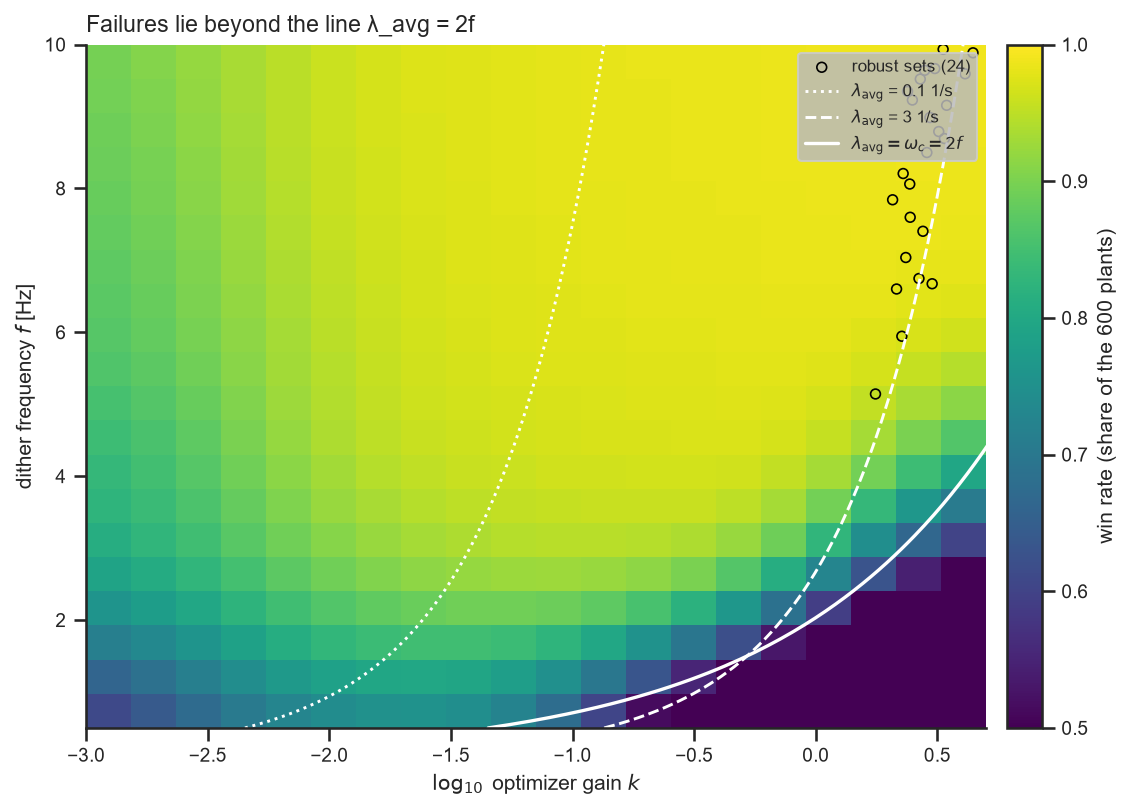

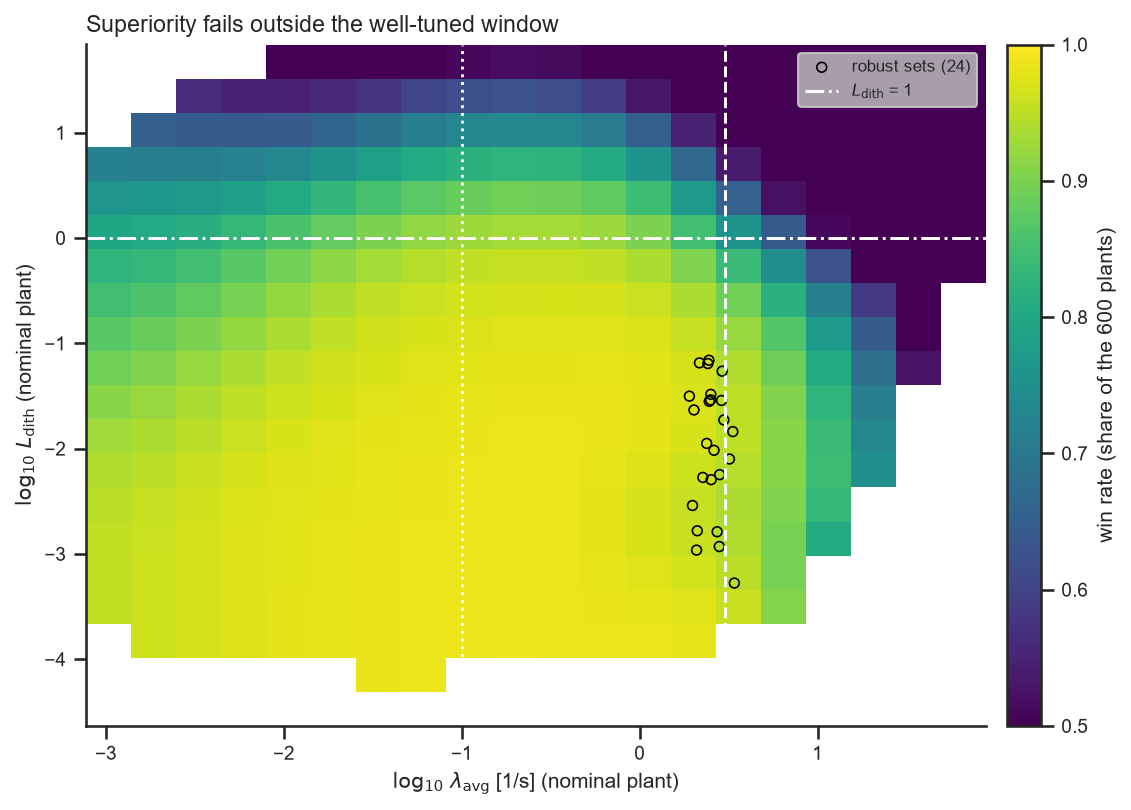

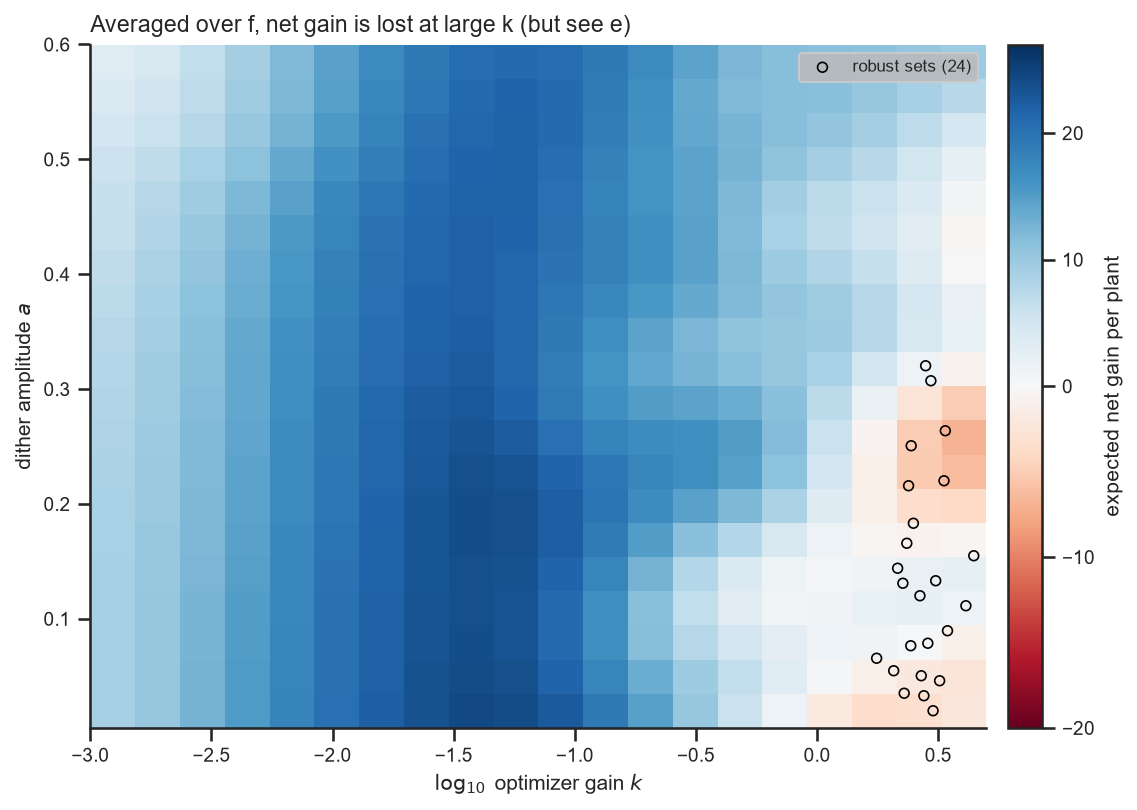

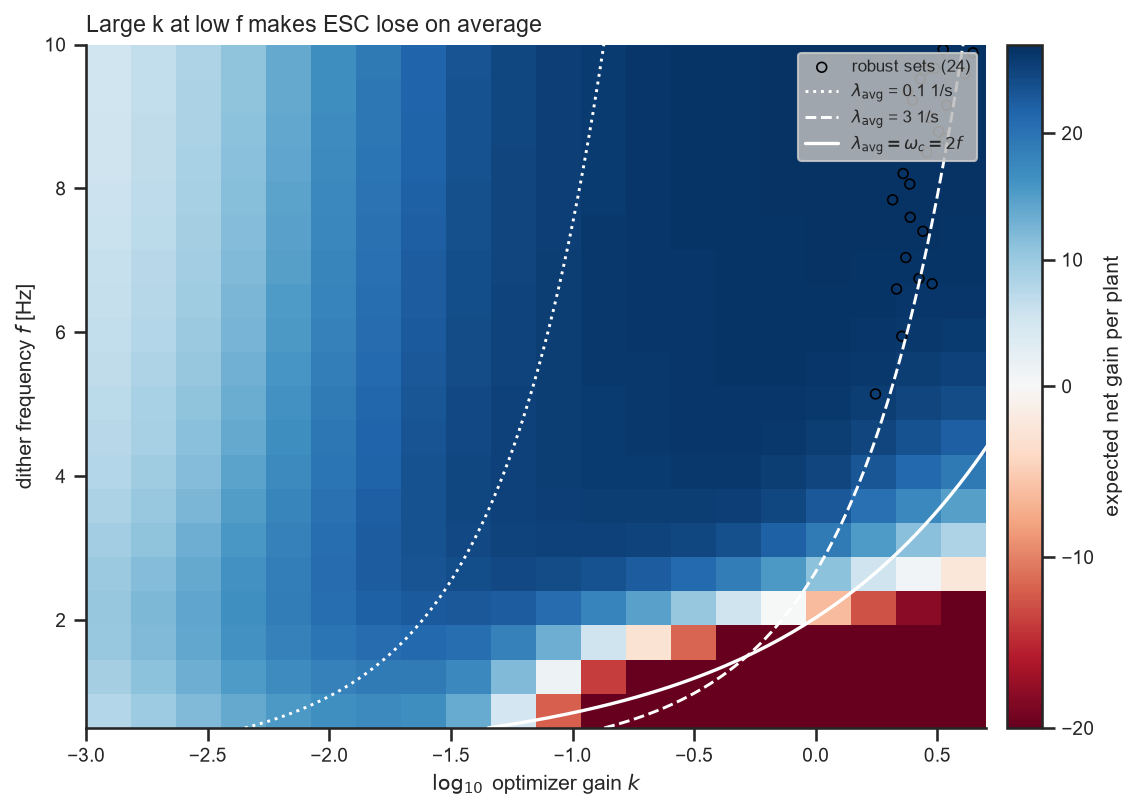

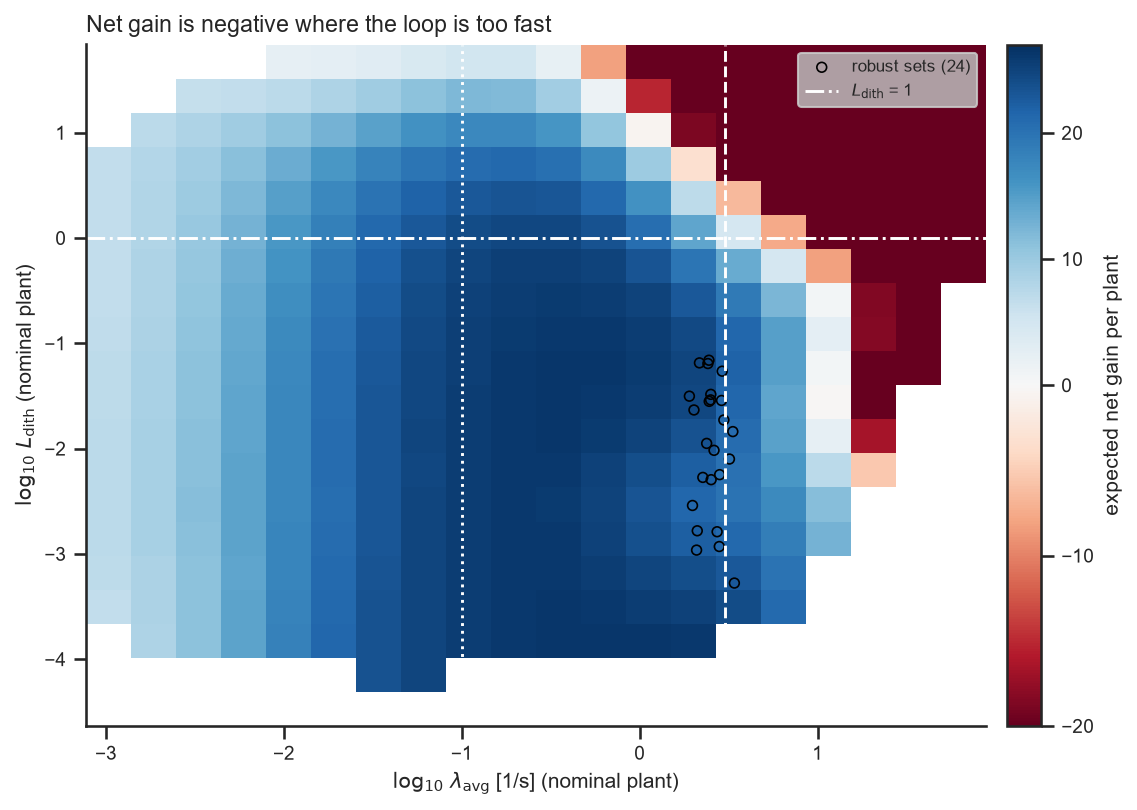

In [24]:
for panel in P5:
    fig, ax = plt.subplots(figsize=(8, 5.5)); fig.dpi = 150
    panel(ax); fig.tight_layout(); plt.show()

In [25]:
in_window = (lam_nom > esc.LAM_WINDOW[0]) & (lam_nom < esc.LAM_WINDOW[1])
print(f'robust sets: lambda_avg / 2f from {(lam_nom / (2 * f))[robust].min():.3f} to {(lam_nom / (2 * f))[robust].max():.3f}')
REGIONS = {'lambda_avg < 0.1 (too slow)': lam_nom < esc.LAM_WINDOW[0],
           'lambda_avg > 3 (too fast)': lam_nom > esc.LAM_WINDOW[1],
           'L_dith > 1 (dither too costly)': L_nom > esc.L_DITH_MAX,
           'in window, L_dith < 1': in_window & (L_nom < esc.L_DITH_MAX),
           'in window, a < 0.02 (tiny dither)': in_window & (a < 0.02),
           'in window, a < 0.02, lambda_avg < 0.5 x 2f': in_window & (a < 0.02) & (lam_nom < f),
           'lambda_avg > 3 but < 0.2 x 2f': (lam_nom > esc.LAM_WINDOW[1]) & (lam_nom < 0.4 * f),
           'lambda_avg > 2f (faster than the filters)': lam_nom > 2 * f,
           'k > 1 and f < 2 Hz': (k > 1) & (f < 2),
           'k < 0.003': k < 0.003}
reg_rows = []
for rname, rm in REGIONS.items():
    ps = per_set[rm]
    reg_rows.append({'region (nominal plant)': rname, 'sets': int(rm.sum()), 'median win rate': ps['win rate'].median(),
                     'median net gain': ps['net gain'].median(), 'share with net gain < 0': (ps['net gain'] < 0).mean(),
                     'median largest loss': ps['largest loss'].median()})
pd.DataFrame(reg_rows).set_index('region (nominal plant)').round(3)

robust sets: lambda_avg / 2f from 0.102 to 0.255


,sets,median win rate,median net gain,share with net gain < 0,median largest loss
region (nominal plant),,,,,
lambda_avg < 0.1 (too slow),939,0.948,17.787,0.007,1.900
lambda_avg > 3 (too fast),255,0.618,14.707,0.424,69.372
L_dith > 1 (dither too costly),389,0.723,15.826,0.262,25.756
"in window, L_dith < 1",653,0.982,26.397,0.003,5.294
"in window, a < 0.02 (tiny dither)",20,0.988,26.347,0.100,4.271
"in window, a < 0.02, lambda_avg < 0.5 x 2f",18,0.988,26.389,0.000,3.705
lambda_avg > 3 but < 0.2 x 2f,7,0.987,26.721,0.000,0.360
lambda_avg > 2f (faster than the filters),149,0.190,-26.143,0.785,253.757
k > 1 and f < 2 Hz,59,0.042,-76.824,0.966,324.378


**Why the too-fast sets fail: the loop must stay slower than its own filters.** The averaged theory behind
$\lambda_\mathrm{avg}$ assumes that $\hat r$ moves slowly compared with the high-pass and low-pass filters. Both have the
cut-off $\omega_c = 2\pi f/\pi = 2f$ rad/s. The ratio $\lambda_\mathrm{avg}/\omega_c$ measures how well this holds. A fixed
upper limit $\lambda_\mathrm{avg} < 3$ 1/s is only a stand-in for it: at $f = 10$ Hz the filters are fast and
$\lambda_\mathrm{avg} = 3$ 1/s is harmless, while at $f = 0.8$ Hz it is not. Below, the sets are binned by
$\lambda_\mathrm{avg}/\omega_c$ (nominal plant).

In [26]:
ratio_c = lam_nom / (2 * f)
rc_edges = np.arange(-4, 1.01, 0.25)
rc_bin = pd.cut(np.log10(ratio_c), rc_edges)
by_ratio = pd.DataFrame({'net': per_set['net gain'], 'win': per_set['win rate'], 'bin': rc_bin}).groupby('bin', observed=True).agg(
    sets=('net', 'size'), share_net_negative=('net', lambda v: (v < 0).mean()), median_win_rate=('win', 'median'),
    median_net_gain=('net', 'median'))
rc_mid = 10 ** np.array([(iv.left + iv.right) / 2 for iv in by_ratio.index])
by_ratio.index = [f'{10 ** iv.left:.2g} to {10 ** iv.right:.2g}' for iv in by_ratio.index]
by_ratio.index.name = 'lambda_avg / omega_c'
for name, cond in [('lambda_avg > 3 and lambda_avg/omega_c < 0.2', (lam_nom > 3) & (ratio_c < 0.2)),
                   ('lambda_avg > 3 and lambda_avg/omega_c >= 0.2', (lam_nom > 3) & (ratio_c >= 0.2)),
                   ('lambda_avg < 3 and lambda_avg/omega_c >= 0.2', (lam_nom < 3) & (ratio_c >= 0.2))]:
    print(f'{name}: {cond.sum()} sets, share with net gain < 0: {(per_set.loc[cond, "net gain"] < 0).mean():.3f}, '
          f'median win rate {per_set.loc[cond, "win rate"].median():.3f}')
by_ratio.round(3)

lambda_avg > 3 and lambda_avg/omega_c < 0.2: 7 sets, share with net gain < 0: 0.000, median win rate 0.987
lambda_avg > 3 and lambda_avg/omega_c >= 0.2: 248 sets, share with net gain < 0: 0.435, median win rate 0.577
lambda_avg < 3 and lambda_avg/omega_c >= 0.2: 146 sets, share with net gain < 0: 0.096, median win rate 0.928


,sets,share_net_negative,median_win_rate,median_net_gain
lambda_avg / omega_c,,,,
0.0001 to 0.00018,69,0.000,0.893,6.251
0.00018 to 0.00032,83,0.000,0.928,9.115
0.00032 to 0.00056,99,0.000,0.932,12.568
0.00056 to 0.001,105,0.000,0.953,16.398
0.001 to 0.0018,121,0.000,0.968,19.497
0.0018 to 0.0032,124,0.000,0.970,22.762
0.0032 to 0.0056,127,0.008,0.972,24.547
0.0056 to 0.01,128,0.000,0.975,25.490
0.01 to 0.018,138,0.014,0.977,25.984


**Figure 6: superiority fails when the loop is as fast as its filters.** (a) Expected net gain of every set against
$\lambda_\mathrm{avg}/\omega_c$. (b) Share of sets with a negative expected net gain, and median win rate, per bin.

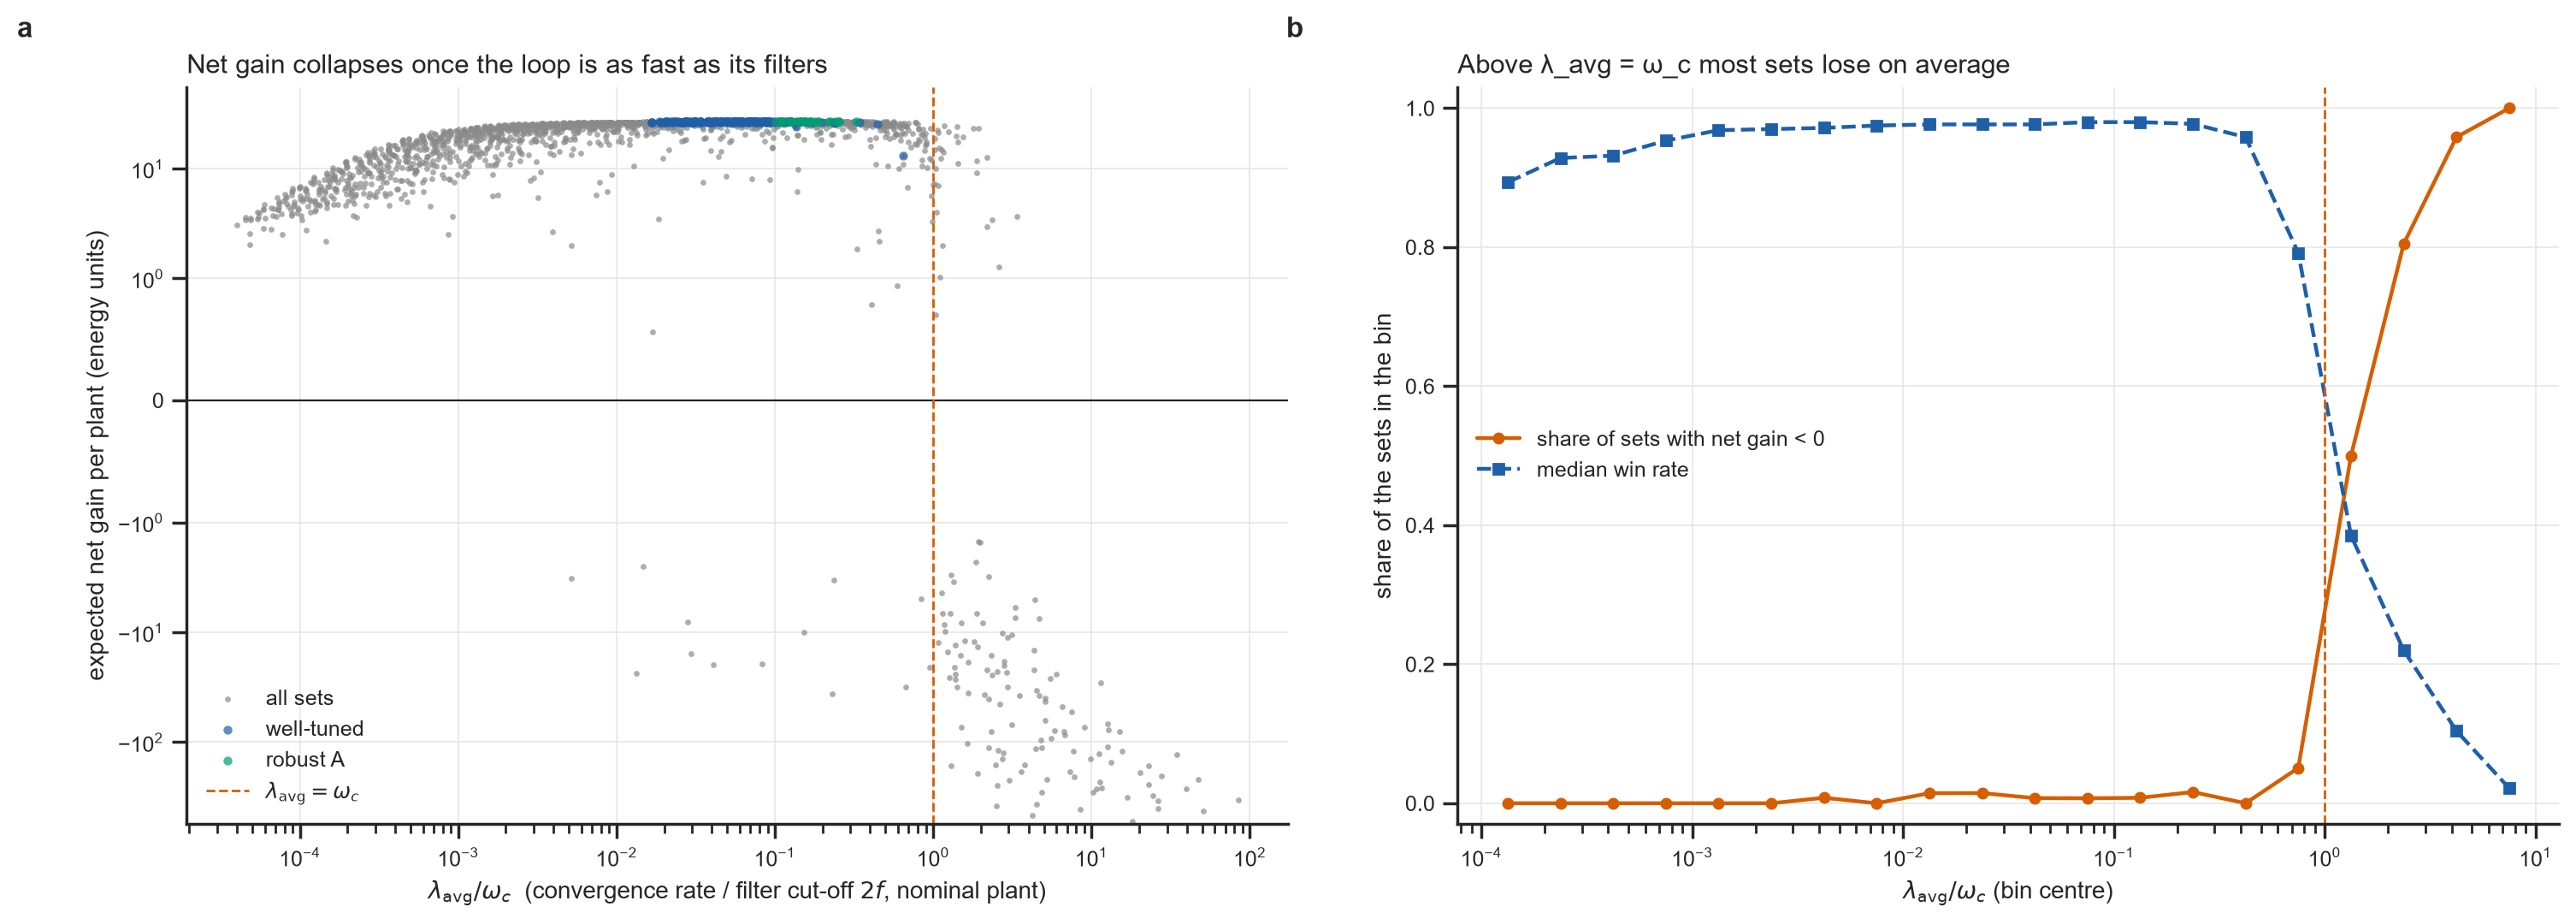

In [27]:
def p6_scatter(ax):
    for gname, gm in GROUPS.items():
        ax.scatter(ratio_c[gm], per_set.loc[gm, 'net gain'], s=6 if gname == 'all sets' else 14, color=G_COL[gname],
                   alpha=0.7, linewidths=0, label=gname, rasterized=True)
    ax.axhline(0, color=esc.COLORS['ideal'], lw=0.8)
    ax.axvline(1, color=esc.COLORS['bad'], ls='--', lw=1, label=r'$\lambda_\mathrm{avg} = \omega_c$')
    ax.set_xscale('log'); ax.set_yscale('symlog', linthresh=1)
    ax.set_xlabel(r'$\lambda_\mathrm{avg} / \omega_c$  (convergence rate / filter cut-off $2f$, nominal plant)')
    ax.set_ylabel('expected net gain per plant (energy units)')
    ax.set_title('Net gain collapses once the loop is as fast as its filters')
    ax.legend(loc='lower left')


def p6_share(ax):
    mid = rc_mid
    ax.plot(mid, by_ratio['share_net_negative'], 'o-', color=esc.COLORS['bad'], label='share of sets with net gain < 0')
    ax.plot(mid, by_ratio['median_win_rate'], 's--', color=esc.COLORS['esc'], label='median win rate')
    ax.axvline(1, color=esc.COLORS['bad'], ls='--', lw=1)
    ax.set_xscale('log'); ax.set_ylim(-0.03, 1.03)
    ax.set_xlabel(r'$\lambda_\mathrm{avg} / \omega_c$ (bin centre)'); ax.set_ylabel('share of the sets in the bin')
    ax.set_title('Above lambda_avg = omega_c most sets lose on average'.replace('lambda_avg', 'λ_avg').replace('omega_c', 'ω_c'))
    ax.legend(loc='center left')


P6 = [p6_scatter, p6_share]
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5))
fig.dpi = 200
for ax, panel, letter in zip(axs.flat, P6, 'ab'):
    panel(ax); esc.panel_letter(ax, letter)
fig.tight_layout()
plt.show()

The same two panels, one per figure:

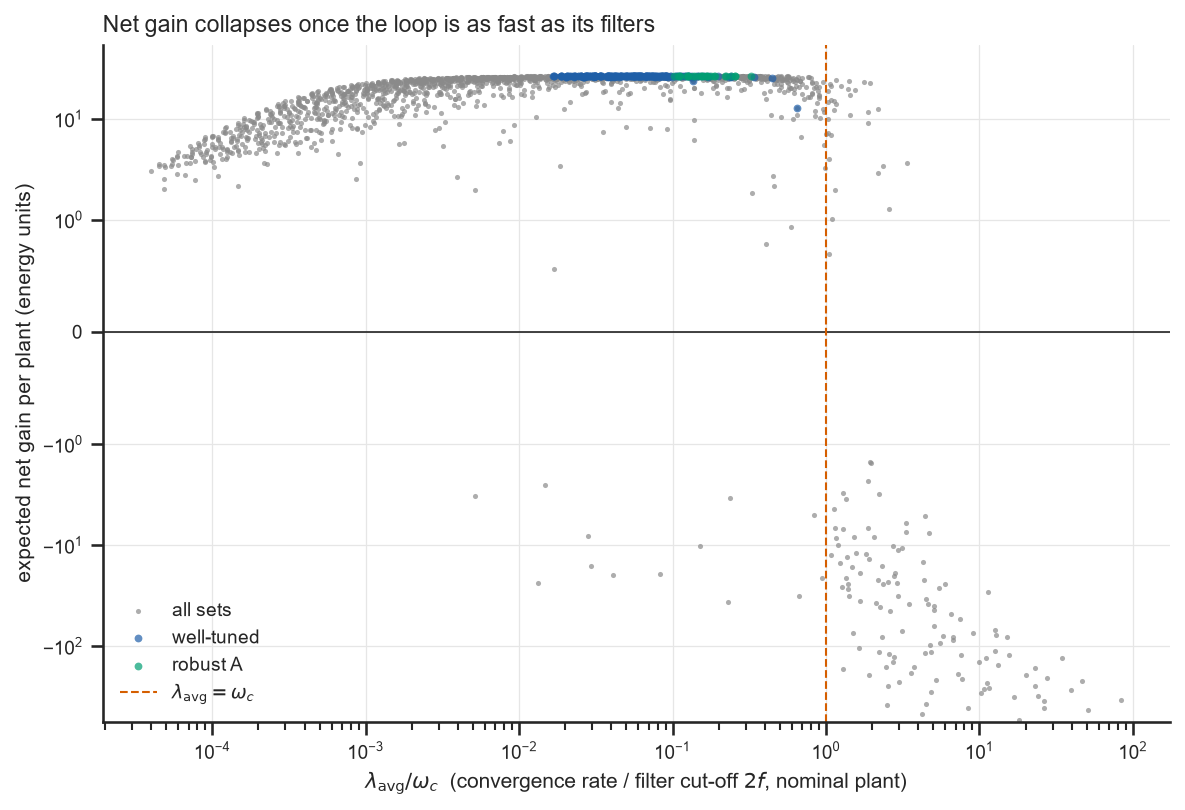

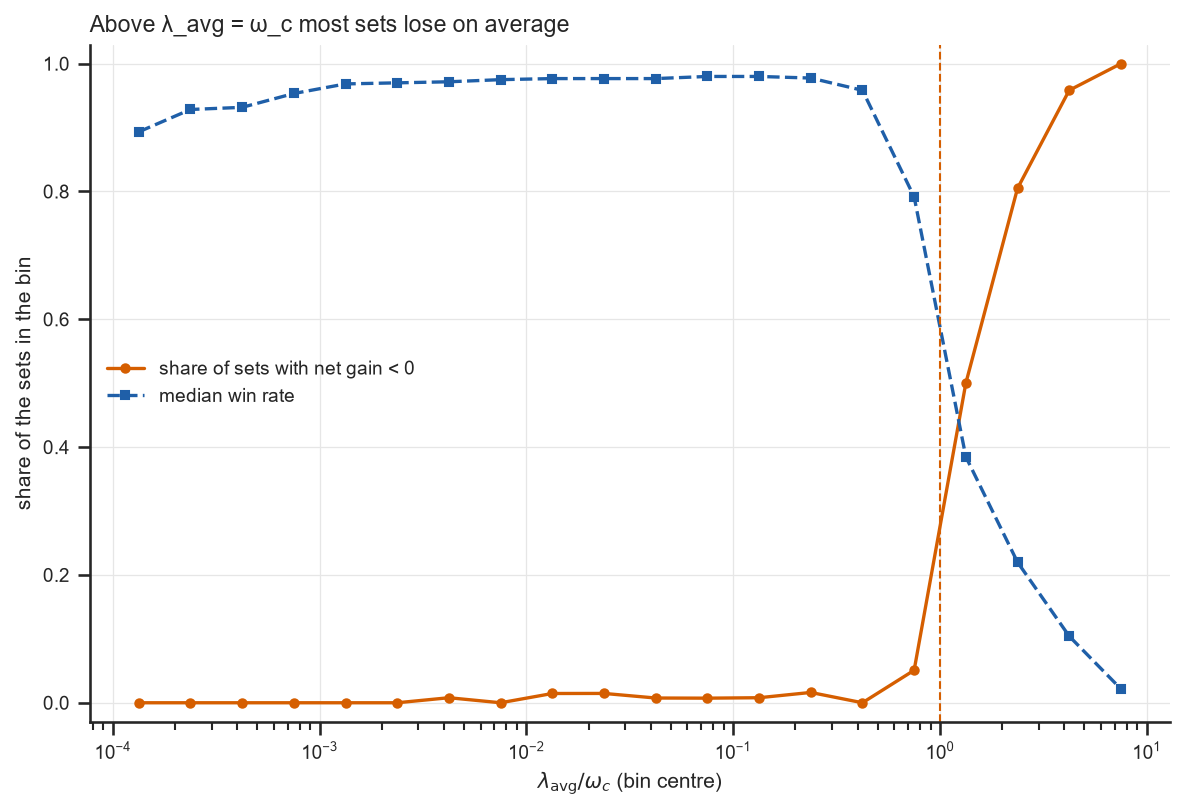

In [28]:
for panel in P6:
    fig, ax = plt.subplots(figsize=(8, 5.5)); fig.dpi = 150
    panel(ax); fig.tight_layout(); plt.show()

**What this shows.**
* The robust criterion is strict: only a small number of the 2,005 sets reach $\eta \ge 0.9$ on every plant, and the count
  hardly changes with the margin floor (table above). Settling within 0.01 on every plant is impossible on the fast
  sine plants for nearly all sets.
* The robust sets are *fast* sets: large $k$, high dither frequency, small dither loss, and $\lambda_\mathrm{avg}$ at the top
  of the well-tuned window or just above it (printed ranges). Being fast is what $\eta \ge 0.9$ on every plant demands:
  the step and drift plants must be followed quickly. A high $f$ keeps such a fast loop well below its filter cut-off.
  None of them counts as "well-tuned" by the window definition: on the fast time-scale plants their
  $\lambda_\mathrm{avg}$ is above 3 1/s (printed in Section 1). The fixed window edge of 3 1/s is too strict for sets with a
  high $f$ (Figure 6 below).
* Compared with all sets, the robust sets win on nearly every plant with something to win, have mean losses of hundredths
  of a unit, and their expected net gain is almost the mean margin (the most any controller can gain; printed). The
  not-well-tuned sets carry the large losses.
* Superiority fails in three places (maps, region table, Figure 6):
  1. **too fast for the filters** ($\lambda_\mathrm{avg}$ approaching $\omega_c = 2f$: large $k$ at low $f$). The loop
     oscillates, the ratio swings far from the optimum, the net gain is mostly negative and the losses reach hundreds of
     units. Sets with $\lambda_\mathrm{avg} > 3$ 1/s but well below $\omega_c$ do not fail, so the edge of the window is
     really $\lambda_\mathrm{avg}/\omega_c$, not $\lambda_\mathrm{avg}$ alone;
  2. **too slow** ($\lambda_\mathrm{avg} < 0.1$ 1/s: very small $k$, or small $k$ at high $f$). ESC is harmless but
     collects only part of the margin, so its net gain is lower and it ties or loses on plants near 0.5;
  3. **too large a dither** ($L_\mathrm{dith} > 1$: large $a$ at low $f$), which costs energy on every plant.
* In this noise-free model a **tiny dither amplitude is not a failure** by itself. Inside the window the sets with
  $a < 0.02$ do about as well as the rest. The two of them with a negative net gain are too fast for their filters
  (region table: none fails once $\lambda_\mathrm{avg} < 0.5\,\omega_c$). $\lambda_\mathrm{avg}$ does not depend on $a$ and the
  dither loss falls as $a^2$. With measurement noise a small $a$ would give a weak gradient signal, so this is expected to
  change in a noisy model.

## 5. Conclusion

The cell below collects the headline numbers computed above (nothing new is computed except the summary lines).

In [29]:
def line(name, t):
    return (f"{name:12s} ({int(t['sets'])} sets): win rate {t['win rate']:.3f} [{t['win rate lo']:.3f}, {t['win rate hi']:.3f}], "
            f"ties {t['tie']:.3f}, clear losses {t['clear loss']:.4f}; mean win {t['mean win']:.2f}, mean loss "
            + (f"{t['mean loss']:.3f}" if np.isfinite(t['mean loss']) else 'none')
            + f"; total wins / total losses {t['wins / losses']:.3g}; net gain {t['net gain']:.2f} "
              f"[{t['net gain lo']:.2f}, {t['net gain hi']:.2f}]; worst loss {t['worst loss']:.2f}")


S4 = group_summary(GROUPS4)
print('1. Pooled over the 600 designed plants:')
for name in ['all sets', 'well-tuned', 'robust', 'not well-tuned']:
    print('   ' + line(name, S4.loc[name]))
print('   ' + line('reference', summary.loc['reference']))
print(f'2. Per set: {(per_set["win rate"] > 0.5).sum()} of {n_sets} sets win on more than half of the plants; '
      f'{(per_set["wins / losses"] > 1).sum()} have total wins > total losses; {(per_set["net gain"] > 0).sum()} have a '
      f'positive expected net gain.')
print(f'3. Variance split, all sets: shortfall {anova.loc[("all sets", "all 600 plants", "shortfall"), "share set"]:.1%} set, '
      f'{anova.loc[("all sets", "all 600 plants", "shortfall"), "share plant"]:.1%} plant; well-tuned sets: gain '
      f'{anova.loc[("well-tuned", "all 600 plants", "gain"), "share plant"]:.1%} plant. Rule "win if margin > L_dith" correct '
      f'for {rule_table.loc[("margin > L_dith", "well-tuned"), "correct (all runs)"]:.1%} of the well-tuned runs.')
print(f'4. Shortfall on the r = 0.5 plant / L_dith (well-tuned): median {np.median(ratio_half[well_tuned_set]):.3f}; '
      f'break-even x*/delta* (well-tuned): median {np.nanmedian((x_star / delta_star)[well_tuned_set & crosses]):.2f}.')
print('5. Plant distributions (win rate, net gain per run):')
for name in ['all sets', 'well-tuned', 'robust A', 'reference']:
    print(f'   {name:10s} ' + '; '.join(f'{d}: {dist_values[name][d][0]:.3f}, {dist_values[name][d][1]:.3f}'
                                         for d in ['A random family', 'B static 0.45-0.55', 'C static 0.49-0.51',
                                                   'D nominal, interpolated']))
print(f'6. Robust sets: {robust.sum()} (robust A {robust_A.sum()}, strict {robust_strict.sum()}), lambda_avg '
      f'{lam_nom[robust].min():.2f} to {lam_nom[robust].max():.2f} 1/s, f {f[robust].min():.2f} to {f[robust].max():.2f} Hz.')
for r in reg_rows:
    print(f'   {r["region (nominal plant)"]:45s} {r["sets"]:4d} sets: median win rate {r["median win rate"]:.3f}, '
          f'median net gain {r["median net gain"]:.2f}, share with net gain < 0 {r["share with net gain < 0"]:.3f}')

1. Pooled over the 600 designed plants:
   all sets     (2005 sets): win rate 0.871 [0.859, 0.882], ties 0.110, clear losses 0.0881; mean win 22.85, mean loss 54.880; total wins / total losses 2.82; net gain 12.84 [10.89, 14.79]; worst loss -2235.55
   well-tuned   (204 sets): win rate 0.985 [0.976, 0.993], ties 0.054, clear losses 0.0023; mean win 27.01, mean loss 5.881; total wins / total losses 295; net gain 26.50 [24.23, 28.80]; worst loss -806.39
   robust       (24 sets): win rate 0.992 [0.985, 0.998], ties 0.052, clear losses 0.0000; mean win 27.03, mean loss 0.028; total wins / total losses 1.21e+05; net gain 26.81 [24.53, 29.12]; worst loss -0.29
   not well-tuned (1801 sets): win rate 0.858 [0.846, 0.870], ties 0.117, clear losses 0.0979; mean win 22.31, mean loss 55.480; total wins / total losses 2.44; net gain 11.29 [9.39, 13.20]; worst loss -2235.55
   reference    (1 sets): win rate 0.987 [0.977, 0.995], ties 0.052, clear losses 0.0000; mean win 27.09, mean loss 0.054; to

**Answer.** In this model, **a tuned ESC is better than a fixed $r = 0.5$, both in how often it wins and in how much**. The
numbers are printed above.
* *Does it win more often?* Yes. A well-tuned or robust set beats $r = 0.5$ on nearly every plant that has something to
  win. The plants it does not beat are ties: plants whose ideal ratio stays within a few thousandths of 0.5, where neither
  controller can gain or lose more than about one unit. Even over the whole search box (all 2,005 sets, many of them badly
  tuned) ESC wins on most plants and most sets have a positive expected net gain.
* *Do its wins outweigh its losses?* Yes, by a large factor. For the robust sets the mean win is tens of units, the mean
  loss is hundredths of a unit, and the total of the wins is many thousands of times the total of the losses. Their
  expected net gain is almost the whole margin, the most any controller could gain, and they never lose more than one unit
  on any plant. The well-tuned group as a whole wins hundreds of times more than it loses, but it contains a few sets that
  lose badly on single plants (fast sine plants, fast time-scale plants). Over all 2,005 sets the wins outweigh the losses
  only a few times, because the badly tuned sets lose large amounts.
* *Why?* The margin is a property of the plant ($\approx 13{,}225 \times$ offset$^2$). For a tuned ESC the price is a
  property of the set ($\approx L_\mathrm{dith}$, the energy lost to the dither). ESC almost always wins once the plant is
  farther from 0.5 than the break-even distance $\delta^* = \sqrt{L_\mathrm{dith}/13{,}225}$, which is a few thousandths for good
  sets. The measured break-even distance is a little larger than $\delta^*$ because the ESC also loses to lag on drifting
  plants.

**Conditions.** The claim holds for a tuned ESC only.
* The loop must stay clearly slower than its own filters ($\lambda_\mathrm{avg}$ well below $\omega_c = 2f$). Large $k$ at
  low $f$ breaks this: those sets oscillate and can lose hundreds of units.
* The dither must be cheap ($L_\mathrm{dith}$ below about 1). Large $a$ at low $f$ costs energy on every plant.
* Very slow sets ($\lambda_\mathrm{avg} < 0.1$ 1/s) are harmless but collect only part of the margin.

How large the advantage is depends on the plants one expects. It is large for plants spread over 0.45-0.55 (random
family, static 0.45-0.55). It shrinks to a fraction of a unit, still positive for tuned sets, if the plant is known to
stay within $\pm 0.01$ of 0.5, as the nominal plant ($r_\mathrm{ideal} \approx 0.507$) does.

**Limits.**
* The plasma model is linear and first order, with no measurement noise, delays or temperature dynamics. Without noise a
  tiny dither costs nothing in convergence. With noise, the small-amplitude sets and the break-even distance would change.
* The 600 plants are a chosen design (seven families). Pooled numbers are averages over this design, not probabilities
  for a real machine. Section 3 shows how the answer changes with the assumed plant distribution.
* The steady start at $r = 0.5$ means the plasma is already running at the fixed ratio. Off-0.5 starts (blocks `from0.3`,
  `from0.7`) and the time step (block `dt0.002`) are not analysed here. At dt = 0.01 s the sampled loop converges faster
  than the averaged $\lambda_\mathrm{avg}$ at high dither frequency (see `checks/ESC_time_step_check.ipynb`), and all
  robust sets have a high $f$, so their real sampled rates are higher than the quoted $\lambda_\mathrm{avg}$.
* "Settled within 0.01 on every plant" is out of reach on fast sine plants. The robust group therefore asks for settling on
  the non-sine plants only; the strict version keeps very few sets.